# Drug-Target Binding Affinity Prediction — GNN Repurposing Screen

**Christy Biji**

Train a two-branch graph neural network on experimentally measured drug-target
dissociation constants (Kd) from BindingDB, then screen FDA-approved compounds
from the Broad Repurposing Hub against targets they have never been tested
against.

**Biological question.** Which approved drugs might bind proteins they have
never been tested against, at pharmacologically meaningful affinity
(Kd < 100 nM), and are those proteins plausible disease targets?

## Data layers

| Layer | Source | Role |
| --- | --- | --- |
| 1 | TDC `BindingDB_Kd` | Training labels — measured Kd per drug-target pair |
| 2 | Broad Repurposing Hub | Screening library — approved / clinical-stage compounds |
| 3 | STRING PPI | Post-hoc network plausibility of a predicted target |
| 4 | UniProt variants + G2P | Post-hoc: do disease mutations sit near the predicted pocket? |

## Design decisions that differ from a naive DTI notebook

Four choices below are load-bearing. Each is justified where it is implemented.

1. **The model sees the protein.** A ligand-only GNN returns one number per
   compound and therefore cannot rank targets. The drug graph encoder is
   concatenated with an ESM-2 protein embedding.
2. **Non-binders are kept, not deleted.** Roughly half of BindingDB Kd records
   sit at the 10 µM assay detection limit. These are right-censored
   observations, not missing data, and they are the only negatives available.
   They are capped and trained on with a one-sided loss.
3. **Baselines come before the GNN.** A per-target median predictor is
   surprisingly strong on kinase-panel data. If the GNN does not beat it, that is reported as a negative result.
4. **Every cell is idempotent.** Data cells are pure functions returning new,
   distinctly named frames. Nothing is mutated in place, so re-running a cell
   out of order cannot silently change the dataset.

## Scope limits stated up front

- The model predicts *affinity*, not *pose*. It has no representation of a
  binding site. Section 16 describes docking as an optional step for pocket location on a handful of shortlisted hits; docking was not run in the reported results.
- Predictions for compounds chemically unlike the training set are
  extrapolation. Section 15 measures and filters on this explicitly.
- Outputs are ranked hypotheses for experimental follow-up, not conclusions.

---

## v2 changelog

This version wires in the highest-value items from an engineering/completeness
review of v1 (the standalone, unit-tested loss code is in `src/`). Nothing
about the data, splits, features, or screening logic changed -- only the items
below.

1. **Tobit (censored-normal) loss**, in addition to the original hinge loss.
   Section 10's own text named this as "the more principled choice... noted in
   the limitations rather than implemented here" -- it is now implemented and
   selectable via `Config.loss_fn`. Its noise scale (`sigma`) is *learned*
   jointly with the network rather than assumed. See Section 10.
2. **Extended inline self-tests** for the new loss (Section 10) mirroring the
   pytest suite shipped in `src/tests/`, which can be run
   standalone (no BindingDB, no GPU) with `pytest src/tests -v` from the repository root.
3. **Uncertainty calibration check** (new Section 13.1): does the ensemble's
   across-seed disagreement (`PRED_SD`) actually predict where the model is
   wrong, or does it only measure disagreement? This was previously assumed,
   not checked.
4. **Bootstrap significance test** (new Section 14.1): is "the GNN beats the
   best baseline" outside the noise implied by resampling the test set, or
   could the gap plausibly be zero?
5. **Manifest and limitations text updated** to reflect what's now implemented vs. what remains open (Sections 17-18).
6. **v2.1: Tobit loss fix.** The first Tobit implementation clamped the survival probability, which gave zero gradient to confident false positives on censored rows. It now uses `torch.special.log_ndtr`, with a regression test in Section 10, and `LOSS_IMPL` is part of the checkpoint cache key so models trained with the old loss are not reloaded. All reported results come from the corrected loss.

Everything in items 1-4 is additive and gated so the notebook's original
behaviour is reproduced exactly when `Config.loss_fn = "hinge"` -- set it to
`"tobit"` (the new default) to use the upgrade.


---

# Section 0 — Environment

Run once per Colab session. Torch ships with Colab; everything else is added
here. `fair-esm` supplies the protein language model, `xgboost` the gradient
boosted baselines.

In [35]:
# ── Cell 0: Install all dependencies ──────────────────────────────────────
import subprocess, sys, os

def _pip(*args, check=False):
    """Run pip install. Returns True on success, False on failure."""
    result = subprocess.run(
        [sys.executable, '-m', 'pip', 'install',
         '--quiet', '--disable-pip-version-check', *args],
        capture_output=True, text=True
    )
    if not result.returncode == 0 and check:
        print(f"    pip error: {result.stderr[-300:].strip()}")
    return result.returncode == 0

def _verify(code, name):
    """Return True if code imports without error."""
    r = subprocess.run([sys.executable, '-c', code],
                       capture_output=True, text=True)
    ok = r.returncode == 0
    print(f"  {'✓' if ok else '✗'} {name}")
    if not ok:
        print(f"    {r.stderr[-200:].strip()}")
    return ok

# ── tiledbsoma + cellxgene — TDC hard dependencies ────────────────────────
print("Installing TDC hard dependencies...")
_pip('tiledbsoma')
_pip('cellxgene_census')
_pip('gget')
_verify('import tiledbsoma', 'tiledbsoma')
_verify('import cellxgene_census', 'cellxgene_census')

# ── Core scientific stack ──────────────────────────────────────────────────
print("\nInstalling core packages...")
_pip('numpy', 'pandas', 'scipy', 'matplotlib', 'scikit-learn', 'xgboost')
_verify('import numpy, pandas, scipy, matplotlib, sklearn, xgboost', 'core')

# ── TDC — Therapeutics Data Commons ───────────────────────────────────────
print("\nInstalling Therapeutics Data Commons (PyTDC)...")
tdc_ok = False

if not tdc_ok and _pip('PyTDC'):
    tdc_ok = _verify('from tdc.multi_pred import DTI', 'PyTDC (standard)')

if not tdc_ok and _pip('PyTDC', '--no-build-isolation'):
    tdc_ok = _verify('from tdc.multi_pred import DTI', 'PyTDC (no-build-isolation)')

if not tdc_ok and _pip('PyTDC==0.4.1'):
    tdc_ok = _verify('from tdc.multi_pred import DTI', 'PyTDC==0.4.1')

if not tdc_ok and _pip('git+https://github.com/mims-harvard/TDC.git'):
    tdc_ok = _verify('from tdc.multi_pred import DTI', 'PyTDC (Zitnik lab GitHub)')

if not tdc_ok:
    _pip('fuzzywuzzy', 'python-Levenshtein', 'omegaconf')
    if _pip('PyTDC', '--no-deps'):
        tdc_ok = _verify('from tdc.multi_pred import DTI', 'PyTDC (no-deps)')

if not tdc_ok:
    print("  Trying mock patch for tiledbsoma...")
    patch_ok = _verify(
        'import sys; from unittest.mock import MagicMock; '
        'sys.modules["tiledbsoma"] = MagicMock(); '
        'from tdc.multi_pred import DTI; '
        'print("ok")',
        'PyTDC (mock patch)'
    )
    if patch_ok:
        tdc_ok = True
        site_dir = subprocess.run(
            [sys.executable, '-c',
             'import site; print(site.getsitepackages()[0])'],
            capture_output=True, text=True
        ).stdout.strip()
        patch_path = os.path.join(site_dir, 'sitecustomize.py')
        with open(patch_path, 'w') as f:
            f.write(
                'import sys\n'
                'from unittest.mock import MagicMock\n'
                'sys.modules.setdefault("tiledbsoma", MagicMock())\n'
                'sys.modules.setdefault("cellxgene_census", MagicMock())\n'
            )
        print(f"    Mock patch written to {patch_path}")
        print("    Will auto-apply after restart — no manual patching needed")

if not tdc_ok:
    print("  ✗ PyTDC failed all strategies")

# ── RDKit ─────────────────────────────────────────────────────────────────
print("\nInstalling RDKit...")
rdkit_ok = False
for pkg in ['rdkit', 'rdkit-pypi']:
    if _pip(pkg):
        rdkit_ok = _verify('from rdkit import Chem; Chem.MolFromSmiles("C")', pkg)
        if rdkit_ok:
            break
if not rdkit_ok:
    print("  ✗ RDKit failed")

# ── fair-esm (ESM-2 protein language model) ───────────────────────────────
print("\nInstalling fair-esm...")
esm_ok = False
if _pip('fair-esm'):
    esm_ok = _verify('import esm', 'fair-esm (pip)')
if not esm_ok and _pip('git+https://github.com/facebookresearch/esm.git'):
    esm_ok = _verify('import esm', 'fair-esm (GitHub)')
if not esm_ok:
    print("  ✗ fair-esm failed")

# ── PyTorch Geometric ─────────────────────────────────────────────────────
import torch
# PyG hosts wheels mapped to minor PyTorch versions (e.g., 2.5.1 uses the 2.5.0 wheel index)
v = torch.__version__.split('+')[0].split('.')
torch_base = f"{v[0]}.{v[1]}.0" if len(v) >= 2 else torch.__version__.split('+')[0]
cuda_tag   = ('+' + torch.__version__.split('+')[1]
              if '+' in torch.__version__ else '+cpu')

print(f"\nInstalling PyG for torch={torch_base}{cuda_tag}...")

pyg_ok = False
pyg_strategies = [
    # Strategy 1: Install pure PyG + attempt strict wheel fetch for C++ extensions (no source builds allowed)
    lambda: (_pip('torch-geometric') and
             _pip('torch-scatter', 'torch-sparse',
                  '--find-links', f'https://data.pyg.org/whl/torch-{torch_base}{cuda_tag}.html',
                  '--only-binary', 'torch-scatter,torch-sparse')),

    # Strategy 2: Just install PyG (many modern GNNs don't rely on the scatter/sparse extensions anymore)
    lambda: _pip('torch-geometric'),
]

for i, strategy in enumerate(pyg_strategies, 1):
    try:
        if strategy():
            pyg_ok = _verify(
                'from torch_geometric.data import Data; '
                'from torch_geometric.nn import GINEConv; print("ok")',
                f'torch-geometric (strategy {i})')
            if pyg_ok:
                break
    except Exception:
        continue

if not pyg_ok:
    print("  ✗ PyG failed all strategies")

# ── Summary ───────────────────────────────────────────────────────────────
print()
print("=" * 50)
print("SUMMARY")
print("=" * 50)
results = {
    'Therapeutics Data Commons (tdc)': tdc_ok,
    'RDKit':                           rdkit_ok,
    'fair-esm (ESM-2)':                esm_ok,
    'PyTorch Geometric':               pyg_ok,
}
all_ok = all(results.values())
for pkg, ok in results.items():
    print(f"  {'✓' if ok else '✗'} {pkg}")

print()
if all_ok:
    print("All packages installed. Restarting runtime...")
    # Colab-specific clean restart command
    os.kill(os.getpid(), 9)
else:
    failed = [k for k, v in results.items() if not v]
    print(f"Failed: {', '.join(failed)}")
    print("\nDo NOT proceed to the next cell until all show ✓")

Installing TDC hard dependencies...


KeyboardInterrupt: 

In [ ]:
# Test to confirm everything is loaded correctly on the T4 GPU
import torch
from tdc.multi_pred import DTI
from rdkit import Chem
import torch_geometric

print(f"PyTorch version: {torch.__version__}")
print(f"GPU available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")

## 0.1 Imports, configuration and caching

Three pieces of infrastructure that the rest of the notebook depends on:

- **`Config`** — a single frozen dataclass holding every threshold and
  hyperparameter. Nothing is hard-coded further down, so a parameter change is
  a one-line edit and the run manifest records exactly what was used.
- **`cached()`** — writes each expensive artifact to Google Drive keyed by a
  hash of the config. On the free Colab tier sessions die without warning;
  this makes a restart cost seconds instead of an hour.
- **`set_seed()`** — called at the top of every training run.

PyG submodules are imported directly rather than through the top-level
`torch_geometric` package, which hits a circular import on Colab's Python.

In [2]:
import hashlib
import json
import os
import platform
import random
import subprocess
import sys
import time
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats
from sklearn.metrics import average_precision_score, roc_auc_score

import torch
import torch.nn as nn
import torch.nn.functional as F

# Import PyG submodules directly - the top-level package hits a circular
# import on Colab's Python build.
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv, global_add_pool, global_max_pool

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Descriptors, Draw, rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold

from IPython.display import display

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)


@dataclass(frozen=True)
class Config:
    """Every threshold and hyperparameter in the pipeline lives here."""

    seed: int = 0

    # --- Label handling -------------------------------------------------
    # Below the floor is beyond what SPR / ITC can resolve; above the ceiling
    # is the assay detection limit, i.e. right-censored "does not bind".
    kd_floor_nm: float = 0.01
    kd_ceiling_nm: float = 10_000.0
    strong_binder_nm: float = 100.0

    # --- Splits ---------------------------------------------------------
    frac_train: float = 0.70
    frac_valid: float = 0.10

    # --- Protein encoder ------------------------------------------------
    # esm2_t12_35M_UR50D is the fast default that fits a free-tier T4 easily.
    # Upgrade to esm2_t33_650M_UR50D for better target representations.
    esm_model: str = "esm2_t12_35M_UR50D"
    esm_max_len: int = 1022
    esm_token_budget: int = 8192

    # --- Drug encoder / head --------------------------------------------
    hidden_dim: int = 256
    n_gnn_layers: int = 3
    dropout: float = 0.1

    # --- Training -------------------------------------------------------
    lr: float = 1e-3
    weight_decay: float = 1e-5
    batch_size: int = 128
    max_epochs: int = 60
    patience: int = 10
    n_ensemble: int = 5

    # --- Screening ------------------------------------------------------
    top_frac: float = 0.01
    ad_tanimoto_min: float = 0.30

    # --- Loss (v2) ---------------------------------------------------------
    # "tobit": censored-normal negative log-likelihood with a learned noise
    #   scale (sigma). The principled treatment of the censored ~half of the
    #   data -- see Section 10. This is the v2 default.
    # "hinge": the v1 loss (fixed-shape one-sided quadratic penalty). Kept
    #   as a selectable option so the two can be compared directly, and so
    #   v1 behaviour is exactly reproducible.
    # Because this field lives on Config, changing it automatically busts
    # every cache/checkpoint key derived from config_hash() below -- no
    # separate cache-invalidation logic needed.
    loss_fn: str = "tobit"
    tobit_sigma_init: float = 1.0


CFG = Config()
assert CFG.loss_fn in ("tobit", "hinge"), f"unknown loss_fn {CFG.loss_fn!r}"

# Derived label bounds. pKd = 9 - log10(Kd in nM):
#   Kd = 10,000 nM -> pKd 5  (censoring floor, "does not bind")
#   Kd =    100 nM -> pKd 7  (strong binder threshold)
#   Kd =   0.01 nM -> pKd 11 (physical ceiling)
PKD_FLOOR = 9.0 - float(np.log10(CFG.kd_ceiling_nm))
PKD_CEIL = 9.0 - float(np.log10(CFG.kd_floor_nm))
PKD_STRONG = 9.0 - float(np.log10(CFG.strong_binder_nm))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# QUICK_RUN trims epochs and ensemble size for a smoke test of the whole
# pipeline. Set to False for the real run.
QUICK_RUN = False


def _resolve_cache_dir() -> Path:
    """Prefer Google Drive so a dead Colab session does not lose work."""
    try:
        from google.colab import drive  # noqa: F401

        if not Path("/content/drive/MyDrive").exists():
            drive.mount("/content/drive")
    except Exception:
        pass

    base = Path("/content/drive/MyDrive")
    target = (base / "gnn_dti_cache") if base.exists() else Path("./gnn_dti_cache")
    target.mkdir(parents=True, exist_ok=True)
    return target


CACHE = _resolve_cache_dir()


def config_hash(*extra) -> str:
    blob = json.dumps([asdict(CFG), *extra], sort_keys=True, default=str)
    return hashlib.md5(blob.encode()).hexdigest()[:10]


def cached(name: str, builder, *, ext: str = "parquet", key=()):
    """Build once, reuse thereafter. `key` participates in the filename hash."""
    path = CACHE / f"{name}__{config_hash(name, key)}.{ext}"
    if path.exists():
        print(f"[cache hit ] {path.name}")
        if ext == "parquet":
            return pd.read_parquet(path)
        if ext == "json":
            return json.loads(path.read_text())
        raise ValueError(f"unsupported cache ext: {ext}")

    print(f"[cache miss] building {name} ...")
    obj = builder()
    if ext == "parquet":
        obj.to_parquet(path, index=False)
    elif ext == "json":
        path.write_text(json.dumps(obj, indent=2, default=str))
    print(f"[cache save] {path.name}")
    return obj


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(CFG.seed)

# Provenance for the run manifest written in the final section.
RUN_INFO = {
    "started": time.strftime("%Y-%m-%d %H:%M:%S"),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "rdkit": Chem.rdBase.rdkitVersion,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "cache_dir": str(CACHE),
    "config": asdict(CFG),
}

print(f"device      : {DEVICE}" + (f" ({RUN_INFO['gpu']})" if RUN_INFO["gpu"] else ""))
print(f"cache       : {CACHE}")
print(f"pKd bounds  : floor {PKD_FLOOR:.1f} (non-binder) .. ceiling {PKD_CEIL:.1f}")
print(f"strong at   : pKd >= {PKD_STRONG:.1f}  (Kd <= {CFG.strong_binder_nm:.0f} nM)")
print(f"loss        : {CFG.loss_fn}" + (f"  (sigma init {CFG.tobit_sigma_init})" if CFG.loss_fn == "tobit" else ""))


Mounted at /content/drive
device      : cuda (Tesla T4)
cache       : /content/drive/MyDrive/gnn_dti_cache
pKd bounds  : floor 5.0 (non-binder) .. ceiling 11.0
strong at   : pKd >= 7.0  (Kd <= 100 nM)
loss        : tobit  (sigma init 1.0)


---

# Section 1 — Load BindingDB Kd

Source: Therapeutics Data Commons, `BindingDB_Kd`. BindingDB itself was built
by the Gilson lab (UC San Diego) from peer-reviewed papers, direct pharma
submissions and patent literature.

**Why Kd and not IC50 or Ki.** Kd is a direct thermodynamic measurement of
binding, typically by surface plasmon resonance (Kd = koff/kon). IC50 conflates
binding with cell permeability, enzyme kinetics and substrate competition. Ki
is back-calculated from IC50 through Cheng-Prusoff and assumes competitive
inhibition. Kd is the cleanest available supervised label.

This cell only *loads*. No filtering happens here, so the raw frame stays
available for the audit in Section 2.

In [3]:
def load_raw_bindingdb() -> pd.DataFrame:
  from tdc.multi_pred import DTI

  obj = DTI(name="BindingDB_Kd")
  return obj.get_data().reset_index(drop=True)


df_raw = cached("bindingdb_kd_raw", load_raw_bindingdb)

try:
    import tdc

    RUN_INFO["pytdc"] = tdc.__version__
except Exception:
    RUN_INFO["pytdc"] = "unknown"

RUN_INFO["bindingdb_raw_rows"] = int(len(df_raw))

print(f"PyTDC version : {RUN_INFO['pytdc']}")
print(f"raw pairs     : {len(df_raw):,}")
print(f"columns       : {df_raw.columns.tolist()}")
print(f"unique drugs  : {df_raw['Drug'].nunique():,}")
print(f"unique targets: {df_raw['Target'].nunique():,}  (by sequence)")
print(f"missing Target_ID: {df_raw['Target_ID'].isna().sum():,}")
df_raw.head(3)

[cache hit ] bindingdb_kd_raw__28c85c6387.parquet
PyTDC version : unknown
raw pairs     : 52,274
columns       : ['Drug_ID', 'Drug', 'Target_ID', 'Target', 'Y']
unique drugs  : 10,661
unique targets: 1,413  (by sequence)
missing Target_ID: 4,333


,Drug_ID,Drug,Target_ID,Target,Y
0,444607.0,Cc1ccc(CNS(=O)(=O)c2ccc(S(N)(=O)=O)s2)cc1,P00918,MSHHWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKP...,0.46
1,4316.0,COc1ccc(CNS(=O)(=O)c2ccc(S(N)(=O)=O)s2)cc1,P00918,MSHHWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKP...,0.49
2,4293.0,NS(=O)(=O)c1ccc(S(=O)(=O)NCc2cccs2)s1,P00918,MSHHWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKP...,0.83


---

# Section 2 — Labels: censoring, capping, pKd

This section replaces the common approach of deleting everything at or above
10 µM. That deletion is the single most damaging thing you can do to a
screening model, so it is worth being precise about why.

## The ceiling is censored data, not missing data

When a compound does not bind, the instrument cannot report *how weakly* it
fails to bind. The record is written at the detection limit. In statistical
terms the observation is **right-censored in Kd**: the true value is "at least
10 µM". It is not an error and it is not missing.

Roughly half of this dataset sits there. Those rows are the **only negatives
available**. A model trained purely on Kd < 10 µM has never seen a non-binder,
so when it later scores millions of unmeasured pairs it has no basis for
saying "no" — every compound comes back looking like a moderate binder and the
top of the ranked list is noise.

## What we do instead

1. **Audit first.** Count rows *exactly* at 10,000 nM (the censoring
   placeholder) separately from rows recorded *above* it. The raw mean of this
   dataset is far above 10 µM, which proves real values exist above the limit;
   a single `>= 10000` filter would conflate the two.
2. **Cap, do not drop.** Clip Kd into `[0.01, 10000]` nM and carry an
   `is_censored` flag. This matches the Davis / DeepDTA / GraphDTA convention,
   so the numbers are comparable to published work.
3. **Convert to pKd** = `9 - log10(Kd in nM)`. Higher is tighter. One unit is
   a ten-fold change in potency, which is how pharmacologists already think,
   and the transform makes the label roughly Gaussian for MSE.
4. **Floor at 0.01 nM.** The raw data contains 42 rows below 0.01 nM (down to the femtomolar range), which no instrument can measure reliably. Left alone they sit far from the mean and dominate the gradient.

The censored rows get a one-sided loss in Section 10: the model is penalised
for predicting *binding* at a censored pair, but not for predicting something
even weaker than the detection limit.

## Target identity

4,333 rows carry a sequence but no UniProt accession. Rather than trying to
recover accessions by API (UniProt has no exact-sequence query endpoint), the
pipeline keys target identity on a **hash of the amino acid sequence** and
treats the accession as optional annotation. The sequence is what the model
consumes anyway, so nothing is lost and no rows are discarded.

In [4]:
def sequence_key(seq: str) -> str:
    """Stable target identity that does not depend on a UniProt accession."""
    return hashlib.sha1(str(seq).strip().upper().encode()).hexdigest()[:12]


def audit_ceiling(df: pd.DataFrame, cfg: Config = CFG) -> pd.DataFrame:
    """Separate true censoring placeholders from values recorded above it."""
    y = pd.to_numeric(df["Y"], errors="coerce")
    n = len(df)
    ceil, floor = cfg.kd_ceiling_nm, cfg.kd_floor_nm
    buckets = [
        ("non-numeric / missing", y.isna()),
        ("Kd <= 0 (physically impossible)", y <= 0),
        (f"0 < Kd < {floor} nM (below assay resolution)", (y > 0) & (y < floor)),
        (f"{floor} <= Kd < {ceil:,.0f} nM (measured binding)", (y >= floor) & (y < ceil)),
        (f"Kd == {ceil:,.0f} nM exactly (censoring placeholder)", y == ceil),
        (f"Kd > {ceil:,.0f} nM (recorded above the limit)", y > ceil),
    ]
    out = pd.DataFrame(
        [(label, int(mask.sum())) for label, mask in buckets], columns=["bucket", "n"]
    )
    out["pct"] = (out["n"] / n * 100).round(2)
    return out


def add_pkd_labels(df: pd.DataFrame, cfg: Config = CFG) -> pd.DataFrame:
    """Raw Kd -> capped pKd with an explicit censoring flag. Returns a new frame."""
    out = df.copy()
    out["Y"] = pd.to_numeric(out["Y"], errors="coerce")

    n_before = len(out)
    out = out[out["Y"].notna() & (out["Y"] > 0)].copy()
    n_dropped = n_before - len(out)

    out["is_censored"] = out["Y"] >= cfg.kd_ceiling_nm
    out["clipped_low"] = out["Y"] < cfg.kd_floor_nm
    out["Kd_nM"] = out["Y"].clip(lower=cfg.kd_floor_nm, upper=cfg.kd_ceiling_nm)
    out["pKd"] = 9.0 - np.log10(out["Kd_nM"])
    out["target_key"] = out["Target"].map(sequence_key)

    out.attrs["n_dropped_nonpositive"] = n_dropped
    return out.reset_index(drop=True)


ceiling_audit = audit_ceiling(df_raw)
print("Where the raw Kd values actually sit\n")
print(ceiling_audit.to_string(index=False))

df_labeled = add_pkd_labels(df_raw)

n_at_limit = int((pd.to_numeric(df_raw["Y"], errors="coerce") == CFG.kd_ceiling_nm).sum())
n_above = int((pd.to_numeric(df_raw["Y"], errors="coerce") > CFG.kd_ceiling_nm).sum())

print(f"\nDropped {df_labeled.attrs['n_dropped_nonpositive']} rows with Kd <= 0 "
      f"(physically impossible, not recoverable).")
print(f"Retained {len(df_labeled):,} rows, of which {int(df_labeled['is_censored'].sum()):,} "
      f"({df_labeled['is_censored'].mean() * 100:.1f}%) are censored non-binders.")
print(f"  exactly at the {CFG.kd_ceiling_nm:,.0f} nM limit : {n_at_limit:,}")
print(f"  recorded above the limit             : {n_above:,}")
print(f"Clipped {int(df_labeled['clipped_low'].sum())} rows up to the "
      f"{CFG.kd_floor_nm} nM physical floor.")

# Invariants - these must hold for every downstream cell to be meaningful.
assert df_labeled["pKd"].notna().all(), "NaN in pKd"
assert np.isfinite(df_labeled["pKd"]).all(), "non-finite pKd"
assert df_labeled["pKd"].between(PKD_FLOOR, PKD_CEIL).all(), "pKd outside physical bounds"
assert (df_labeled.loc[df_labeled["is_censored"], "pKd"] == PKD_FLOOR).all(), \
    "censored rows must sit exactly on the floor"
print("\nInvariants OK: pKd finite and within "
      f"[{PKD_FLOOR:.1f}, {PKD_CEIL:.1f}]; censored rows pinned to the floor.")

Where the raw Kd values actually sit

                                         bucket     n   pct
                          non-numeric / missing     0  0.00
                Kd <= 0 (physically impossible)     2  0.00
      0 < Kd < 0.01 nM (below assay resolution)    42  0.08
      0.01 <= Kd < 10,000 nM (measured binding) 26114 49.96
Kd == 10,000 nM exactly (censoring placeholder) 22184 42.44
      Kd > 10,000 nM (recorded above the limit)  3932  7.52

Dropped 2 rows with Kd <= 0 (physically impossible, not recoverable).
Retained 52,272 rows, of which 26,116 (50.0%) are censored non-binders.
  exactly at the 10,000 nM limit : 22,184
  recorded above the limit             : 3,932
Clipped 42 rows up to the 0.01 nM physical floor.

Invariants OK: pKd finite and within [5.0, 11.0]; censored rows pinned to the floor.


---

# Section 3 — Cleaning, and what the duplicates are worth

Two operations, one of which produces a number that reframes every result in
the notebook.

## Canonical SMILES

The same molecule can be written many ways. Deduplication, cold-drug splits and
Hub matching all depend on a single canonical string per structure, so
canonicalise once here and key everything off that column.

## Replicate measurements are not noise to be discarded

There are several thousand duplicate (drug, target) pairs. These are mostly
genuine replicate measurements from different labs, assay formats and papers —
not data entry errors. Keeping the first row arbitrarily throws away
information and biases toward whichever paper TDC happened to list first.

Instead: **average in log space**, and before collapsing, measure the spread
*within* replicate groups. That pooled within-group standard deviation is the
experimental noise floor. No model can do better than it, because two labs
measuring the same pair do not agree more closely than that.

This converts an uninterpretable metric into an interpretable one. "Test RMSE
0.72" means nothing on its own. "Test RMSE 0.72 against an inter-lab
replicate floor of 0.55" says the model is close to the limit of what the data can support. (These numbers are illustrative; the floor measured on this dataset is 0.829 log units.)

In [5]:
_canon_cache: dict = {}


def canonical_smiles(smi):
    """Canonical SMILES, or None if RDKit cannot parse the string."""
    if smi in _canon_cache:
        return _canon_cache[smi]
    mol = Chem.MolFromSmiles(smi) if isinstance(smi, str) else None
    out = Chem.MolToSmiles(mol) if mol is not None else None
    _canon_cache[smi] = out
    return out


def add_canonical_smiles(df: pd.DataFrame, col: str = "Drug") -> pd.DataFrame:
    mapping = {s: canonical_smiles(s) for s in df[col].unique()}
    out = df.copy()
    out["smiles"] = out[col].map(mapping)
    n_bad = int(out["smiles"].isna().sum())
    out = out[out["smiles"].notna()].reset_index(drop=True)
    out.attrs["n_invalid_smiles"] = n_bad
    return out


def replicate_noise_floor(df: pd.DataFrame, keys=("smiles", "target_key")) -> dict:
    """Pooled within-group SD of pKd across replicate measurements.

    Censored rows are excluded: they all sit at exactly the floor, so including
    them would report artificially perfect agreement.
    """
    obs = df[~df["is_censored"]]
    grp = obs.groupby(list(keys))["pKd"]
    sizes = grp.size()
    multi = sizes[sizes >= 2].index
    if len(multi) == 0:
        return {"n_replicate_groups": 0}
    variances = grp.var(ddof=1).loc[multi].dropna()
    sds = grp.std(ddof=1).loc[multi].dropna()
    return {
        "n_replicate_groups": int(len(multi)),
        "n_rows_in_replicate_groups": int(sizes.loc[multi].sum()),
        "median_within_group_sd": float(sds.median()),
        "mean_within_group_sd": float(sds.mean()),
        "pooled_sd": float(np.sqrt(variances.mean())),
        "max_within_group_sd": float(sds.max()),
    }


def collapse_replicates(df: pd.DataFrame, keys=("smiles", "target_key")) -> pd.DataFrame:
    """Average replicates in log space.

    A pair counts as censored only if EVERY measurement was censored. Where a
    pair has both censored and real measurements, the censored ones are
    ignored rather than averaged in - a detection-limit placeholder is not a
    measurement of 10 uM and would drag the mean down.
    """
    keys = list(keys)
    base = df.groupby(keys, as_index=False).agg(
        Drug=("Drug", "first"),
        Drug_ID=("Drug_ID", "first"),
        Target=("Target", "first"),
        Target_ID=("Target_ID", "first"),
        n_measurements=("pKd", "size"),
        n_censored=("is_censored", "sum"),
    )
    observed = df[~df["is_censored"]]
    obs_agg = observed.groupby(keys, as_index=False).agg(
        pKd_observed=("pKd", "mean"),
        pKd_spread=("pKd", lambda s: float(s.max() - s.min())),
    )
    out = base.merge(obs_agg, on=keys, how="left")
    out["is_censored"] = out["pKd_observed"].isna()
    out["pKd"] = out["pKd_observed"].fillna(PKD_FLOOR)
    out["pKd_spread"] = out["pKd_spread"].fillna(0.0)
    out["Kd_nM"] = 10.0 ** (9.0 - out["pKd"])
    return out.drop(columns=["pKd_observed"])


df_with_smiles = add_canonical_smiles(df_labeled)
print(f"invalid SMILES dropped : {df_with_smiles.attrs['n_invalid_smiles']}")

NOISE = replicate_noise_floor(df_with_smiles)
df_clean = cached("bindingdb_kd_clean", lambda: collapse_replicates(df_with_smiles))

RUN_INFO["noise_floor"] = NOISE
RUN_INFO["clean_pairs"] = int(len(df_clean))

print(f"\nrows in                : {len(df_with_smiles):,}")
print(f"replicates collapsed   : {len(df_with_smiles) - len(df_clean):,}")
print(f"unique pairs out       : {len(df_clean):,}")
print(f"  censored non-binders : {int(df_clean['is_censored'].sum()):,} "
      f"({df_clean['is_censored'].mean() * 100:.1f}%)")
print(f"  measured binders     : {int((~df_clean['is_censored']).sum()):,}")
print(f"unique drugs           : {df_clean['smiles'].nunique():,}")
print(f"unique targets         : {df_clean['target_key'].nunique():,}")

print("\nEXPERIMENTAL NOISE FLOOR (inter-lab agreement on repeated pairs)")
for k, v in NOISE.items():
    print(f"  {k:<30} {v:.3f}" if isinstance(v, float) else f"  {k:<30} {v:,}")
if NOISE.get("pooled_sd"):
    print(f"\n  -> Two labs measuring the same pair disagree by about "
          f"{NOISE['pooled_sd']:.2f} log units.")
    print("     That is the RMSE floor. Every test RMSE below is quoted against it.")

assert not df_clean.duplicated(subset=["smiles", "target_key"]).any(), "duplicate pairs remain"
assert df_clean["pKd"].between(PKD_FLOOR, PKD_CEIL).all(), "pKd out of bounds after collapse"
assert df_clean["pKd"].notna().all(), "NaN pKd after collapse"
print("\nInvariants OK: no duplicate (drug, target) pairs; pKd finite and in bounds.")

invalid SMILES dropped : 0
[cache hit ] bindingdb_kd_clean__d1a0b760a3.parquet

rows in                : 52,272
replicates collapsed   : 6,157
unique pairs out       : 46,115
  censored non-binders : 24,363 (52.8%)
  measured binders     : 21,752
unique drugs           : 10,659
unique targets         : 1,413

EXPERIMENTAL NOISE FLOOR (inter-lab agreement on repeated pairs)
  n_replicate_groups             2,083
  n_rows_in_replicate_groups     6,487
  median_within_group_sd         0.449
  mean_within_group_sd           0.601
  pooled_sd                      0.829
  max_within_group_sd            3.536

  -> Two labs measuring the same pair disagree by about 0.83 log units.
     That is the RMSE floor. Every test RMSE below is quoted against it.

Invariants OK: no duplicate (drug, target) pairs; pKd finite and in bounds.


---

# Section 4 — Exploratory analysis

Four questions, in order: what do the labels look like, which targets dominate,
what does the chemistry look like, and how much of the drug-target matrix has
anyone ever measured.

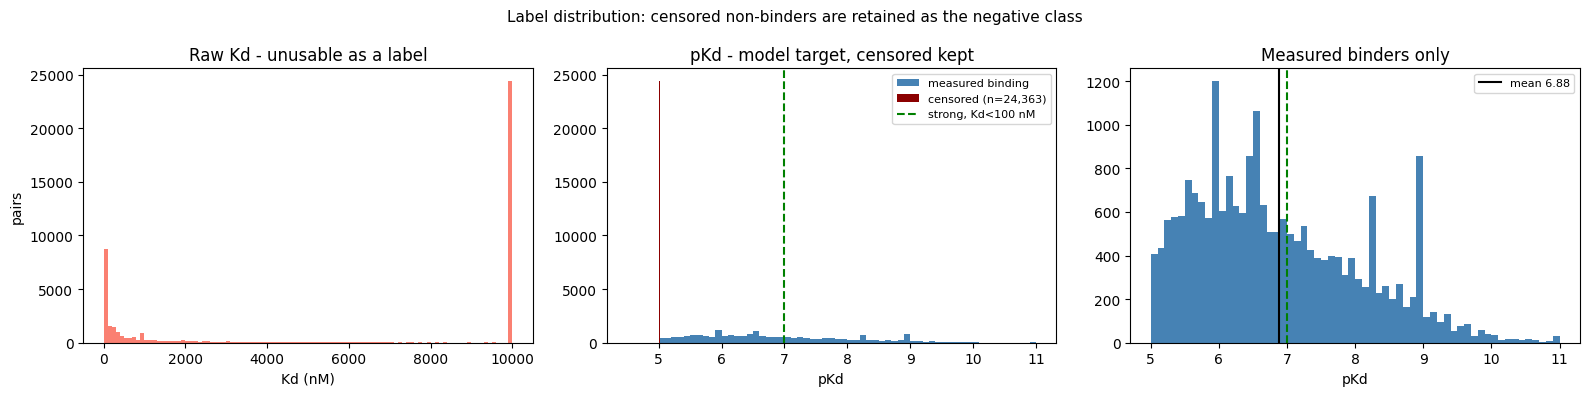

class                                          n   % of data
------------------------------------------------------------
Strong    Kd < 100 nM  (pKd >= 7)          8,747       19.0%
Moderate  100 - 1,000 nM                   7,252       15.7%
Weak      1,000 - 10,000 nM                5,753       12.5%
Non-binder (censored at 10,000 nM)        24,363       52.8%

Class imbalance for the screening task: 19.0% of pairs are strong binders.
This imbalance is biologically real - most drug-protein combinations do not bind.
It is why AUPRC and precision@k are reported alongside RMSE in Section 10.


In [6]:
obs = df_clean[~df_clean["is_censored"]]
cens = df_clean[df_clean["is_censored"]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df_clean["Kd_nM"], bins=100, color="salmon")
axes[0].set(xlabel="Kd (nM)", ylabel="pairs", title="Raw Kd - unusable as a label")

axes[1].hist(obs["pKd"], bins=60, color="steelblue", label="measured binding")
axes[1].hist(cens["pKd"], bins=60, color="darkred", label=f"censored (n={len(cens):,})")
axes[1].axvline(PKD_STRONG, color="green", ls="--", lw=1.5,
                label=f"strong, Kd<{CFG.strong_binder_nm:.0f} nM")
axes[1].set(xlabel="pKd", title="pKd - model target, censored kept")
axes[1].legend(fontsize=8)

axes[2].hist(obs["pKd"], bins=60, color="steelblue")
axes[2].axvline(PKD_STRONG, color="green", ls="--", lw=1.5)
axes[2].axvline(obs["pKd"].mean(), color="black", lw=1.5,
                label=f"mean {obs['pKd'].mean():.2f}")
axes[2].set(xlabel="pKd", title="Measured binders only")
axes[2].legend(fontsize=8)

plt.suptitle("Label distribution: censored non-binders are retained as the negative class",
             fontsize=11)
plt.tight_layout()
plt.show()

n = len(df_clean)
strong = int((df_clean["pKd"] >= PKD_STRONG).sum())
moderate = int(((df_clean["pKd"] >= 6) & (df_clean["pKd"] < PKD_STRONG)).sum())

print(f"{'class':<38}{'n':>10}{'% of data':>12}")
print("-" * 60)
for label, count in [
    (f"Strong    Kd < {CFG.strong_binder_nm:.0f} nM  (pKd >= {PKD_STRONG:.0f})", strong),
    ("Moderate  100 - 1,000 nM", moderate),
    ("Weak      1,000 - 10,000 nM",
     int(((df_clean["pKd"] >= PKD_FLOOR) & (df_clean["pKd"] < 6) & ~df_clean["is_censored"]).sum())),
    (f"Non-binder (censored at {CFG.kd_ceiling_nm:,.0f} nM)", len(cens)),
]:
    print(f"{label:<38}{count:>10,}{count / n * 100:>11.1f}%")

print(f"\nClass imbalance for the screening task: {strong / n * 100:.1f}% of pairs are strong binders.")
print("This imbalance is biologically real - most drug-protein combinations do not bind.")
print("It is why AUPRC and precision@k are reported alongside RMSE in Section 10.")

Top 20 most-measured targets
rank  UniProt     pairs  median pKd  % strong  UniProt link
----------------------------------------------------------------------------------------
   1  P15056        532        6.12       13%  https://www.uniprot.org/uniprot/P15056
   2  (no acc)      454        6.12        1%  -
   3  (no acc)      374        6.60        0%  -
   4  P51449        374        6.89       47%  https://www.uniprot.org/uniprot/P51449
   5  P36888        317        8.30       84%  https://www.uniprot.org/uniprot/P36888
   6  P10721        300        8.30       85%  https://www.uniprot.org/uniprot/P10721
   7  P00918        269        6.85       45%  https://www.uniprot.org/uniprot/P00918
   8  (no acc)      242        7.09       52%  -
   9  P24941        239        5.00        7%  https://www.uniprot.org/uniprot/P24941
  10  Q8K4Z4        211        6.20       33%  https://www.uniprot.org/uniprot/Q8K4Z4
  11  Q9JI35        211        7.60       75%  https://www.uniprot.org/un

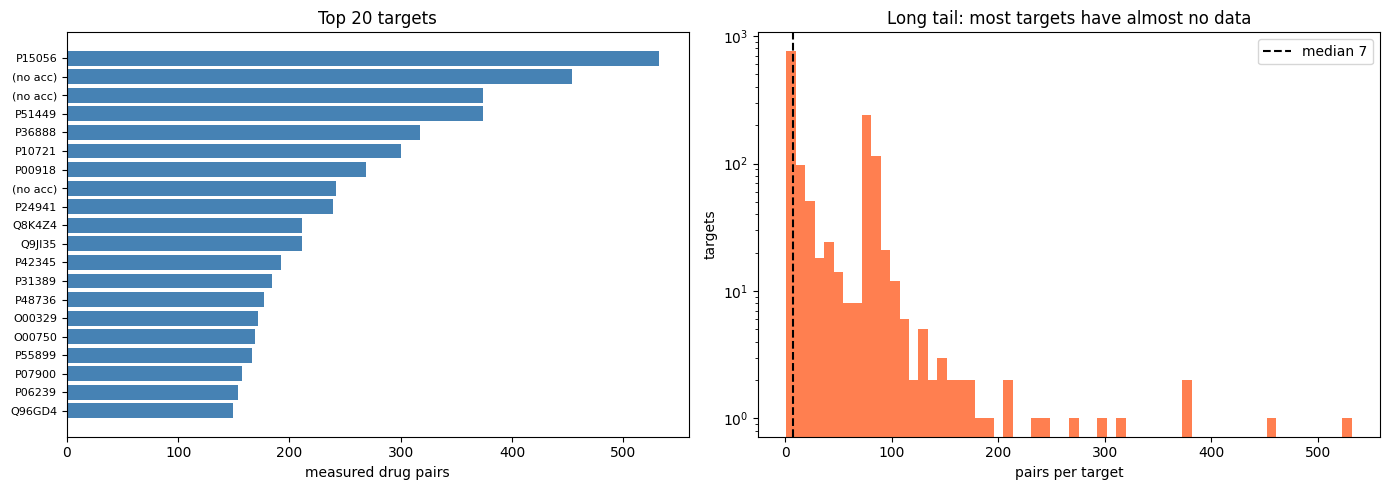

top   5 targets hold   4.4% of all measurements
top  20 targets hold  10.9% of all measurements
top 100 targets hold  28.0% of all measurements

1,413 targets total; 598 have fewer than 5 measurements.

BindingDB is dominated by kinases and GPCRs because that is where
pharmaceutical investment went. Two consequences carried into the
results: the cold-target split in Section 7 is the honest test of whether
the model transfers off this backbone, and any claim about understudied
families is out of scope for this data.


In [7]:
target_stats = (
    df_clean.groupby("target_key")
    .agg(
        Target_ID=("Target_ID", "first"),
        n_pairs=("pKd", "size"),
        median_pKd=("pKd", "median"),
        frac_strong=("pKd", lambda s: float((s >= PKD_STRONG).mean())),
        seq_len=("Target", lambda s: len(s.iloc[0])),
    )
    .sort_values("n_pairs", ascending=False)
    .reset_index()
)

top20 = target_stats.head(20)
print("Top 20 most-measured targets")
print(f"{'rank':>4}  {'UniProt':<10}{'pairs':>7}{'median pKd':>12}{'% strong':>10}  UniProt link")
print("-" * 88)
for i, r in enumerate(top20.itertuples(), 1):
    acc = r.Target_ID if isinstance(r.Target_ID, str) else "(no acc)"
    link = f"https://www.uniprot.org/uniprot/{acc}" if isinstance(r.Target_ID, str) else "-"
    print(f"{i:>4}  {acc:<10}{r.n_pairs:>7,}{r.median_pKd:>12.2f}"
          f"{r.frac_strong * 100:>9.0f}%  {link}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = [a if isinstance(a, str) else "(no acc)" for a in top20["Target_ID"]]
axes[0].barh(range(len(top20)), top20["n_pairs"], color="steelblue")
axes[0].set_yticks(range(len(top20)))
axes[0].set_yticklabels(labels, fontsize=8)
axes[0].invert_yaxis()
axes[0].set(xlabel="measured drug pairs", title="Top 20 targets")

axes[1].hist(target_stats["n_pairs"], bins=60, color="coral")
axes[1].set(xlabel="pairs per target", ylabel="targets", yscale="log",
            title="Long tail: most targets have almost no data")
axes[1].axvline(target_stats["n_pairs"].median(), color="black", ls="--",
                label=f"median {target_stats['n_pairs'].median():.0f}")
axes[1].legend()
plt.tight_layout()
plt.show()

for k in (5, 20, 100):
    share = target_stats.head(k)["n_pairs"].sum() / len(df_clean) * 100
    print(f"top {k:>3} targets hold {share:5.1f}% of all measurements")

print(f"\n{len(target_stats):,} targets total; "
      f"{int((target_stats['n_pairs'] < 5).sum()):,} have fewer than 5 measurements.")
print("\nBindingDB is dominated by kinases and GPCRs because that is where")
print("pharmaceutical investment went. Two consequences carried into the")
print("results: the cold-target split in Section 7 is the honest test of whether")
print("the model transfers off this backbone, and any claim about understudied")
print("families is out of scope for this data.")

[cache hit ] drug_descriptors__38b2c0359d.parquet
Molecule size across the dataset
  mean heavy atoms   : 38.8
  range              : 5 - 389
  above 60 atoms     : 1,160 (10.9%)

With 3 message-passing layers each atom sees 3 bonds out.
For large molecules that means the receptive field does not span the
structure - under-reaching, not over-smoothing. Over-smoothing is the
opposite failure and needs many more layers than are used here.

Descriptor comparison, strong binders vs everything else
            strong_binders    rest  cohens_d
MW                  533.34  472.98      0.23
cLogP                 3.52    3.66     -0.05
TPSA                123.54  106.62      0.15
HBD                   3.01    2.53      0.13
HBA                   6.73    6.38      0.07
RotB                  8.31    6.86      0.19
Rings                 4.48    4.17      0.21
HeavyAtoms           37.73   33.44      0.24

Effect sizes near zero mean molecular size and lipophilicity alone do
not separate binders from

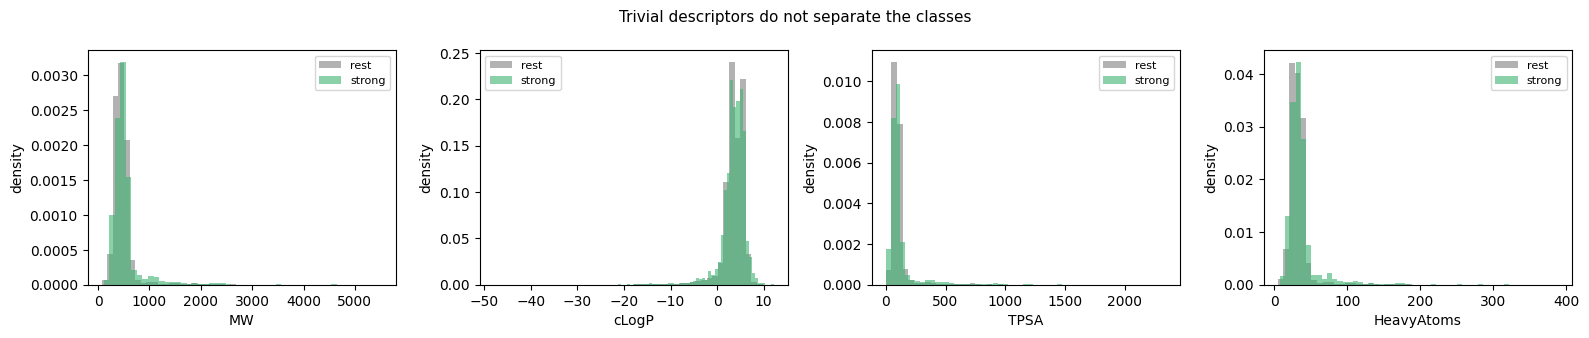

In [8]:
DESCRIPTORS = {
    "MW": Descriptors.MolWt,
    "cLogP": Descriptors.MolLogP,
    "TPSA": Descriptors.TPSA,
    "HBD": Descriptors.NumHDonors,
    "HBA": Descriptors.NumHAcceptors,
    "RotB": Descriptors.NumRotatableBonds,
    "Rings": Descriptors.RingCount,
    "HeavyAtoms": Descriptors.HeavyAtomCount,
}


def describe_smiles(smiles_list) -> pd.DataFrame:
    rows = []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        rows.append({"smiles": smi, **{k: f(mol) for k, f in DESCRIPTORS.items()}})
    return pd.DataFrame(rows)


desc = cached("drug_descriptors", lambda: describe_smiles(df_clean["smiles"].unique()))
pairs_desc = df_clean.merge(desc, on="smiles", how="left")

print("Molecule size across the dataset")
print(f"  mean heavy atoms   : {desc['HeavyAtoms'].mean():.1f}")
print(f"  range              : {desc['HeavyAtoms'].min():.0f} - {desc['HeavyAtoms'].max():.0f}")
print(f"  above 60 atoms     : {int((desc['HeavyAtoms'] > 60).sum()):,} "
      f"({(desc['HeavyAtoms'] > 60).mean() * 100:.1f}%)")
print(f"\nWith {CFG.n_gnn_layers} message-passing layers each atom sees "
      f"{CFG.n_gnn_layers} bonds out.")
print("For large molecules that means the receptive field does not span the")
print("structure - under-reaching, not over-smoothing. Over-smoothing is the")
print("opposite failure and needs many more layers than are used here.")

# Shortcut control: how separable are strong and weak binders on trivial
# descriptors alone? A large gap means a model could score well without
# learning anything about binding.
strong_mask = pairs_desc["pKd"] >= PKD_STRONG
desc_cols = list(DESCRIPTORS)
summary = pd.DataFrame({
    "strong_binders": pairs_desc.loc[strong_mask, desc_cols].mean(),
    "rest": pairs_desc.loc[~strong_mask, desc_cols].mean(),
})
pooled = pairs_desc[desc_cols].std()
summary["cohens_d"] = ((summary["strong_binders"] - summary["rest"]) / pooled).round(2)

print("\nDescriptor comparison, strong binders vs everything else")
print(summary.round(2).to_string())
print("\nEffect sizes near zero mean molecular size and lipophilicity alone do")
print("not separate binders from non-binders, so the GNN cannot get a good")
print("score by learning 'bigger is stickier'. Section 11 tests this directly")
print("with a descriptors-only model.")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, ["MW", "cLogP", "TPSA", "HeavyAtoms"]):
    ax.hist(pairs_desc.loc[~strong_mask, col], bins=50, alpha=0.6,
            density=True, label="rest", color="grey")
    ax.hist(pairs_desc.loc[strong_mask, col], bins=50, alpha=0.6,
            density=True, label="strong", color="mediumseagreen")
    ax.set(xlabel=col, ylabel="density")
    ax.legend(fontsize=8)
plt.suptitle("Trivial descriptors do not separate the classes", fontsize=11)
plt.tight_layout()
plt.show()

TIGHTEST measured: Kd = 0.01 nM, pKd = 11.00, from 1 measurement(s)
   MW=364.41, cLogP=1.93, HBD=3, HBA=4, heavy_atoms=27, aromatic_atoms=12, rings=3, violations=0
WEAKEST measured: Kd = 9920 nM, pKd = 5.00, from 1 measurement(s)
   MW=387.82, cLogP=2.96, HBD=2, HBA=6, heavy_atoms=27, aromatic_atoms=17, rings=3, violations=0


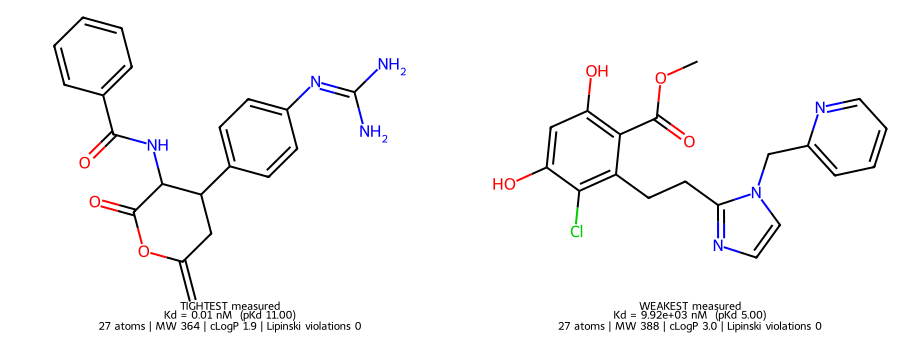


A single pair of molecules is an illustration, not evidence. The
distributional comparison in the previous cell is the actual test of
whether structure separates the classes.


In [9]:
measured = df_clean[~df_clean["is_censored"]]

# Genuinely the tightest and the weakest *measured* pairs. Selecting by
# position rather than by value silently picks an arbitrary row.
tightest = measured.loc[measured["pKd"].idxmax()]
weakest = measured.loc[measured["pKd"].idxmin()]


def lipinski_report(mol) -> dict:
    mw, logp = Descriptors.MolWt(mol), Descriptors.MolLogP(mol)
    hbd, hba = Descriptors.NumHDonors(mol), Descriptors.NumHAcceptors(mol)
    return {
        "MW": mw, "cLogP": logp, "HBD": hbd, "HBA": hba,
        "heavy_atoms": mol.GetNumHeavyAtoms(),
        "aromatic_atoms": sum(1 for a in mol.GetAtoms() if a.GetIsAromatic()),
        "rings": mol.GetRingInfo().NumRings(),
        "violations": int(mw > 500) + int(logp > 5) + int(hbd >= 5) + int(hba >= 10),
    }


mols, legends = [], []
for name, row in [("TIGHTEST measured", tightest), ("WEAKEST measured", weakest)]:
    mol = Chem.MolFromSmiles(row["smiles"])
    rep = lipinski_report(mol)
    mols.append(mol)
    legends.append(
        f"{name}\nKd = {row['Kd_nM']:.3g} nM  (pKd {row['pKd']:.2f})\n"
        f"{rep['heavy_atoms']} atoms | MW {rep['MW']:.0f} | "
        f"cLogP {rep['cLogP']:.1f} | Lipinski violations {rep['violations']}"
    )
    print(f"{name}: Kd = {row['Kd_nM']:.4g} nM, pKd = {row['pKd']:.2f}, "
          f"from {int(row['n_measurements'])} measurement(s)")
    print("   " + ", ".join(f"{k}={v:.2f}" if isinstance(v, float) else f"{k}={v}"
                            for k, v in rep.items()))

display(Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(460, 350), legends=legends))

print("\nA single pair of molecules is an illustration, not evidence. The")
print("distributional comparison in the previous cell is the actual test of")
print("whether structure separates the classes.")

In [10]:
n_drugs = df_clean["smiles"].nunique()
n_targets = df_clean["target_key"].nunique()
n_measured = len(df_clean)
full_matrix = n_drugs * n_targets

print(f"unique drugs      : {n_drugs:,}")
print(f"unique targets    : {n_targets:,}")
print(f"measured pairs    : {n_measured:,}")
print(f"full matrix       : {full_matrix:,}")
print(f"fraction measured : {n_measured / full_matrix * 100:.4f}%")
print(f"\nEven within the proteins and compounds BindingDB already covers,")
print(f"{100 - n_measured / full_matrix * 100:.2f}% of combinations have never been tested.")
print("Predicting that space is the point of the model - but only if it can")
print("be shown to generalise, which is what Sections 13 and 14 measure.")

RUN_INFO["matrix"] = {
    "n_drugs": int(n_drugs),
    "n_targets": int(n_targets),
    "n_measured": int(n_measured),
    "pct_measured": float(n_measured / full_matrix * 100),
}

unique drugs      : 10,659
unique targets    : 1,413
measured pairs    : 46,115
full matrix       : 15,061,167
fraction measured : 0.3062%

Even within the proteins and compounds BindingDB already covers,
99.69% of combinations have never been tested.
Predicting that space is the point of the model - but only if it can
be shown to generalise, which is what Sections 13 and 14 measure.


---

# Section 5 — Broad Repurposing Hub

Approved and clinical-stage compounds with mechanism of action, clinical phase
and annotated targets. No Kd labels, so this is never training data. It has
two distinct jobs, and conflating them costs compounds:

- **Validation set** — compounds that also appear in BindingDB, used as
  out-of-sample anchors. Needs SMILES *and* an annotated target.
- **Screening library** — everything we can draw a structure for. Needs
  **SMILES only**.

Filtering the whole Hub on `target` being present, as is commonly done,
discards roughly a third of the library from the screen for no reason: the
model predicts the target, it does not need to be told it.

## One row per compound

`repurposing_samples` lists every vendor sample, so a compound appears many
times. Merging it into `repurposing_drugs` on `pert_iname` multiplies rows and
silently inflates every count downstream. Deduplicate the samples file to one
SMILES per compound *before* merging.

In [11]:
HUB_URLS = {
    "repurposing_drugs.txt":
        "https://s3.amazonaws.com/data.clue.io/repurposing/downloads/repurposing_drugs_20200324.txt",
    "repurposing_samples.txt":
        "https://s3.amazonaws.com/data.clue.io/repurposing/downloads/repurposing_samples_20200324.txt",
}

API_FAILURES: list = []


def http_get(url: str, *, timeout: int = 60, retries: int = 3, **kwargs):
    """GET with retries. Failures are recorded, never silently swallowed."""
    last = None
    for attempt in range(retries):
        try:
            r = requests.get(url, timeout=timeout, **kwargs)
            if r.ok:
                return r
            last = f"HTTP {r.status_code}"
        except Exception as exc:
            last = repr(exc)
        time.sleep(1.5 * (attempt + 1))
    API_FAILURES.append({"url": url, "error": last})
    print(f"  [api fail] {url} -> {last}")
    return None


def download_to_cache(filename: str, url: str) -> Path:
    dest = CACHE / filename
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    resp = http_get(url)
    if resp is None:
        raise RuntimeError(f"could not download {url}")
    dest.write_bytes(resp.content)
    return dest


def load_repurposing_hub() -> pd.DataFrame:
    paths = {name: download_to_cache(name, url) for name, url in HUB_URLS.items()}
    read = dict(sep="\t", comment="!", encoding="latin-1", low_memory=False)
    drugs = pd.read_csv(paths["repurposing_drugs.txt"], **read)
    samples = pd.read_csv(paths["repurposing_samples.txt"], **read)

    naive_rows = len(drugs.merge(samples[["pert_iname", "smiles"]],
                                 on="pert_iname", how="left"))

    # Pick one structure per compound *before* merging, otherwise every vendor
    # sample becomes its own row and all downstream counts are inflated.
    one_smiles = (
        samples.dropna(subset=["smiles"])
        .drop_duplicates(subset=["pert_iname"], keep="first")[["pert_iname", "smiles"]]
    )
    merged = (
        drugs.drop_duplicates(subset=["pert_iname"], keep="first")
        .merge(one_smiles, on="pert_iname", how="left")
    )
    merged = merged.assign(smiles_canonical=merged["smiles"].map(canonical_smiles))
    merged.attrs["naive_merge_rows"] = naive_rows
    merged.attrs["drugs_rows"] = len(drugs)
    return merged


hub_all = load_repurposing_hub()

print(f"compounds in repurposing_drugs       : {hub_all.attrs['drugs_rows']:,}")
print(f"rows a naive merge would have made   : {hub_all.attrs['naive_merge_rows']:,}"
      f"   <- vendor samples multiply rows")
print(f"rows after one structure per compound: {len(hub_all):,}")
print(f"parseable structures                 : {int(hub_all['smiles_canonical'].notna().sum()):,}")
print(f"with an annotated target             : {int(hub_all['target'].notna().sum()):,}")
print("\nThe screening library and the validation subset are built in Section 6,")
print("once structures have been standardised.")

compounds in repurposing_drugs       : 6,798
rows a naive merge would have made   : 13,553   <- vendor samples multiply rows
rows after one structure per compound: 6,798
parseable structures                 : 6,776
with an annotated target             : 4,382

The screening library and the validation subset are built in Section 6,
once structures have been standardised.


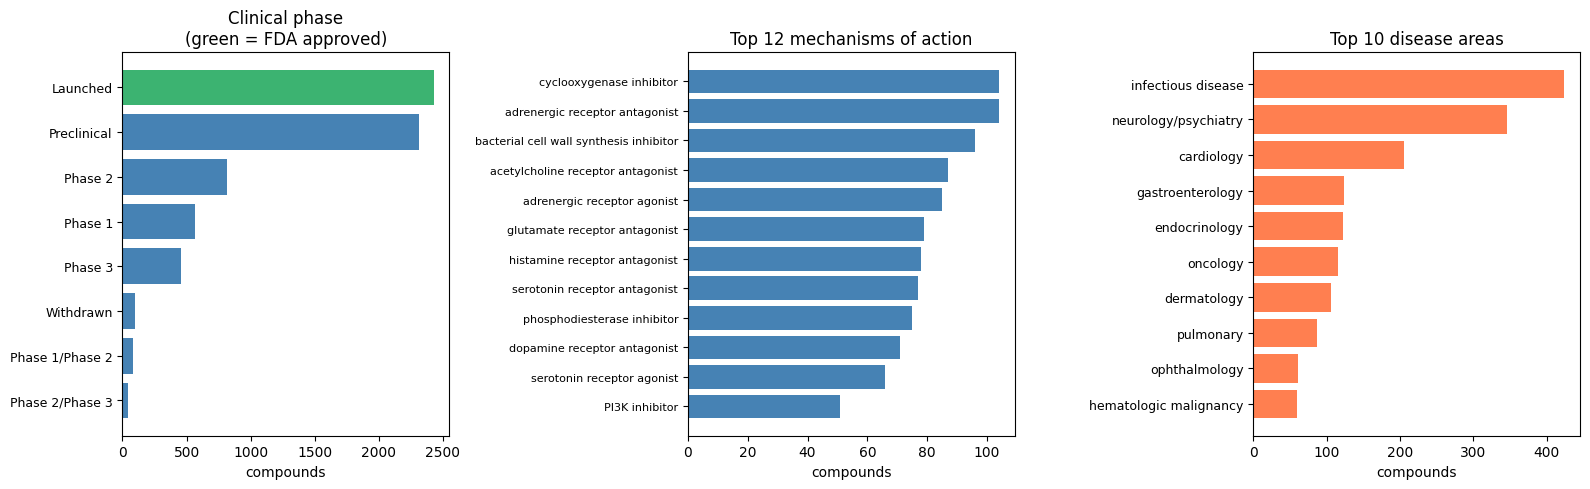

FDA approved ('Launched')   : 2,427 (35.7%)
unique mechanisms of action : 1,436
unique disease areas        : 216

These compounds already have human safety data. That is the entire value
of repurposing: a confirmed hit skips Phase I rather than starting from a
new chemical entity.


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

phase = hub_all["clinical_phase"].value_counts().head(8)
axes[0].barh(range(len(phase)), phase.values,
             color=["mediumseagreen" if "Launch" in str(p) else "steelblue"
                    for p in phase.index])
axes[0].set_yticks(range(len(phase)))
axes[0].set_yticklabels(phase.index, fontsize=9)
axes[0].invert_yaxis()
axes[0].set(xlabel="compounds", title="Clinical phase\n(green = FDA approved)")

moa = hub_all["moa"].value_counts().head(12)
axes[1].barh(range(len(moa)), moa.values, color="steelblue")
axes[1].set_yticks(range(len(moa)))
axes[1].set_yticklabels(moa.index, fontsize=8)
axes[1].invert_yaxis()
axes[1].set(xlabel="compounds", title="Top 12 mechanisms of action")

disease = hub_all["disease_area"].value_counts().head(10)
axes[2].barh(range(len(disease)), disease.values, color="coral")
axes[2].set_yticks(range(len(disease)))
axes[2].set_yticklabels(disease.index, fontsize=9)
axes[2].invert_yaxis()
axes[2].set(xlabel="compounds", title="Top 10 disease areas")

plt.tight_layout()
plt.show()

n_launched = int((hub_all["clinical_phase"] == "Launched").sum())
print(f"FDA approved ('Launched')   : {n_launched:,} "
      f"({n_launched / len(hub_all) * 100:.1f}%)")
print(f"unique mechanisms of action : {hub_all['moa'].nunique():,}")
print(f"unique disease areas        : {hub_all['disease_area'].nunique():,}")
print("\nThese compounds already have human safety data. That is the entire value")
print("of repurposing: a confirmed hit skips Phase I rather than starting from a")
print("new chemical entity.")

---

# Section 6 — Bridge compounds: matching the two datasets properly

Compounds present in both BindingDB and the Hub are the retrospective
validation anchors: measured Kd on one side, clinical annotation on the other.
Finding them requires matching structures across two databases that were
curated independently.

## Why exact SMILES matching undercounts badly

The two sources differ in ways that are chemically irrelevant but change the
string: salt forms (`imatinib` vs `imatinib mesylate`), protonation state,
tautomer choice, stereochemistry annotation. Intersecting canonical SMILES strings finds 460 matches; the standardisation below recovers 159 more (619 in total).

The fix is a standardisation pipeline before comparison:

1. `Cleanup` — sanitise, normalise functional groups, disconnect metals.
2. `LargestFragmentChooser` — drop counter-ions, keep the active species.
3. `Uncharger` — neutralise so a hydrochloride matches its free base.
4. **InChIKey, first block only.** The first 14 characters encode the
   molecular skeleton and connectivity; the second block encodes stereo,
   isotopes and protonation. Matching on block one treats stereoisomers and
   salt forms as the same compound, which is what we want when asking "is this
   drug in both databases".

Block-one matching is deliberately permissive. It is right for *finding
anchors*, and would be wrong for a structure-activity claim where
stereochemistry matters.

## These anchors are forced into the test set

Predicting affinity for a pair that was in the training set is memorisation,
not validation. Section 7 forces every bridge compound into the test split so
retrospective validation is genuinely out of sample. The decision has to be
made here, before splitting.

In [13]:
_LARGEST_FRAGMENT = rdMolStandardize.LargestFragmentChooser()
_UNCHARGER = rdMolStandardize.Uncharger()
_skeleton_cache: dict = {}
_scaffold_cache: dict = {}


def standardize_mol(smi):
    """Sanitise, strip counter-ions, neutralise. Returns a Mol or None."""
    if not isinstance(smi, str) or not smi:
        return None
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    try:
        mol = rdMolStandardize.Cleanup(mol)
        mol = _LARGEST_FRAGMENT.choose(mol)
        mol = _UNCHARGER.uncharge(mol)
    except Exception:
        return None
    return mol


def inchikey_skeleton(smi):
    """First block of the InChIKey: skeleton and connectivity only, ignoring
    stereochemistry, isotopes, protonation state and salt form."""
    if smi in _skeleton_cache:
        return _skeleton_cache[smi]
    mol = standardize_mol(smi)
    key = None
    if mol is not None:
        try:
            full = Chem.MolToInchiKey(mol)
            key = full.split("-")[0] if full else None
        except Exception:
            key = None
    _skeleton_cache[smi] = key
    return key


def bemis_murcko_scaffold(smi: str) -> str:
    """Ring-system skeleton, used for the scaffold split. Acyclic molecules
    are pooled under a single label."""
    if smi in _scaffold_cache:
        return _scaffold_cache[smi]
    try:
        scaf = MurckoScaffold.MurckoScaffoldSmiles(smiles=smi, includeChirality=False)
    except Exception:
        scaf = None
    scaf = scaf if scaf else "acyclic"
    _scaffold_cache[smi] = scaf
    return scaf


def with_skeleton(df: pd.DataFrame, col: str) -> pd.DataFrame:
    mapping = {s: inchikey_skeleton(s) for s in df[col].dropna().unique()}
    return df.assign(skeleton=df[col].map(mapping))


# --- Build the two Hub frames -------------------------------------------
# Screening needs a structure and nothing else. Only the validation subset
# needs an annotated target.
hub_screen = with_skeleton(
    hub_all[hub_all["smiles_canonical"].notna()].reset_index(drop=True),
    "smiles_canonical",
)
hub_validate = hub_screen[hub_screen["target"].notna()].reset_index(drop=True)

# --- Match the two databases ---------------------------------------------
bdb_skeletons = {inchikey_skeleton(s) for s in df_clean["smiles"].unique()}
bdb_skeletons.discard(None)

overlap_exact = set(df_clean["smiles"]) & set(hub_screen["smiles_canonical"])
overlap_skeleton = bdb_skeletons & set(hub_screen["skeleton"].dropna())

print("Matching BindingDB against the Repurposing Hub\n")
print(f"{'method':<36}{'compounds matched':>18}")
print("-" * 54)
print(f"{'canonical SMILES equality':<36}{len(overlap_exact):>18,}")
print(f"{'standardised InChIKey block 1':<36}{len(overlap_skeleton):>18,}")
gain = len(overlap_skeleton) - len(overlap_exact)
print(f"\nStandardising salt form, charge and stereochemistry recovers "
      f"{gain:,} extra bridge compounds.")

# --- The single analysis frame everything downstream uses -----------------
df_pairs = with_skeleton(df_clean, "smiles")
df_pairs = df_pairs.assign(
    scaffold=df_pairs["smiles"].map(bemis_murcko_scaffold),
    is_bridge=df_pairs["skeleton"].isin(overlap_skeleton),
)
hub_screen = hub_screen.assign(in_bindingdb=hub_screen["skeleton"].isin(bdb_skeletons))

print(f"\nSCREENING library (structure only)      : {len(hub_screen):,}")
print(f"VALIDATION subset (structure + target)  : {len(hub_validate):,}")
print(f"  kept for screening that a target filter would have discarded: "
      f"{len(hub_screen) - len(hub_validate):,}")
print(f"  never measured in BindingDB                                 : "
      f"{int((~hub_screen['in_bindingdb']).sum()):,}   <- the novel screening space")

bridge_pairs = int(df_pairs["is_bridge"].sum())
print(f"\nBindingDB pairs involving a bridge compound : {bridge_pairs:,} "
      f"({bridge_pairs / len(df_pairs) * 100:.1f}% of the data)")
print(f"distinct Bemis-Murcko scaffolds             : {df_pairs['scaffold'].nunique():,}")

RUN_INFO["bridge"] = {
    "exact_smiles_matches": len(overlap_exact),
    "skeleton_matches": len(overlap_skeleton),
    "bindingdb_pairs_involving_bridge": bridge_pairs,
}

# --- Worked example -------------------------------------------------------
if bridge_pairs:
    counts = df_pairs[df_pairs["is_bridge"]].groupby("skeleton").size().sort_values()
    example = counts.index[-1]
    ex_pairs = df_pairs[df_pairs["skeleton"] == example]
    ex_hub = hub_screen[hub_screen["skeleton"] == example].iloc[0]
    ex_obs = ex_pairs[~ex_pairs["is_censored"]]

    print(f"\n{'=' * 72}\nWORKED EXAMPLE: {ex_hub['pert_iname']}\n{'=' * 72}")
    print(f"Hub        phase      : {ex_hub['clinical_phase']}")
    print(f"           mechanism  : {ex_hub['moa']}")
    print(f"           indication : {ex_hub.get('indication', 'n/a')}")
    print(f"           targets    : {str(ex_hub['target'])[:90]}")
    print(f"BindingDB  {len(ex_pairs)} measured pairs "
          f"({len(ex_obs)} binders, {len(ex_pairs) - len(ex_obs)} non-binders)")
    if len(ex_obs):
        print(f"           Kd range   : {ex_obs['Kd_nM'].min():.3g} - "
              f"{ex_obs['Kd_nM'].max():.3g} nM")
    print("\nThe Hub says what the drug is used for; BindingDB says how tightly it")
    print("binds. Neither on its own supports a repurposing hypothesis.")

Matching BindingDB against the Repurposing Hub

method                               compounds matched
------------------------------------------------------
canonical SMILES equality                          460
standardised InChIKey block 1                      619

Standardising salt form, charge and stereochemistry recovers 159 extra bridge compounds.

SCREENING library (structure only)      : 6,776
VALIDATION subset (structure + target)  : 4,366
  kept for screening that a target filter would have discarded: 2,410
  never measured in BindingDB                                 : 6,127   <- the novel screening space

BindingDB pairs involving a bridge compound : 27,720 (60.1% of the data)
distinct Bemis-Murcko scaffolds             : 4,903

WORKED EXAMPLE: sunitinib
Hub        phase      : Launched
           mechanism  : FLT3 inhibitor|KIT inhibitor|PDGFR tyrosine kinase receptor inhibitor|RET tyrosine kinase inhibitor|VEGFR inhibitor
           indication : gastrointestinal stromal

---

# Section 7 — Splits: one source of truth, four regimes

The previous version of this analysis called `data.get_split()` on the raw TDC
object *after* cleaning a separate frame. The splits therefore still contained
the duplicates and unparseable structures that had been removed from the
analysis frame, and the model was trained on a dataset that was never the one
described. `make_splits()` below partitions `df_clean` directly, so there is
exactly one dataset in the notebook.

## Four regimes, because "generalisation" means different things

| Regime | Held out | Question it answers |
| --- | --- | --- |
| `random` | random pairs, except bridge compounds are forced into test | Comparability with published numbers. Optimistic; test is about 60% of pairs. |
| `cold_drug` | whole compounds | Can it predict for chemistry it has not seen? |
| `scaffold` | whole Bemis-Murcko scaffolds | Same, but stricter. |
| `cold_target` | whole proteins | Can it transfer to a protein it has not seen? |

**Why scaffold is stricter than cold_drug.** A cold-drug split only guarantees
the exact SMILES differs. BindingDB is built largely from medicinal chemistry
series, so a test compound is frequently an analog of a training compound
differing by one substituent. The model can interpolate within the series and
look better than it is. Splitting on the Bemis-Murcko scaffold holds out the
whole series.

**Expect cold_target to be harder, and read it with care.** Half of the stated goal is scoring proteins the model has never seen. Reporting that honestly is more valuable than quoting the random-split number alone. Test sets also differ in composition between regimes (about 53% censored in cold_target against about 69% in the drug-based regimes), so metrics are not strictly comparable across regimes.

## Bridge compounds are forced into test

Every compound shared with the Repurposing Hub is pushed into the test set for
the drug-based regimes. Retrospective validation on a pair the model trained on
measures memorisation. This has to happen at split time, which is why
Section 6 ran first.

  [random] note: 27,720 forced rows exceed the nominal test share; test is larger than 20%
  [cold_drug] note: 27,720 forced rows exceed the nominal test share; test is larger than 20%
  [scaffold] note: 30,723 forced rows exceed the nominal test share; test is larger than 20%
                   pairs  drugs  targets  pct_censored  pct_strong  mean_pKd
regime      split                                                           
random      train  16096   9070     1254          28.3        32.7      6.45
            valid   2299   1803      678          30.2        31.1      6.39
            test   27720    673      851          68.9        10.0      5.52
cold_drug   train  16083   8736     1234          28.9        32.4      6.43
            valid   2312   1250      806          26.5        33.5      6.51
            test   27720    673      851          68.9        10.0      5.52
scaffold    train  13465   7750     1152          24.8        35.6      6.55
            valid   1927    7

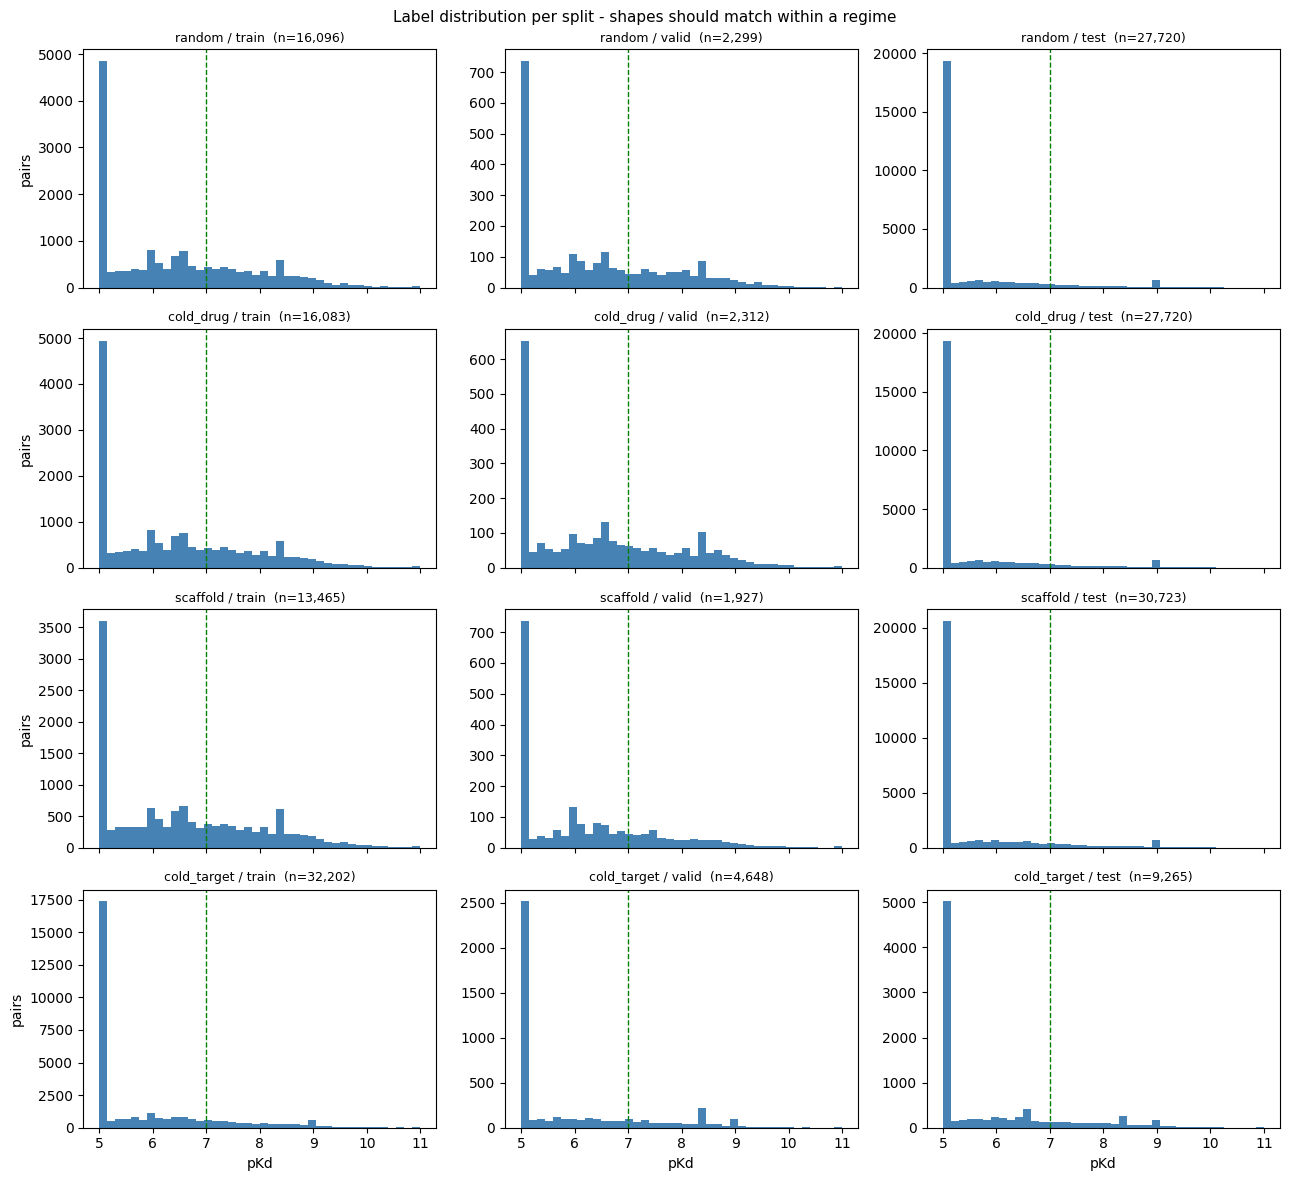

In [14]:
# Which column defines a group that must not straddle two splits.
SPLIT_REGIMES = {
    "random": None,
    "cold_drug": "smiles",
    "scaffold": "scaffold",
    "cold_target": "target_key",
}
DRUG_BASED_REGIMES = ("random", "cold_drug", "scaffold")


def make_splits(df: pd.DataFrame, method: str, seed: int = None,
                cfg: Config = CFG, force_test_mask=None) -> dict:
    """Partition `df` into train/valid/test. Returns new frames; `df` is untouched.

    Groups defined by the regime's key are assigned whole, so a compound (or
    scaffold, or protein) can never appear on both sides. `force_test_mask`
    pins the rows it selects - and everything sharing their group - into test.
    """
    if method not in SPLIT_REGIMES:
        raise ValueError(f"unknown split method {method!r}")
    seed = cfg.seed if seed is None else seed

    work = df.reset_index(drop=True).copy()
    key = SPLIT_REGIMES[method]
    if key is None:  # random: every row is its own group
        key = "_row_id"
        work[key] = np.arange(len(work))

    sizes = work.groupby(key).size()
    forced = set()
    if force_test_mask is not None:
        mask = np.asarray(force_test_mask, dtype=bool)
        forced = set(work.loc[mask, key])

    rng = np.random.default_rng(seed)
    free = np.array([g for g in sizes.index if g not in forced], dtype=object)
    rng.shuffle(free)

    n_total = len(work)
    n_forced = int(sum(sizes[g] for g in forced))
    n_free = n_total - n_forced

    # Budgets are computed over the rows still available. If the forced rows
    # already exceed the test share, test simply ends up larger and the
    # remainder is divided between train and valid in the configured ratio -
    # rather than starving train, which an absolute budget would do.
    test_budget = max(0, round(n_total * (1.0 - cfg.frac_train - cfg.frac_valid)) - n_forced)
    after_test = max(0, n_free - test_budget)
    valid_budget = round(after_test * cfg.frac_valid / (cfg.frac_train + cfg.frac_valid))

    assignment = {g: "test" for g in forced}
    filled = 0
    i = 0
    while filled < test_budget and i < len(free):
        assignment[free[i]] = "test"
        filled += int(sizes[free[i]])
        i += 1
    filled = 0
    while filled < valid_budget and i < len(free):
        assignment[free[i]] = "valid"
        filled += int(sizes[free[i]])
        i += 1
    for g in free[i:]:
        assignment[g] = "train"

    if n_forced > round(n_total * (1.0 - cfg.frac_train - cfg.frac_valid)):
        print(f"  [{method}] note: {n_forced:,} forced rows exceed the nominal test "
              f"share; test is larger than {1 - cfg.frac_train - cfg.frac_valid:.0%}")

    work["_split"] = work[key].map(assignment)
    drop = ["_split"] + (["_row_id"] if "_row_id" in work.columns else [])
    return {
        name: work[work["_split"] == name].drop(columns=drop).reset_index(drop=True)
        for name in ("train", "valid", "test")
    }


def assert_split_valid(splits: dict, method: str) -> None:
    key = SPLIT_REGIMES[method]
    frames = {k: v for k, v in splits.items()}
    total = sum(len(v) for v in frames.values())

    seen_pairs = set()
    for name, frame in frames.items():
        assert len(frame) > 0, (
            f"{method}/{name} is empty - with these split fractions and forced "
            f"test rows there is nothing left to {name} on"
        )
        assert frame["pKd"].notna().all(), f"{method}/{name}: NaN label"
        assert frame["pKd"].between(PKD_FLOOR, PKD_CEIL).all(), f"{method}/{name}: pKd out of bounds"
        pairs = set(zip(frame["smiles"], frame["target_key"]))
        assert not (pairs & seen_pairs), f"{method}/{name}: pair appears in two splits"
        seen_pairs |= pairs

    if key is not None:
        groups = {name: set(frame[key]) for name, frame in frames.items()}
        for a, b in (("train", "valid"), ("train", "test"), ("valid", "test")):
            shared = groups[a] & groups[b]
            assert not shared, f"{method}: {len(shared)} {key} values shared by {a}/{b}"
    return total


def describe_splits(splits: dict, method: str) -> pd.DataFrame:
    rows = []
    for name, frame in splits.items():
        rows.append({
            "split": name,
            "pairs": len(frame),
            "drugs": frame["smiles"].nunique(),
            "targets": frame["target_key"].nunique(),
            "pct_censored": round(frame["is_censored"].mean() * 100, 1),
            "pct_strong": round((frame["pKd"] >= PKD_STRONG).mean() * 100, 1),
            "mean_pKd": round(frame["pKd"].mean(), 2),
        })
    return pd.DataFrame(rows).assign(regime=method)


ALL_SPLITS = {}
for method in SPLIT_REGIMES:
    mask = df_pairs["is_bridge"] if method in DRUG_BASED_REGIMES else None
    sp = make_splits(df_pairs, method, force_test_mask=mask)
    total = assert_split_valid(sp, method)
    assert total == len(df_pairs), f"{method}: {total} rows out of {len(df_pairs)}"
    ALL_SPLITS[method] = sp

summary = pd.concat([describe_splits(sp, m) for m, sp in ALL_SPLITS.items()])
print(summary.set_index(["regime", "split"]).to_string())

print("\nAll four regimes pass: groups disjoint, every row assigned once,")
print("no (drug, target) pair in two splits, all labels finite and in bounds.")

for method in DRUG_BASED_REGIMES:
    sp = ALL_SPLITS[method]
    leaked = int(sp["train"]["is_bridge"].sum() + sp["valid"]["is_bridge"].sum())
    assert leaked == 0, f"{method}: {leaked} bridge rows leaked out of test"
print(f"Bridge compounds ({int(df_pairs['is_bridge'].sum()):,} pairs) held out of "
      f"train and valid in every drug-based regime.")

fig, axes = plt.subplots(len(SPLIT_REGIMES), 3, figsize=(13, 3.0 * len(SPLIT_REGIMES)),
                         sharex=True)
for row, (method, sp) in enumerate(ALL_SPLITS.items()):
    for col, name in enumerate(("train", "valid", "test")):
        ax = axes[row, col]
        ax.hist(sp[name]["pKd"], bins=40, color="steelblue")
        ax.axvline(PKD_STRONG, color="green", ls="--", lw=1)
        ax.set_title(f"{method} / {name}  (n={len(sp[name]):,})", fontsize=9)
        if col == 0:
            ax.set_ylabel("pairs")
        if row == len(SPLIT_REGIMES) - 1:
            ax.set_xlabel("pKd")
plt.suptitle("Label distribution per split - shapes should match within a regime", fontsize=11)
plt.tight_layout()
plt.show()

RUN_INFO["splits"] = {
    m: {k: int(len(v)) for k, v in sp.items()} for m, sp in ALL_SPLITS.items()
}

---

# Section 8 — The protein branch

This is the change that makes the project able to answer its own question.

A graph neural network over the ligand alone maps a molecule to a number. Run
it against a thousand different proteins and it returns the same number a
thousand times. It cannot rank targets, so "screen these compounds against
targets they have never been tested against" is not something it can do, even
in principle. Worse, during training the same drug appears against many
targets with genuinely different affinities, so the best a ligand-only model
can do is regress toward each compound's mean — the target-dependent variance
becomes irreducible error.

## ESM-2 embeddings

Each target sequence goes through ESM-2 and is mean-pooled over residues into
a single fixed-length vector. A protein language model trained on UniRef puts
sequences with similar structure and function near each other, which is what
lets the model generalise to a protein it has not seen — the basis of the
cold-target regime.

Practical notes for the free Colab tier:

- **Computed once, cached forever.** There are only ~1,400 unique targets. The
  store is an incremental `.npz` on Drive keyed by a hash of the sequence, and
  it is flushed periodically during the run, so a session dying part-way
  through costs only the batches since the last flush.
- **`esm2_t12_35M_UR50D` is the default** because it fits comfortably on a T4. Switch `Config.esm_model` to
  `esm2_t33_650M_UR50D` for potentially better target representations; it is expected to fit a T4 in half precision (not tested here). Changing the model changes the cache filename,
  so both can coexist.
- **Sequences are truncated to 1,022 residues.** Attention memory grows
  quadratically with length. Most kinase and GPCR targets fit; for the long
  ones we lose C-terminal sequence, which is a real limitation and is recorded
  in the run manifest.

## Alternatives considered

A 1D CNN over one-hot amino acids (the DeepDTA approach) trains from scratch
and needs far more data per target than the long tail here provides. A
one-hot target ID would work for known proteins but cannot generalise to an
unseen one, which defeats the purpose.

In [15]:
def esm_store_path(cfg: Config = CFG) -> Path:
    return CACHE / f"esm__{cfg.esm_model}__len{cfg.esm_max_len}.npz"


def _load_esm(cfg: Config = CFG):
    import esm

    if not hasattr(esm.pretrained, cfg.esm_model):
        raise ValueError(f"unknown ESM model {cfg.esm_model!r}")
    model, alphabet = getattr(esm.pretrained, cfg.esm_model)()
    model = model.to(DEVICE).eval()
    if DEVICE.type == "cuda":
        model = model.half()  # halves memory, no measurable quality cost here
    return model, alphabet.get_batch_converter(), model.num_layers


def _plan_batches(seqs, cfg: Config = CFG):
    """Group by a token budget rather than a fixed batch size: one 1,000-residue
    protein costs as much attention memory as twenty 50-residue peptides."""
    ordered = sorted(seqs, key=len, reverse=True)
    batches, i = [], 0
    while i < len(ordered):
        longest = min(len(ordered[i]), cfg.esm_max_len) + 2  # BOS + EOS
        size = max(1, cfg.esm_token_budget // longest)
        batches.append(ordered[i:i + size])
        i += size
    return batches


def embed_targets(sequences, cfg: Config = CFG, flush_every: int = 20) -> dict:
    """Mean-pooled ESM-2 embedding per unique sequence, keyed by sequence hash.

    Resumable: anything already in the on-disk store is skipped, and the store
    is flushed during the run so an interrupted session loses at most
    `flush_every` batches.
    """
    path = esm_store_path(cfg)
    store = {k: v for k, v in np.load(path).items()} if path.exists() else {}
    print(f"embedding store: {path.name}  ({len(store):,} sequences already cached)")

    unique = list(dict.fromkeys(str(s).strip().upper() for s in sequences))
    todo = [s for s in unique if sequence_key(s) not in store]
    n_truncated = sum(1 for s in unique if len(s) > cfg.esm_max_len)

    if todo:
        print(f"encoding {len(todo):,} new sequences with {cfg.esm_model} on {DEVICE} ...")
        model, batch_converter, layer = _load_esm(cfg)
        batches = _plan_batches(todo, cfg)
        t0 = time.time()
        for bi, batch in enumerate(batches, 1):
            data = [(f"t{j}", s[:cfg.esm_max_len]) for j, s in enumerate(batch)]
            _, _, tokens = batch_converter(data)
            with torch.no_grad():
                out = model(tokens.to(DEVICE), repr_layers=[layer])
            reps = out["representations"][layer].float().cpu().numpy()
            for j, seq in enumerate(batch):
                length = min(len(seq), cfg.esm_max_len)
                # Skip BOS at 0 and EOS at length+1; average real residues only.
                store[sequence_key(seq)] = reps[j, 1:length + 1].mean(0).astype(np.float32)
            if bi % flush_every == 0:
                np.savez(path, **store)
                print(f"  batch {bi}/{len(batches)}  ({time.time() - t0:.0f}s) - flushed")
        np.savez(path, **store)
        print(f"done in {time.time() - t0:.0f}s")

    if n_truncated:
        print(f"note: {n_truncated} sequences longer than {cfg.esm_max_len} aa were "
              f"truncated (C-terminus dropped)")
    return {sequence_key(s): store[sequence_key(s)] for s in unique}


targets_unique = df_pairs.drop_duplicates("target_key")[["target_key", "Target"]]
_emb_by_seq = embed_targets(targets_unique["Target"].tolist())

TARGET_EMB = {
    row.target_key: _emb_by_seq[sequence_key(row.Target)]
    for row in targets_unique.itertuples()
}
PROT_DIM = int(next(iter(TARGET_EMB.values())).shape[0])

lengths = targets_unique["Target"].str.len()
print(f"\ntargets embedded : {len(TARGET_EMB):,}")
print(f"embedding dim    : {PROT_DIM}")
print(f"sequence length  : median {lengths.median():.0f}, max {lengths.max():,} aa")
print(f"truncated at {CFG.esm_max_len} aa: "
      f"{int((lengths > CFG.esm_max_len).sum())} targets "
      f"({(lengths > CFG.esm_max_len).mean() * 100:.1f}%)")

assert all(np.isfinite(v).all() for v in TARGET_EMB.values()), "non-finite protein embedding"
assert len(TARGET_EMB) == df_pairs["target_key"].nunique(), "missing embedding for some target"
print("Invariants OK: one finite embedding per target.")

RUN_INFO["protein_encoder"] = {
    "model": CFG.esm_model,
    "dim": PROT_DIM,
    "n_targets": len(TARGET_EMB),
    "max_len": CFG.esm_max_len,
    "n_truncated": int((lengths > CFG.esm_max_len).sum()),
}

embedding store: esm__esm2_t12_35M_UR50D__len1022.npz  (1,413 sequences already cached)
note: 171 sequences longer than 1022 aa were truncated (C-terminus dropped)

targets embedded : 1,413
embedding dim    : 480
sequence length  : median 465, max 4,128 aa
truncated at 1022 aa: 171 targets (12.1%)
Invariants OK: one finite embedding per target.


---

# Section 9 — Molecular graphs

## Atom features

The original featurisation used the raw atomic number as a single scalar. That
tells the network that carbon (6) is less than nitrogen (7) is less than
oxygen (8), and that oxygen is "twice" carbon — an ordinal relationship that
does not exist. Every categorical property is one-hot encoded here instead:

| Feature | Encoding | Why |
| --- | --- | --- |
| Element | one-hot over 20 common elements + other | no false ordering |
| Degree | one-hot 0-5 | substitution pattern |
| Formal charge | one-hot -2..+2 + other | ionisation state |
| Total H count | one-hot 0-4 | implicit hydrogens matter for H-bonding |
| Hybridisation | one-hot sp, sp2, sp3, sp3d, sp3d2 | local geometry |
| Chirality | one-hot 4 tags | stereochemistry affects binding |
| Aromatic, in-ring | binary | ring systems drive pi stacking |

## Bond features, and why the convolution changed

`GCNConv` cannot use bond features at all — it only sees connectivity, so an
aromatic bond and a single bond are the same edge. `GINEConv` incorporates
edge attributes into the message, so bond order, conjugation and ring
membership reach the network. GIN is also provably more expressive than GCN
for distinguishing graph structures, which is the whole job here.

## Pooling

Mean pooling divides by the number of atoms, discarding molecular size — two
molecules with the same average atom environment pool identically regardless
of whether one is twice the size. Sum pooling preserves it, and max pooling
captures whether a distinctive substructure is present anywhere. Both are
concatenated.

## Memory layout

Each unique structure is converted once and the tensors are shared by
reference across every pair that uses that compound. Protein embeddings are
kept in a single matrix on the GPU and gathered by index at batch time, rather
than copying a 480-float vector into every one of the ~45,000 pair objects.

In [16]:
ELEMENTS = ["C", "N", "O", "S", "F", "Cl", "Br", "I", "P", "B", "Si", "Se",
            "Na", "K", "Li", "Ca", "Mg", "Zn", "Fe", "H"]
HYBRIDISATIONS = [
    Chem.rdchem.HybridizationType.SP,
    Chem.rdchem.HybridizationType.SP2,
    Chem.rdchem.HybridizationType.SP3,
    Chem.rdchem.HybridizationType.SP3D,
    Chem.rdchem.HybridizationType.SP3D2,
]
CHIRAL_TAGS = [
    Chem.rdchem.ChiralType.CHI_UNSPECIFIED,
    Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CW,
    Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CCW,
]
BOND_TYPES = [
    Chem.rdchem.BondType.SINGLE,
    Chem.rdchem.BondType.DOUBLE,
    Chem.rdchem.BondType.TRIPLE,
    Chem.rdchem.BondType.AROMATIC,
]
BOND_STEREO = [
    Chem.rdchem.BondStereo.STEREONONE,
    Chem.rdchem.BondStereo.STEREOZ,
    Chem.rdchem.BondStereo.STEREOE,
]


def _one_hot(value, choices, allow_other: bool = True) -> list:
    vec = [0.0] * (len(choices) + (1 if allow_other else 0))
    try:
        vec[choices.index(value)] = 1.0
    except ValueError:
        if allow_other:
            vec[-1] = 1.0
    return vec


def atom_features(atom) -> list:
    return (
        _one_hot(atom.GetSymbol(), ELEMENTS)
        + _one_hot(atom.GetDegree(), [0, 1, 2, 3, 4, 5])
        + _one_hot(atom.GetFormalCharge(), [-2, -1, 0, 1, 2])
        + _one_hot(atom.GetTotalNumHs(), [0, 1, 2, 3, 4])
        + _one_hot(atom.GetHybridization(), HYBRIDISATIONS)
        + _one_hot(atom.GetChiralTag(), CHIRAL_TAGS)
        + [float(atom.GetIsAromatic()), float(atom.IsInRing())]
    )


def bond_features(bond) -> list:
    return (
        _one_hot(bond.GetBondType(), BOND_TYPES)
        + _one_hot(bond.GetStereo(), BOND_STEREO)
        + [float(bond.GetIsConjugated()), float(bond.IsInRing())]
    )


_probe = Chem.MolFromSmiles("CC=O")
ATOM_FEATURE_DIM = len(atom_features(_probe.GetAtomWithIdx(0)))
BOND_FEATURE_DIM = len(bond_features(_probe.GetBondWithIdx(0)))
del _probe


def mol_to_graph(smiles: str):
    """SMILES -> PyG Data, or None if RDKit cannot parse it."""
    mol = Chem.MolFromSmiles(smiles) if isinstance(smiles, str) else None
    if mol is None or mol.GetNumAtoms() == 0:
        return None

    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float32)

    src, dst, attrs = [], [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        feats = bond_features(bond)
        # Undirected chemistry, directed message passing: store both ways.
        src += [i, j]
        dst += [j, i]
        attrs += [feats, feats]

    if src:
        edge_index = torch.tensor([src, dst], dtype=torch.long)
        edge_attr = torch.tensor(attrs, dtype=torch.float32)
    else:  # single-atom molecules such as water or a bare ion
        edge_index = torch.zeros((2, 0), dtype=torch.long)
        edge_attr = torch.zeros((0, BOND_FEATURE_DIM), dtype=torch.float32)

    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr)


def build_graph_cache(smiles_iterable) -> dict:
    graphs, failed = {}, []
    for smi in dict.fromkeys(smiles_iterable):
        g = mol_to_graph(smi)
        if g is None:
            failed.append(smi)
        else:
            graphs[smi] = g
    if failed:
        print(f"  {len(failed)} structures could not be converted to a graph")
    return graphs


GRAPHS = build_graph_cache(
    list(df_pairs["smiles"].unique()) + list(hub_screen["smiles_canonical"].dropna().unique())
)

# Protein embeddings as one matrix; pairs carry an index into it.
TARGET_ORDER = sorted(TARGET_EMB)
TARGET_INDEX = {k: i for i, k in enumerate(TARGET_ORDER)}
PROT_MATRIX = torch.tensor(
    np.stack([TARGET_EMB[k] for k in TARGET_ORDER]), dtype=torch.float32
)


def make_pair_dataset(frame: pd.DataFrame) -> list:
    """One Data object per pair, in frame order. Node tensors are shared with
    the graph cache, so a compound appearing in 100 pairs is stored once.

    Strict about missing structures: silently skipping a row would shift every
    later prediction relative to the frame it is scored against.
    """
    missing = [s for s in frame["smiles"].unique() if s not in GRAPHS]
    if missing:
        raise KeyError(
            f"{len(missing)} structures have no cached graph (e.g. {missing[0][:60]}). "
            "Filter the frame before building a dataset, or rebuild GRAPHS."
        )
    items = []
    for row in frame.itertuples():
        g = GRAPHS[row.smiles]
        items.append(Data(
            x=g.x, edge_index=g.edge_index, edge_attr=g.edge_attr,
            y=torch.tensor([row.pKd], dtype=torch.float32),
            cens=torch.tensor([bool(row.is_censored)]),
            tidx=torch.tensor([TARGET_INDEX[row.target_key]], dtype=torch.long),
        ))
    return items


print(f"atom feature dim : {ATOM_FEATURE_DIM}")
print(f"bond feature dim : {BOND_FEATURE_DIM}")
print(f"graphs cached    : {len(GRAPHS):,} unique structures")
print(f"protein matrix   : {tuple(PROT_MATRIX.shape)}")

_sizes = np.array([g.x.shape[0] for g in GRAPHS.values()])
print(f"atoms per molecule: median {np.median(_sizes):.0f}, max {_sizes.max()}")

assert ATOM_FEATURE_DIM > 0 and BOND_FEATURE_DIM > 0
assert PROT_MATRIX.shape[0] == len(TARGET_EMB)
assert torch.isfinite(PROT_MATRIX).all(), "non-finite protein embedding"
print("Invariants OK: feature dims positive, protein matrix finite.")

atom feature dim : 52
bond feature dim : 11
graphs cached    : 16,947 unique structures
protein matrix   : (1413, 480)
atoms per molecule: median 28, max 389
Invariants OK: feature dims positive, protein matrix finite.


---

# Section 10 — Loss and metrics

## Two losses for censored pairs (v2: now selectable)

Plain MSE against a capped label punishes the model for predicting pKd 4 where
the record says 5. But the record only says "at least 10 µM" — a prediction of
"even weaker than that" is not wrong, and penalising it teaches the model to
pull non-binders *up* toward the detection limit, which is exactly backwards
for a screen. Two treatments of this are implemented, selected by
`Config.loss_fn`:

- **`hinge`** (v1) — observed pairs get ordinary squared error; censored pairs
  get `max(0, pred - floor)²`: free below the floor, quadratic above it. This
  is a hand-shaped approximation, not a real likelihood.
- **`tobit`** (v2 default) — the actual **Tobit (censored-normal) likelihood**.
  Observed pairs get the ordinary Gaussian negative log-likelihood; censored
  pairs get `-log Φ((floor - pred) / σ)`, the exact probability mass the
  model's own predicted distribution places below the detection limit. `σ` is
  a **learned** parameter (jointly optimised with the network per training
  run), not assumed. This is the exact upgrade path v1's own text named
  ("a hinge approximation to a Tobit... the more principled choice... noted
  in the limitations rather than implemented here") but did not build.

Both share a call signature (`compute_loss(pred, y, censored, cfg, log_sigma)`)
so switching is a one-line config change, and `Config.loss_fn = "hinge"`
reproduces v1's training behaviour exactly. See Section 13 for how `log_sigma`
is trained and checkpointed alongside the model.

## Metrics: RMSE is not the thing we care about

A screen is a ranking problem. A model can have excellent global RMSE and be
useless at the top of the list, which is the only part anyone acts on. Both
views are reported:

**Regression view.** RMSE and MAE on observed pairs only; a censor-aware RMSE
that applies the same one-sided rule the hinge loss uses; Pearson and
Spearman; Concordance Index, the standard in the DTA literature (DeepDTA,
GraphDTA), which is the probability that a randomly chosen pair is ranked
correctly.

**Screening view.** AUPRC for the binary "strong binder" task — preferred over
AUROC because positives are rare. Precision@1% and **enrichment factor**, the
factor by which the top 1% of the ranked list is richer in true strong binders
than the library as a whole. An enrichment factor of 1.0 means the model has
added nothing over picking at random.

Every RMSE is quoted against the experimental noise floor from Section 3.

## New in v2: a paired bootstrap for "does the GNN actually beat the baseline"

Section 14 reports point-estimate metrics for the GNN vs. every baseline. A
point estimate alone can't say whether a small RMSE gap is real or within
resampling noise implied by the finite test set. `bootstrap_metric_gap()`
(defined below, used in the new Section 14.1) resamples the test set with
replacement, recomputes both models' metric on each resample using their
*already-computed* predictions (no refitting -- this is a resampling test on
fixed predictions, not a retraining study, which is what makes it cheap enough
to run 1,000 times even against the boosted-tree baselines), and reports a 95%
interval on the *difference*. If that interval excludes zero, "the GNN beats
the baseline" is more than a point estimate.


In [17]:
import math

# Bump when the loss maths changes: it is part of the model-checkpoint cache key.
LOSS_IMPL = "tobit_log_ndtr_v1"


def censored_mse_loss(pred, y, censored, floor: float = None):
    """MSE on observed pairs; one-sided hinge on censored pairs. (v1 loss)

    For a censored pair the label means "at least this weak", so predicting
    something weaker than the detection limit costs nothing. Kept unchanged
    from v1 -- selectable via Config.loss_fn == "hinge" for direct comparison
    against the new Tobit loss below, and so v1 training is exactly
    reproducible.
    """
    floor = PKD_FLOOR if floor is None else floor
    censored = censored.bool()
    observed = ~censored

    total = pred.new_zeros(())
    if observed.any():
        total = total + ((pred[observed] - y[observed]) ** 2).sum()
    if censored.any():
        total = total + (torch.clamp(pred[censored] - floor, min=0.0) ** 2).sum()
    return total / pred.numel()


_LOG_SQRT_2PI = 0.5 * math.log(2 * math.pi)


def tobit_censored_loss(pred, y, censored, log_sigma, floor: float = None,
                        eps: float = 1e-6):
    """Tobit (censored-normal) negative log-likelihood. (v2 loss, new)

    Model: the true pKd is Normal(pred, sigma^2). For an observed row this is
    the ordinary Gaussian NLL. For a censored row we only know the true value
    is at or below the floor, so its contribution is the log-probability the
    model's own predicted distribution places below the floor:
    log Phi((floor - pred) / sigma) -- the exact censored-normal likelihood,
    rather than the hinge's hand-shaped quadratic penalty. `log_sigma` is a
    learnable scalar kept in log space so sigma = exp(log_sigma) stays
    positive under ordinary unconstrained gradient descent.
    """
    floor = PKD_FLOOR if floor is None else floor
    censored = censored.bool()
    observed = ~censored
    sigma = torch.exp(log_sigma) + eps

    n = pred.numel()
    total = pred.new_zeros(())

    if observed.any():
        resid = (y[observed] - pred[observed]) / sigma
        nll_obs = 0.5 * resid ** 2 + torch.log(sigma) + _LOG_SQRT_2PI
        total = total + nll_obs.sum()

    if censored.any():
        # log Phi(z) computed stably. The old clamp(Phi, eps) gave ZERO gradient
        # once Phi < eps, i.e. for confident false positives.
        z = (floor - pred[censored]) / sigma
        total = total - torch.special.log_ndtr(z).sum()

    return total / n


def compute_loss(pred, y, censored, cfg: Config = CFG, log_sigma=None, floor: float = None):
    """Dispatch to the loss configured in Config.loss_fn.

    `log_sigma` is required (and only used) when cfg.loss_fn == "tobit".
    See Section 13 for how it is created, trained, and checkpointed.
    """
    if cfg.loss_fn == "hinge":
        return censored_mse_loss(pred, y, censored, floor=floor)
    if cfg.loss_fn == "tobit":
        if log_sigma is None:
            raise ValueError("tobit loss requires a log_sigma parameter")
        return tobit_censored_loss(pred, y, censored, log_sigma, floor=floor)
    raise ValueError(f"unknown loss_fn {cfg.loss_fn!r}")


def concordance_index(y, p, n_pairs: int = 2_000_000, seed: int = 0) -> float:
    """Probability that a randomly chosen comparable pair is ranked correctly.

    Estimated by sampling pairs rather than forming the full n^2 matrix, which
    would be 30 GB on the screening-sized arrays.
    """
    y, p = np.asarray(y, float), np.asarray(p, float)
    n = len(y)
    if n < 2:
        return float("nan")
    rng = np.random.default_rng(seed)
    i = rng.integers(0, n, n_pairs)
    j = rng.integers(0, n, n_pairs)
    comparable = y[i] > y[j]
    if not comparable.any():
        return float("nan")
    dp = p[i][comparable] - p[j][comparable]
    return float(((dp > 0).sum() + 0.5 * (dp == 0).sum()) / comparable.sum())


def compute_metrics(y, p, censored, cfg: Config = CFG, top_frac: float = None) -> dict:
    """Regression and screening metrics for one set of predictions."""
    y = np.asarray(y, float)
    p = np.asarray(p, float)
    censored = np.asarray(censored, bool)
    observed = ~censored
    top_frac = cfg.top_frac if top_frac is None else top_frac

    # Censor-aware error: the same one-sided rule the loss uses.
    err = np.where(observed, p - y, np.clip(p - PKD_FLOOR, 0, None))

    out = {
        "n": int(len(y)),
        "n_observed": int(observed.sum()),
        "rmse_censor_aware": float(np.sqrt(np.mean(err ** 2))),
        "rmse_observed": float(np.sqrt(np.mean((p[observed] - y[observed]) ** 2)))
        if observed.any() else float("nan"),
        "mae_observed": float(np.mean(np.abs(p[observed] - y[observed])))
        if observed.any() else float("nan"),
    }

    def _corr(fn, a, b):
        if len(a) < 3 or np.std(a) == 0 or np.std(b) == 0:
            return float("nan")
        return float(fn(a, b)[0])

    out["pearson"] = _corr(stats.pearsonr, y, p)
    out["spearman"] = _corr(stats.spearmanr, y, p)
    out["pearson_observed"] = _corr(stats.pearsonr, y[observed], p[observed]) \
        if observed.sum() >= 3 else float("nan")
    out["ci"] = concordance_index(y, p)

    # Screening view: can it put true strong binders at the top of the list?
    labels = (y >= PKD_STRONG).astype(int)
    out["positive_rate"] = float(labels.mean())
    if 0 < labels.sum() < len(labels):
        out["auprc"] = float(average_precision_score(labels, p))
        out["auroc"] = float(roc_auc_score(labels, p))
    else:
        out["auprc"] = float("nan")
        out["auroc"] = float("nan")

    k = max(1, int(round(len(y) * top_frac)))
    top_idx = np.argsort(-p)[:k]
    precision_at_k = float(labels[top_idx].mean())
    out["k"] = k
    out["precision_at_k"] = precision_at_k
    out["enrichment_factor"] = (
        precision_at_k / out["positive_rate"] if out["positive_rate"] > 0 else float("nan")
    )
    return out


METRIC_COLUMNS = [
    "rmse_observed", "rmse_censor_aware", "pearson", "spearman", "ci",
    "auprc", "precision_at_k", "enrichment_factor",
]


def bootstrap_metric_gap(y, p_a, p_b, censored, metric_key: str = "rmse_observed",
                         n_boot: int = 1000, seed: int = 0) -> dict:
    """Paired bootstrap on two already-computed prediction arrays. (v2, new)

    Resamples test-set rows with replacement `n_boot` times and recomputes
    `metric_key` for both prediction sets on each resample -- no refitting,
    so this is a resampling test on fixed predictions, cheap enough to run
    1,000 times even for the boosted-tree baselines. Returns the mean and a
    95% interval of (metric_a - metric_b) across resamples: if the interval
    excludes zero, model A's advantage over model B on this metric is larger
    than resampling noise from the finite test set would explain.
    """
    y = np.asarray(y, float)
    p_a = np.asarray(p_a, float)
    p_b = np.asarray(p_b, float)
    censored = np.asarray(censored, bool)
    n = len(y)
    rng = np.random.default_rng(seed)

    gaps = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        m_a = compute_metrics(y[idx], p_a[idx], censored[idx])[metric_key]
        m_b = compute_metrics(y[idx], p_b[idx], censored[idx])[metric_key]
        gaps[b] = m_a - m_b

    lo, hi = np.nanpercentile(gaps, [2.5, 97.5])
    mean_gap = float(np.nanmean(gaps))
    return {
        "metric": metric_key,
        "n_boot": n_boot,
        "mean_gap": mean_gap,
        "ci_low": float(lo),
        "ci_high": float(hi),
        "excludes_zero": bool(lo > 0 or hi < 0),
        "frac_sign_flip": float(np.mean(np.sign(gaps) != np.sign(mean_gap))) if mean_gap != 0 else float("nan"),
    }


def metrics_table(results: dict) -> pd.DataFrame:
    """results: {name: metric dict} -> tidy comparison table."""
    return (
        pd.DataFrame(results).T[METRIC_COLUMNS]
        .astype(float)
        .round(3)
        .sort_values("rmse_observed")
    )


# Sanity checks on the metric implementations themselves. Cheap, and they have
# caught sign errors before.
_y = np.array([5.0, 6.0, 7.0, 8.0, 9.0] * 20)
_c = np.zeros(len(_y), bool)
assert compute_metrics(_y, _y, _c)["rmse_observed"] < 1e-9, "perfect prediction is not scoring 0"
assert concordance_index(_y, _y) > 0.999, "CI of a perfect ranking must be 1"
assert concordance_index(_y, -_y) < 0.001, "CI of an inverted ranking must be 0"
assert float(censored_mse_loss(torch.tensor([3.0]), torch.tensor([5.0]),
                               torch.tensor([True]))) == 0.0, \
    "censored penalty must be one-sided"
assert float(censored_mse_loss(torch.tensor([7.0]), torch.tensor([5.0]),
                               torch.tensor([True]))) > 0.0, \
    "predicting binding at a non-binder must cost something"
print("Metric implementations pass their own sanity checks.")
print(f"Reference: experimental noise floor is "
      f"{NOISE.get('pooled_sd', float('nan')):.3f} log units (Section 3).")

# --- v2: extended sanity checks for the Tobit loss and dispatch ------------
_ls = torch.tensor(0.0)  # sigma = 1.0
_loss_weak = float(tobit_censored_loss(torch.tensor([2.0]), torch.tensor([5.0]),
                                       torch.tensor([True]), _ls))
_loss_strong = float(tobit_censored_loss(torch.tensor([8.0]), torch.tensor([5.0]),
                                         torch.tensor([True]), _ls))
assert _loss_weak < 0.05, \
    "confidently predicting well below the floor for a censored row should cost little"
assert _loss_strong > _loss_weak, \
    "claiming binding at a non-binder must cost more than a confident non-binder call"

_pred_perfect = torch.tensor([5.0, 6.0, 7.0, 8.0, 9.0] * 20)
_y_perfect = _pred_perfect.clone()
_c_perfect = torch.zeros(len(_pred_perfect), dtype=torch.bool)
_loss_good = float(tobit_censored_loss(_pred_perfect, _y_perfect, _c_perfect, _ls))
_loss_bad = float(tobit_censored_loss(_pred_perfect + 3.0, _y_perfect, _c_perfect, _ls))
assert _loss_good < _loss_bad, "a correct fit must score better than a systematically biased one"

assert torch.isfinite(compute_loss(torch.tensor([6.0]), torch.tensor([5.0]),
                                   torch.tensor([False]), Config(loss_fn="hinge")))
assert torch.isfinite(compute_loss(torch.tensor([6.0]), torch.tensor([5.0]),
                                   torch.tensor([False]), Config(loss_fn="tobit"),
                                   log_sigma=torch.tensor(0.0)))
# Regression test for the clamp bug
_p = torch.tensor([9.0], requires_grad=True)
tobit_censored_loss(_p, torch.tensor([5.0]), torch.tensor([True]), torch.tensor(-0.7)).backward()
assert _p.grad.abs().item() > 0.1, f"dead gradient: {_p.grad.item()}"
_p2 = torch.tensor([30.0], requires_grad=True)
tobit_censored_loss(_p2, torch.tensor([5.0]), torch.tensor([True]), torch.tensor(-0.7)).backward()
assert torch.isfinite(_p2.grad).all() and _p2.grad.abs().item() > 0.1
print("Tobit loss + compute_loss dispatch sanity checks pass (v2).")
print(f"Active loss for this run: {CFG.loss_fn!r}")

# bootstrap_metric_gap self-check: an identical pair of prediction arrays
# must show a gap whose 95% interval contains (not excludes) zero.
_self_check = bootstrap_metric_gap(_y_perfect.numpy(), _pred_perfect.numpy(),
                                   _pred_perfect.numpy(), _c_perfect.numpy(),
                                   n_boot=200)
assert not _self_check["excludes_zero"], \
    "identical predictions must not show a significant gap against themselves"
print("bootstrap_metric_gap self-check passes (identical predictions -> gap ~0).")

Metric implementations pass their own sanity checks.
Reference: experimental noise floor is 0.829 log units (Section 3).
Tobit loss + compute_loss dispatch sanity checks pass (v2).
Active loss for this run: 'tobit'
bootstrap_metric_gap self-check passes (identical predictions -> gap ~0).


---

# Section 11 — Baselines, before any deep learning

An RMSE with nothing to compare it to is not a result. Four reference points,
each of which answers a specific "but couldn't you get that without a GNN?"

**1. Global mean.** Predict the training mean for everything. Any model that
does not beat this is broken.

**2. Per-target median.** Predict each protein's median training affinity,
ignoring the drug entirely. This is the important one. BindingDB is built
largely from kinase panels where one compound series is screened across many
kinases, so "how druggable is this protein on average" carries a lot of the
signal. Published DTI models are reported to lose much of their apparent advantage against baselines of this kind (citation to be added). If the GNN cannot beat it, the GNN
has learned nothing about chemistry.

Note what happens under `cold_target`: every test protein is unseen, so this
baseline collapses to the global mean by construction. That is the point — it
shows how much of the model's usual performance comes from having seen the
target before.

**3. ECFP4 fingerprints + protein embedding, gradient boosted.** The serious
competitor. Circular fingerprints with gradient boosting routinely match or
beat graph networks on this kind of data. Same inputs as the GNN, different
representation.

**4. Descriptors only, drug side, no target.** Eight numbers per molecule:
weight, logP, TPSA, ring count and so on. This has exactly the information
content of the ligand-only architecture from the original notebook, so its
score is a direct measurement of what that design could ever have achieved —
and its ceiling is the target-independent variance in the data.

One caveat on fairness: the boosted baselines fit ordinary squared error
against the capped label, while the GNN uses the one-sided censored loss. They
are scored with identical metrics, but the objectives differ slightly. On `cold_target`, the descriptors-only baseline performs about as well as the ECFP4 + ESM-2 baseline (RMSE 1.321 vs 1.319), which suggests the protein embedding adds little there.

In [18]:
FP_BITS = 1024
_FP_GEN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=FP_BITS)
_fp_cache: dict = {}


def morgan_fp(smiles: str) -> np.ndarray:
    """ECFP4 as a dense uint8 vector."""
    if smiles in _fp_cache:
        return _fp_cache[smiles]
    mol = Chem.MolFromSmiles(smiles)
    arr = np.zeros(FP_BITS, dtype=np.uint8)
    if mol is not None:
        DataStructs.ConvertToNumpyArray(_FP_GEN.GetFingerprint(mol), arr)
    _fp_cache[smiles] = arr
    return arr


def make_gbm(n_estimators: int = 300):
    """XGBoost where available, scikit-learn otherwise. Both are hist-based."""
    try:
        import xgboost as xgb

        return xgb.XGBRegressor(
            n_estimators=n_estimators, max_depth=8, learning_rate=0.08,
            subsample=0.8, colsample_bytree=0.6, tree_method="hist",
            n_jobs=-1, random_state=CFG.seed, verbosity=0,
        )
    except Exception as exc:
        from sklearn.ensemble import HistGradientBoostingRegressor

        print(f"  [xgboost unavailable: {type(exc).__name__}] "
              f"falling back to sklearn HistGradientBoostingRegressor")
        return HistGradientBoostingRegressor(
            max_iter=n_estimators, learning_rate=0.08, random_state=CFG.seed
        )


# ---------------------------------------------------------------- baselines
def baseline_global_mean(train: pd.DataFrame, test: pd.DataFrame) -> np.ndarray:
    return np.full(len(test), train["pKd"].mean())


def baseline_target_median(train: pd.DataFrame, test: pd.DataFrame) -> np.ndarray:
    """Ignore the drug entirely; predict each protein's median training affinity."""
    medians = train.groupby("target_key")["pKd"].median()
    fallback = train["pKd"].mean()
    return test["target_key"].map(medians).fillna(fallback).to_numpy()


def _protein_features(frame: pd.DataFrame, pca) -> np.ndarray:
    raw = np.stack([TARGET_EMB[k] for k in frame["target_key"]])
    return pca.transform(raw)


def baseline_fingerprint_gbm(train: pd.DataFrame, test: pd.DataFrame) -> np.ndarray:
    """ECFP4 concatenated with a compressed protein embedding."""
    from sklearn.decomposition import PCA

    # Fit the compression on training targets only, and bound the component
    # count by the actual matrix - a cold-target split can leave few proteins.
    train_emb = np.stack([TARGET_EMB[k] for k in train["target_key"].unique()])
    n_comp = int(min(64, train_emb.shape[0], train_emb.shape[1]))
    pca = PCA(n_components=n_comp, random_state=CFG.seed)
    pca.fit(train_emb)

    def design(frame):
        fps = np.stack([morgan_fp(s) for s in frame["smiles"]]).astype(np.float32)
        return np.hstack([fps, _protein_features(frame, pca).astype(np.float32)])

    model = make_gbm()
    model.fit(design(train), train["pKd"].to_numpy())
    return model.predict(design(test))


def baseline_descriptors_drug_only(train: pd.DataFrame, test: pd.DataFrame) -> np.ndarray:
    """Ligand-only control: exactly the information a drug-only GNN can access."""
    cols = list(DESCRIPTORS)
    lookup = desc.set_index("smiles")[cols]

    def design(frame):
        return lookup.reindex(frame["smiles"]).fillna(lookup.mean()).to_numpy(dtype=np.float32)

    model = make_gbm()
    model.fit(design(train), train["pKd"].to_numpy())
    return model.predict(design(test))


BASELINES = {
    "global_mean": baseline_global_mean,
    "target_median": baseline_target_median,
    "descriptors_drug_only": baseline_descriptors_drug_only,
    "ecfp4_esm_gbm": baseline_fingerprint_gbm,
}


def run_baselines(regime: str) -> dict:
    sp = ALL_SPLITS[regime]
    train, test = sp["train"], sp["test"]
    results = {}
    for name, fn in BASELINES.items():
        t0 = time.time()
        preds = np.asarray(fn(train, test), dtype=float)
        results[name] = compute_metrics(test["pKd"], preds, test["is_censored"])
        results[name]["seconds"] = round(time.time() - t0, 1)
        # v2: keep the raw predictions (not just the summary metrics) so
        # Section 14.1 can run a paired bootstrap against the GNN's
        # predictions without refitting any baseline.
        BASELINE_PREDICTIONS.setdefault(regime, {})[name] = preds
        print(f"  {name:<24} rmse_obs={results[name]['rmse_observed']:.3f}  "
              f"CI={results[name]['ci']:.3f}  EF={results[name]['enrichment_factor']:.2f}  "
              f"({results[name]['seconds']}s)")
    return results


BASELINE_RESULTS = {}
BASELINE_PREDICTIONS = {}  # v2: regime -> {baseline_name: raw predictions array}
for regime in SPLIT_REGIMES:
    print(f"\n[{regime}]")
    BASELINE_RESULTS[regime] = run_baselines(regime)

print("\n" + "=" * 78)
print("BASELINE SUMMARY (test set of each regime)")
print("=" * 78)
for regime, results in BASELINE_RESULTS.items():
    print(f"\n{regime}")
    print(metrics_table(results).to_string())

floor = NOISE.get("pooled_sd", float("nan"))
best_cold = min(
    BASELINE_RESULTS["cold_drug"].items(), key=lambda kv: kv[1]["rmse_observed"]
)
print(f"\nStrongest baseline on cold_drug: {best_cold[0]} at RMSE "
      f"{best_cold[1]['rmse_observed']:.3f} (noise floor {floor:.3f}).")
print("The GNN has to beat this number to be worth reporting.")

ligand_only = BASELINE_RESULTS["cold_drug"]["descriptors_drug_only"]
print(f"\nLigand-only control reaches CI {ligand_only['ci']:.3f} and enrichment "
      f"{ligand_only['enrichment_factor']:.2f}.")
print("That is the ceiling for any architecture that never sees the protein.")

RUN_INFO["baselines"] = {
    regime: {name: {k: v for k, v in m.items()} for name, m in res.items()}
    for regime, res in BASELINE_RESULTS.items()
}


[random]
  global_mean              rmse_obs=1.209  CI=0.500  EF=0.69  (0.2s)
  target_median            rmse_obs=1.604  CI=0.612  EF=3.73  (0.2s)
  descriptors_drug_only    rmse_obs=1.294  CI=0.514  EF=1.59  (2.1s)
  ecfp4_esm_gbm            rmse_obs=1.194  CI=0.635  EF=7.36  (29.1s)

[cold_drug]
  global_mean              rmse_obs=1.212  CI=0.500  EF=0.69  (0.1s)
  target_median            rmse_obs=1.621  CI=0.618  EF=3.91  (0.2s)
  descriptors_drug_only    rmse_obs=1.274  CI=0.537  EF=1.16  (1.2s)
  ecfp4_esm_gbm            rmse_obs=1.197  CI=0.629  EF=6.13  (21.6s)

[scaffold]
  global_mean              rmse_obs=1.204  CI=0.500  EF=0.75  (0.1s)
  target_median            rmse_obs=1.393  CI=0.637  EF=2.64  (0.1s)
  descriptors_drug_only    rmse_obs=1.311  CI=0.520  EF=1.67  (1.0s)
  ecfp4_esm_gbm            rmse_obs=1.204  CI=0.621  EF=6.20  (20.7s)

[cold_target]
  global_mean              rmse_obs=1.573  CI=0.500  EF=0.69  (0.1s)
  target_median            rmse_obs=1.573  CI=0.50

---

# Section 12 — The model

```mermaid
flowchart LR
    SMILES[Drug SMILES] --> Graph[Atom and bond graph]
    Graph --> GINE["3x GINEConv + BatchNorm + residual"]
    GINE --> Pool["sum pool || max pool"]
    Seq[Target sequence] --> ESM["ESM-2, mean pooled, precomputed"]
    ESM --> Proj["LayerNorm + 2-layer MLP"]
    Pool --> Concat
    Proj --> Concat[concatenate]
    Concat --> Head["MLP head"]
    Head --> Out["predicted pKd"]
```

Three details worth stating:

**Residual connections around each convolution.** Without them a three-layer
GIN on small graphs tends to wash out the original atom identity. The residual
keeps the raw atom features reachable at the readout.

**LayerNorm on the protein embedding before anything else.** ESM output
dimensions have very different scales; feeding them raw lets a handful of
large components dominate the first linear layer.

**Output is unbounded.** It would be tempting to force predictions into
[5, 11] with a sigmoid, since that is the physical range. It also destroys the
gradient once a prediction saturates, and it hides the failure mode where the
model wants to predict outside the range. Predictions are not clamped in the code, and some screening predictions exceed the physical ceiling of 11 (see Section 18).

The cell ends with a self-check that the same molecule scored against two
different proteins produces two different numbers. That assertion is the whole
argument of Section 8 reduced to one line: if it ever fails, the target branch
is dead and every screening result is meaningless.

In [19]:
class DrugEncoder(nn.Module):
    """GINE message passing over the molecular graph, sum+max readout."""

    def __init__(self, atom_dim: int, bond_dim: int, hidden: int,
                 n_layers: int, dropout: float):
        super().__init__()
        self.node_lin = nn.Linear(atom_dim, hidden)
        self.edge_lin = nn.Linear(bond_dim, hidden)
        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()
        for _ in range(n_layers):
            mlp = nn.Sequential(
                nn.Linear(hidden, 2 * hidden),
                nn.ReLU(),
                nn.Linear(2 * hidden, hidden),
            )
            self.convs.append(GINEConv(mlp, train_eps=True))
            self.norms.append(nn.BatchNorm1d(hidden))
        self.dropout = dropout
        self.out_dim = 2 * hidden

    def forward(self, x, edge_index, edge_attr, batch):
        h = self.node_lin(x)
        e = self.edge_lin(edge_attr)
        for conv, norm in zip(self.convs, self.norms):
            delta = F.relu(norm(conv(h, edge_index, e)))
            delta = F.dropout(delta, p=self.dropout, training=self.training)
            h = h + delta  # residual keeps raw atom identity reachable
        return torch.cat([global_add_pool(h, batch), global_max_pool(h, batch)], dim=-1)


class DTIModel(nn.Module):
    """Drug graph encoder + protein embedding encoder -> pKd."""

    def __init__(self, atom_dim: int, bond_dim: int, prot_dim: int, cfg: Config = CFG):
        super().__init__()
        hidden = cfg.hidden_dim
        self.drug_encoder = DrugEncoder(
            atom_dim, bond_dim, hidden, cfg.n_gnn_layers, cfg.dropout
        )
        self.protein_encoder = nn.Sequential(
            nn.LayerNorm(prot_dim),
            nn.Linear(prot_dim, hidden),
            nn.ReLU(),
            nn.Dropout(cfg.dropout),
            nn.Linear(hidden, hidden),
        )
        self.head = nn.Sequential(
            nn.Linear(self.drug_encoder.out_dim + hidden, hidden),
            nn.ReLU(),
            nn.Dropout(cfg.dropout),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Linear(hidden // 2, 1),
        )

    def encode_drug(self, batch):
        return self.drug_encoder(batch.x, batch.edge_index, batch.edge_attr, batch.batch)

    def encode_protein(self, prot):
        return self.protein_encoder(prot)

    def head_forward(self, drug_emb, prot_emb):
        """Both arguments must already be aligned row-for-row. The screen
        expands the two encoded sets into this shape."""
        return self.head(torch.cat([drug_emb, prot_emb], dim=-1)).squeeze(-1)

    def forward(self, batch, prot):
        return self.head_forward(self.encode_drug(batch), self.encode_protein(prot))


def build_model(cfg: Config = CFG) -> DTIModel:
    return DTIModel(ATOM_FEATURE_DIM, BOND_FEATURE_DIM, PROT_DIM, cfg).to(DEVICE)


_probe_model = build_model()
n_params = sum(p.numel() for p in _probe_model.parameters())
print(f"parameters       : {n_params:,}")
print(f"drug readout dim : {_probe_model.drug_encoder.out_dim}")
print(f"protein input dim: {PROT_DIM}")

# The load-bearing self-check: identical molecule, two different proteins.
_probe_model.eval()
_probe_graph = GRAPHS[df_pairs["smiles"].iloc[0]]
_probe_batch = next(iter(DataLoader(
    [Data(x=_probe_graph.x, edge_index=_probe_graph.edge_index,
          edge_attr=_probe_graph.edge_attr)] * 2, batch_size=2)))
_probe_prot = PROT_MATRIX[:2].to(DEVICE)
with torch.no_grad():
    _probe_out = _probe_model(_probe_batch.to(DEVICE), _probe_prot)

assert _probe_out.shape == (2,), f"expected one prediction per pair, got {_probe_out.shape}"
assert torch.isfinite(_probe_out).all(), "model produced non-finite output"
assert abs(float(_probe_out[0]) - float(_probe_out[1])) > 1e-6, (
    "the same molecule scored against two different proteins gave the same "
    "answer - the target branch is not connected, and no screening result "
    "from this model would mean anything"
)
print(f"\nSelf-check passed: one molecule against two proteins gives "
      f"{float(_probe_out[0]):.3f} and {float(_probe_out[1]):.3f}.")
print("The model is target-aware, which a ligand-only GNN cannot be.")

del _probe_model, _probe_batch, _probe_prot, _probe_out
RUN_INFO["model_parameters"] = int(n_params)

parameters       : 1,226,692
drug readout dim : 512
protein input dim: 480

Self-check passed: one molecule against two proteins gives -0.132 and -0.135.
The model is target-aware, which a ligand-only GNN cannot be.


---

# Section 13 — Training

Eight runs: one per split regime to fill the comparison table, plus an ensemble of five seeds (four extra runs) on `cold_drug` to give the screen an uncertainty estimate. The
`cold_drug` seed-0 run serves both purposes.

Choices worth naming:

- **Loss is dispatched from `Config.loss_fn`** (Section 10). When it's
  `"tobit"` (the v2 default), each training run gets its own learnable
  `log_sigma` parameter, optimised jointly with the network in the same
  `AdamW` call, and saved/loaded alongside the model's weights in the
  checkpoint. Each of the five ensemble seeds fits its own sigma rather than
  sharing one -- there's no reason to expect the same noise scale across
  independently-initialised runs.
- **Early stopping on validation censor-aware RMSE**, with the best weights
  restored at the end. The last epoch is rarely the best one. Note this
  early-stopping criterion is deliberately RMSE-based even when training with
  the Tobit *likelihood* loss, so the two loss functions remain comparable on
  the same stopping rule.
- **Checkpoints are cached to Drive**, keyed by regime, seed and a hash of the
  config. Re-running the cell after a disconnect reloads rather than retrains;
  changing any hyperparameter -- including `loss_fn`, now that it lives on
  `Config` -- invalidates the key automatically, and `LOSS_IMPL` (Section 10) invalidates it when the loss maths changes.
- **Five seeds, not one.** Test scores can vary between seeds, so a single run is not conclusive. The ensemble spread is also the uncertainty
  used to filter the screen in Section 15 -- a hit that only one of five models
  believes in is not a hit. **New in v2:** Section 13.1, immediately below,
  checks whether that spread is actually *calibrated* (does higher spread mean
  higher error?) rather than assuming it.

Set `QUICK_RUN = True` in Section 0 to smoke-test the whole notebook in a few
minutes before committing to the full run.



[random]
    epoch   1  train 4.3867  valid RMSE 2.0959  best 2.0959  sigma 1.109
    epoch   5  train 1.4991  valid RMSE 1.2450  best 1.2450  sigma 1.404
    epoch  10  train 1.3942  valid RMSE 1.6301  best 1.1370  sigma 1.307
    epoch  15  train 1.2996  valid RMSE 1.4340  best 1.1370  sigma 1.186
    epoch  17  train 1.2771  valid RMSE 1.3007  best 1.1370  sigma 1.156
    early stop at epoch 17 (no improvement for 10)
  random seed 0: best valid RMSE 1.1370, sigma 1.380 in 60s
  test: rmse_obs=1.767  CI=0.564  EF=3.99

[cold_drug]
    epoch   1  train 4.1641  valid RMSE 1.9751  best 1.9751  sigma 1.093
    epoch   5  train 1.4851  valid RMSE 1.6237  best 1.2060  sigma 1.383
    epoch  10  train 1.3372  valid RMSE 1.4566  best 1.2060  sigma 1.279
    epoch  13  train 1.3061  valid RMSE 1.6125  best 1.2060  sigma 1.209
    early stop at epoch 13 (no improvement for 10)
  cold_drug seed 0: best valid RMSE 1.2060, sigma 1.294 in 40s
  test: rmse_obs=1.384  CI=0.545  EF=2.90

[scaffold]

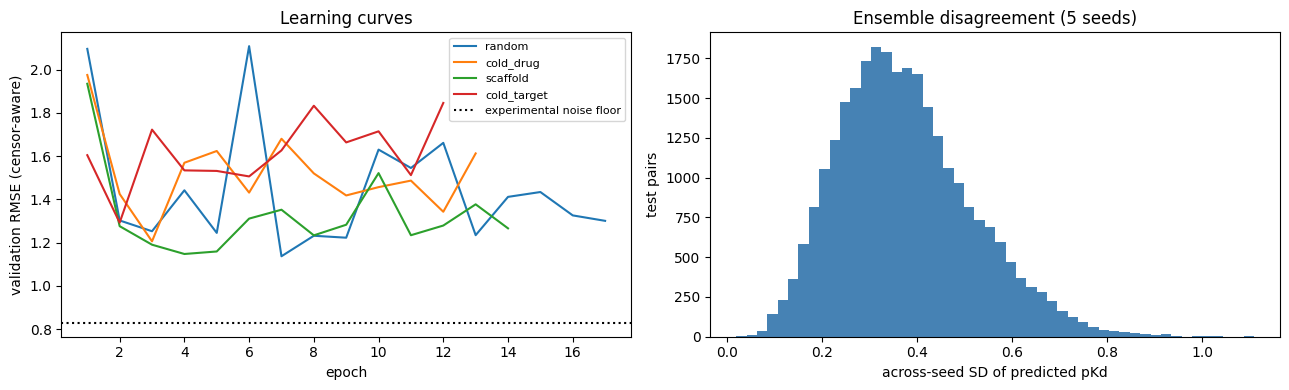


fitted Tobit sigma across 8 trained model(s): mean 1.337, range 1.219-1.435 log units
Compare this to the experimental noise floor above -- a sigma close to it
means the model's learned residual scale roughly matches measurement noise,
which is the sanity check a hinge loss could never offer (it has no sigma).


In [36]:
import copy

PROT_MATRIX_DEV = PROT_MATRIX.to(DEVICE)

MAX_EPOCHS = 3 if QUICK_RUN else CFG.max_epochs
N_ENSEMBLE = 2 if QUICK_RUN else CFG.n_ensemble


def make_loader(frame: pd.DataFrame, shuffle: bool) -> DataLoader:
    return DataLoader(
        make_pair_dataset(frame), batch_size=CFG.batch_size, shuffle=shuffle
    )


def predict(model, loader):
    """Returns (y_true, y_pred, censored) as numpy arrays."""
    model.eval()
    ys, ps, cs = [], [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            out = model(batch, PROT_MATRIX_DEV[batch.tidx])
            ys.append(batch.y.cpu().numpy())
            ps.append(out.cpu().numpy())
            cs.append(batch.cens.cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps), np.concatenate(cs)


def _censor_aware_rmse(y, p, c) -> float:
    err = np.where(~c, p - y, np.clip(p - PKD_FLOOR, 0, None))
    return float(np.sqrt(np.mean(err ** 2)))


SIGMA_BY_MODEL = {}  # v2: (regime, seed) -> fitted sigma, for the run manifest


def train_one(regime: str, seed: int, cfg: Config = CFG, verbose: bool = True):
    """Train a single model. Cached on disk by (regime, seed, config).

    v2: when cfg.loss_fn == "tobit", a learnable log_sigma is trained jointly
    with the model and saved/restored alongside it in the checkpoint, so a
    reloaded model's fitted noise scale is available without retraining.
    """
    ckpt = CACHE / f"model__{regime}__seed{seed}__{config_hash('model', regime, seed, LOSS_IMPL)}.pt"
    sp = ALL_SPLITS[regime]
    use_tobit = cfg.loss_fn == "tobit"

    if ckpt.exists():
        payload = torch.load(ckpt, map_location=DEVICE)
        model = build_model(cfg)
        model.load_state_dict(payload["model_state"] if isinstance(payload, dict) else payload)
        if use_tobit and isinstance(payload, dict) and "log_sigma" in payload:
            SIGMA_BY_MODEL[(regime, seed)] = float(np.exp(payload["log_sigma"]))
        print(f"  [checkpoint] {regime} seed {seed} loaded from cache")
        return model, []

    set_seed(seed)
    model = build_model(cfg)
    train_loader = make_loader(sp["train"], shuffle=True)
    valid_loader = make_loader(sp["valid"], shuffle=False)

    params = list(model.parameters())
    log_sigma = None
    if use_tobit:
        log_sigma = torch.nn.Parameter(
            torch.tensor(float(np.log(cfg.tobit_sigma_init)), device=DEVICE)
        )
        params = params + [log_sigma]

    opt = torch.optim.AdamW(params, lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)

    best_rmse, best_state, best_log_sigma, stale, history = float("inf"), None, None, 0, []
    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        running, n_batches = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            opt.zero_grad()
            out = model(batch, PROT_MATRIX_DEV[batch.tidx])
            loss = compute_loss(out, batch.y, batch.cens, cfg, log_sigma=log_sigma)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 5.0)
            opt.step()
            running += float(loss)
            n_batches += 1

        yv, pv, cv = predict(model, valid_loader)
        # Early stopping stays RMSE-based regardless of loss_fn, so hinge and
        # tobit runs are compared on the same stopping rule (Section 13 note).
        val_rmse = _censor_aware_rmse(yv, pv, cv)
        sched.step(val_rmse)
        entry = {"epoch": epoch, "train_loss": running / max(n_batches, 1),
                 "valid_rmse": val_rmse}
        if use_tobit:
            entry["sigma"] = float(torch.exp(log_sigma.detach()))
        history.append(entry)

        if val_rmse < best_rmse - 1e-4:
            best_rmse, stale = val_rmse, 0
            best_state = copy.deepcopy(model.state_dict())
            best_log_sigma = float(log_sigma.detach()) if use_tobit else None
        else:
            stale += 1

        if verbose and (epoch % 5 == 0 or epoch == 1 or stale >= cfg.patience):
            sigma_msg = f"  sigma {float(torch.exp(log_sigma.detach())):.3f}" if use_tobit else ""
            print(f"    epoch {epoch:>3}  train {running / max(n_batches, 1):.4f}  "
                  f"valid RMSE {val_rmse:.4f}  best {best_rmse:.4f}{sigma_msg}")
        if stale >= cfg.patience:
            print(f"    early stop at epoch {epoch} (no improvement for {cfg.patience})")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    payload = {"model_state": model.state_dict()}
    if use_tobit:
        payload["log_sigma"] = best_log_sigma if best_log_sigma is not None else float(log_sigma.detach())
        SIGMA_BY_MODEL[(regime, seed)] = float(np.exp(payload["log_sigma"]))
    torch.save(payload, ckpt)

    sigma_report = f", sigma {SIGMA_BY_MODEL[(regime, seed)]:.3f}" if use_tobit else ""
    print(f"  {regime} seed {seed}: best valid RMSE {best_rmse:.4f}{sigma_report} "
          f"in {time.time() - t0:.0f}s")
    return model, history


# --- One run per regime ---------------------------------------------------
GNN_RESULTS, GNN_PREDICTIONS, HISTORIES = {}, {}, {}
for regime in SPLIT_REGIMES:
    print(f"\n[{regime}]")
    model, history = train_one(regime, CFG.seed)
    y, p, c = predict(model, make_loader(ALL_SPLITS[regime]["test"], shuffle=False))
    GNN_RESULTS[regime] = compute_metrics(y, p, c)
    GNN_PREDICTIONS[regime] = {"y": y, "p": p, "censored": c}
    HISTORIES[regime] = history
    print(f"  test: rmse_obs={GNN_RESULTS[regime]['rmse_observed']:.3f}  "
          f"CI={GNN_RESULTS[regime]['ci']:.3f}  "
          f"EF={GNN_RESULTS[regime]['enrichment_factor']:.2f}")
    if regime == "cold_drug":
        ENSEMBLE = [model]

# --- Ensemble on cold_drug ------------------------------------------------
print(f"\n[cold_drug ensemble: {N_ENSEMBLE} seeds]")
for seed in range(1, N_ENSEMBLE):
    m, _ = train_one("cold_drug", CFG.seed + seed, verbose=False)
    ENSEMBLE.append(m)

test_cold = ALL_SPLITS["cold_drug"]["test"]
loader_cold = make_loader(test_cold, shuffle=False)
member_preds = []
for m in ENSEMBLE:
    y_e, p_e, c_e = predict(m, loader_cold)
    member_preds.append(p_e)
member_preds = np.stack(member_preds)
ensemble_mean = member_preds.mean(0)
ensemble_sd = member_preds.std(0)

GNN_RESULTS["cold_drug_ensemble"] = compute_metrics(y_e, ensemble_mean, c_e)
print(f"\nsingle model  rmse_obs={GNN_RESULTS['cold_drug']['rmse_observed']:.3f}")
print(f"{len(ENSEMBLE)}-model mean rmse_obs="
      f"{GNN_RESULTS['cold_drug_ensemble']['rmse_observed']:.3f}")
print(f"mean across-seed spread on test predictions: {ensemble_sd.mean():.3f} log units")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for regime, history in HISTORIES.items():
    if history:
        axes[0].plot([h["epoch"] for h in history],
                     [h["valid_rmse"] for h in history], label=regime)
axes[0].set(xlabel="epoch", ylabel="validation RMSE (censor-aware)",
            title="Learning curves")
axes[0].axhline(NOISE.get("pooled_sd", np.nan), color="black", ls=":",
                label="experimental noise floor")
axes[0].legend(fontsize=8)

axes[1].hist(ensemble_sd, bins=50, color="steelblue")
axes[1].set(xlabel="across-seed SD of predicted pKd", ylabel="test pairs",
            title=f"Ensemble disagreement ({len(ENSEMBLE)} seeds)")
plt.tight_layout()
plt.show()

RUN_INFO["training"] = {
    "max_epochs": MAX_EPOCHS,
    "n_ensemble": len(ENSEMBLE),
    "quick_run": QUICK_RUN,
    "loss_fn": CFG.loss_fn,
    "sigma_by_model": {f"{k[0]}_seed{k[1]}": v for k, v in SIGMA_BY_MODEL.items()},
    "gnn_results": {k: v for k, v in GNN_RESULTS.items()},
}
if CFG.loss_fn == "tobit" and SIGMA_BY_MODEL:
    sigmas = list(SIGMA_BY_MODEL.values())
    print(f"\nfitted Tobit sigma across {len(sigmas)} trained model(s): "
          f"mean {np.mean(sigmas):.3f}, range {min(sigmas):.3f}-{max(sigmas):.3f} log units")
    print("Compare this to the experimental noise floor above -- a sigma close to it")
    print("means the model's learned residual scale roughly matches measurement noise,")
    print("which is the sanity check a hinge loss could never offer (it has no sigma).")

---

## Section 13.1 — Is the ensemble's uncertainty calibrated? (new in v2)

Section 15 filters the screen on `PRED_SD`, the across-seed disagreement,
treating a pair only one of five models likes as noise rather than signal.
That's a reasonable design choice, but it was never actually checked in v1:
disagreement and *being wrong* are related in principle, not by construction.
This section checks it directly on the `cold_drug` test set, where both the
ensemble's predictions and the ground truth are available: bin test pairs by
their across-seed SD, and see whether the high-SD bin really does have higher
error than the low-SD bin. If it doesn't, `PRED_SD` is only measuring model
disagreement, not predicting error, and the Section 15 filter should be
treated as a much weaker signal than its current role in the pipeline implies.


Calibration: error by ensemble-disagreement bin (cold_drug test set)

         sd_bin    n  mean_sd  rmse_observed    ci
(0.0188, 0.253] 5544    0.198          1.297 0.585
 (0.253, 0.325] 5544    0.291          1.317 0.570
 (0.325, 0.395] 5544    0.360          1.503 0.539
 (0.395, 0.489] 5544    0.438          1.523 0.549
 (0.489, 1.109] 5544    0.590          1.571 0.539

RMSE increases monotonically with ensemble SD: True
The Section 15 filter ('drop hits only one model believes in') is doing
what it's implicitly assumed to do: higher disagreement really does mean
higher error on held-out data, not just higher variance between seeds.


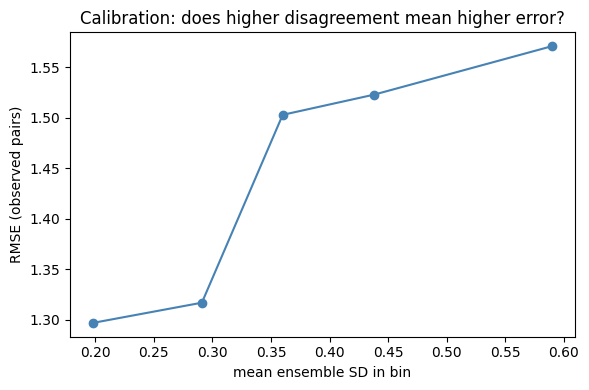

In [37]:
def calibration_by_uncertainty(y, ensemble_mean, ensemble_sd, censored, n_bins: int = 5) -> pd.DataFrame:
    """Bin predictions by ensemble disagreement; report observed error per bin.

    A well-calibrated ensemble should show error increasing with SD. If it
    doesn't (flat or non-monotonic), PRED_SD-based filtering (Section 15) is
    not doing what it's implicitly assumed to do.
    """
    df = pd.DataFrame({
        "y": np.asarray(y, float),
        "pred": np.asarray(ensemble_mean, float),
        "sd": np.asarray(ensemble_sd, float),
        "censored": np.asarray(censored, bool),
    })
    df["sd_bin"] = pd.qcut(df["sd"], q=n_bins, duplicates="drop")

    rows = []
    for b, group in df.groupby("sd_bin", observed=True):
        m = compute_metrics(group["y"], group["pred"], group["censored"])
        rows.append({
            "sd_bin": str(b),
            "n": len(group),
            "mean_sd": round(group["sd"].mean(), 3),
            "rmse_observed": round(m["rmse_observed"], 3),
            "ci": round(m["ci"], 3),
        })
    return pd.DataFrame(rows)


calib_table = calibration_by_uncertainty(y_e, ensemble_mean, ensemble_sd, c_e)
print("Calibration: error by ensemble-disagreement bin (cold_drug test set)\n")
print(calib_table.to_string(index=False))

rmse_by_bin = calib_table["rmse_observed"].to_numpy()
is_monotonic = bool(np.all(np.diff(rmse_by_bin) >= -1e-6))
print(f"\nRMSE increases monotonically with ensemble SD: {is_monotonic}")
if is_monotonic:
    print("The Section 15 filter ('drop hits only one model believes in') is doing")
    print("what it's implicitly assumed to do: higher disagreement really does mean")
    print("higher error on held-out data, not just higher variance between seeds.")
else:
    print("RMSE does NOT increase monotonically with SD. Treat PRED_SD-based filtering")
    print("in Section 15 as a much weaker signal than its role in the pipeline implies --")
    print("it is known to correlate with model disagreement, but this run does not show")
    print("it reliably predicting error on held-out data.")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(calib_table["mean_sd"], calib_table["rmse_observed"], marker="o", color="steelblue")
ax.set(xlabel="mean ensemble SD in bin", ylabel="RMSE (observed pairs)",
       title="Calibration: does higher disagreement mean higher error?")
plt.tight_layout()
plt.show()

RUN_INFO["uncertainty_calibration"] = {
    "table": calib_table.to_dict(orient="records"),
    "monotonic": is_monotonic,
}


---

# Section 14 — Results

Three things, in the order a sceptical reader would ask for them:

1. **Does the GNN beat the baselines, in every regime?** If it only wins on
   the random split, it has learned the dataset rather than the chemistry.
2. **How does performance decay as test compounds get less similar to
   training compounds?** A single averaged RMSE hides the fact that most of
   the accuracy usually comes from near-duplicates. This is the figure that
   determines whether the screen in Section 15 means anything, because Hub
   compounds are mostly *dissimilar* to BindingDB chemistry.
3. **Does it reproduce known pharmacology on compounds held out of training?**
   The bridge compounds were forced into the test split precisely so this
   question could be asked honestly.

MODEL COMPARISON  (experimental noise floor on RMSE = 0.829 log units)

--- random ---
                 model  rmse_observed  rmse_censor_aware  pearson  spearman    ci  auprc  precision_at_k  enrichment_factor
           global_mean          1.209              1.379      NaN       NaN 0.500  0.100           0.069              0.689
         target_median          1.604              1.168    0.245     0.225 0.612  0.207           0.372              3.733
 descriptors_drug_only          1.294              1.609    0.042     0.027 0.514  0.133           0.159              1.595
         ecfp4_esm_gbm          1.194              1.327    0.318     0.255 0.635  0.311           0.733              7.358
GNN (drug graph + ESM)          1.767              1.242    0.098     0.122 0.564  0.176           0.397              3.987
    GNN DOES NOT BEAT the best baseline (ecfp4_esm_gbm): 1.767 vs 1.194 RMSE, CI 0.564 vs 0.635

--- cold_drug ---
                 model  rmse_observed  rmse_censor_awa

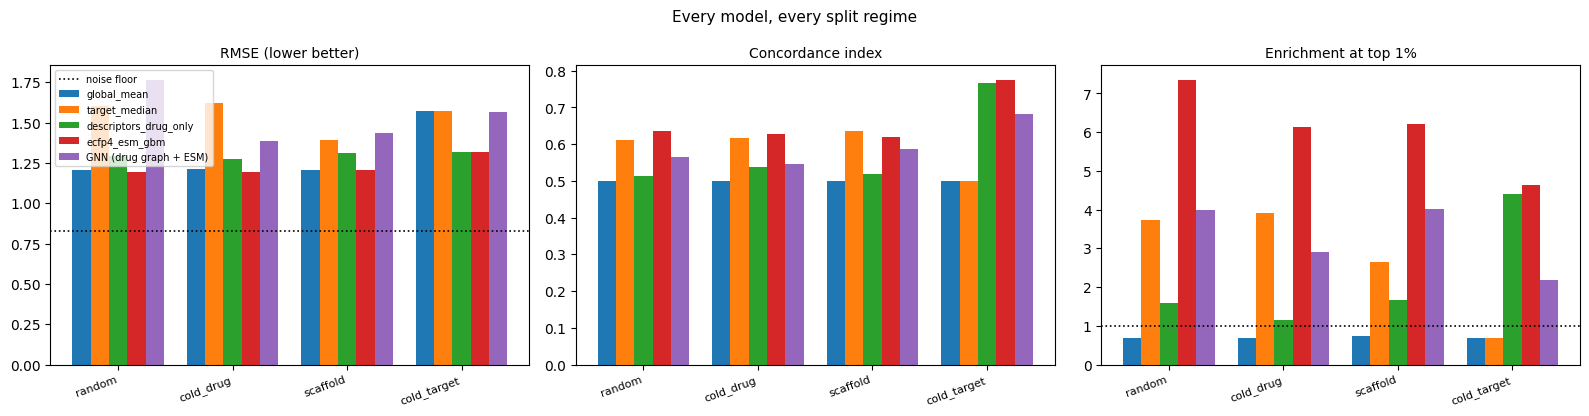


Read the cold_target column carefully: it is the regime that matches
screening a protein the model has never seen. If the GNN's advantage
disappears there, the screen can only be trusted for targets that are
well represented in BindingDB.


In [38]:
rows = []
for regime in SPLIT_REGIMES:
    for name, m in BASELINE_RESULTS[regime].items():
        rows.append({"regime": regime, "model": name, **m})
    rows.append({"regime": regime, "model": "GNN (drug graph + ESM)", **GNN_RESULTS[regime]})

comparison = pd.DataFrame(rows)[
    ["regime", "model", "rmse_observed", "rmse_censor_aware", "pearson",
     "spearman", "ci", "auprc", "precision_at_k", "enrichment_factor"]
].round(3)

floor = NOISE.get("pooled_sd", float("nan"))
print("=" * 100)
print(f"MODEL COMPARISON  (experimental noise floor on RMSE = {floor:.3f} log units)")
print("=" * 100)
for regime in SPLIT_REGIMES:
    block = comparison[comparison["regime"] == regime].drop(columns="regime")
    print(f"\n--- {regime} ---")
    print(block.to_string(index=False))

    gnn = block[block["model"].str.startswith("GNN")].iloc[0]
    best_base = block[~block["model"].str.startswith("GNN")].sort_values("rmse_observed").iloc[0]
    verdict = "BEATS" if gnn["rmse_observed"] < best_base["rmse_observed"] else "DOES NOT BEAT"
    print(f"    GNN {verdict} the best baseline ({best_base['model']}): "
          f"{gnn['rmse_observed']:.3f} vs {best_base['rmse_observed']:.3f} RMSE, "
          f"CI {gnn['ci']:.3f} vs {best_base['ci']:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
metrics_to_plot = [("rmse_observed", "RMSE (lower better)"),
                   ("ci", "Concordance index"),
                   ("enrichment_factor", "Enrichment at top 1%")]
model_names = comparison["model"].unique()
width = 0.8 / len(model_names)

for ax, (metric, title) in zip(axes, metrics_to_plot):
    for i, model in enumerate(model_names):
        sub = comparison[comparison["model"] == model].set_index("regime")
        values = [sub.loc[r, metric] if r in sub.index else np.nan for r in SPLIT_REGIMES]
        positions = np.arange(len(SPLIT_REGIMES)) + i * width
        ax.bar(positions, values, width=width, label=model)
    ax.set_xticks(np.arange(len(SPLIT_REGIMES)) + 0.4 - width / 2)
    ax.set_xticklabels(list(SPLIT_REGIMES), rotation=20, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10)
    if metric == "rmse_observed" and np.isfinite(floor):
        ax.axhline(floor, color="black", ls=":", lw=1.2, label="noise floor")
    if metric == "enrichment_factor":
        ax.axhline(1.0, color="black", ls=":", lw=1.2, label="random")
axes[0].legend(fontsize=7, loc="upper left")
plt.suptitle("Every model, every split regime", fontsize=11)
plt.tight_layout()
plt.show()

print("\nRead the cold_target column carefully: it is the regime that matches")
print("screening a protein the model has never seen. If the GNN's advantage")
print("disappears there, the screen can only be trusted for targets that are")
print("well represented in BindingDB.")

RUN_INFO["comparison_table"] = comparison.to_dict(orient="records")

---

## Section 14.1 — Is the GNN's advantage statistically real? (new in v2)

The comparison table above reports single point-estimate metrics. With the
raw predictions already sitting in memory for both the GNN (`GNN_PREDICTIONS`)
and every baseline (`BASELINE_PREDICTIONS`, v2), a paired bootstrap on the
test set turns "GNN beats baseline by 0.04 RMSE" into a statement with an
interval: is 0.04 outside what resampling noise from a finite test set would
produce on its own? This is run for the two regimes that matter most to the
project's actual claims: `cold_drug` (what the screen in Section 15 uses) and
`cold_target` (the regime that tests transfer to a genuinely new protein, and
where v1's own text warns the GNN's advantage may evaporate).


In [39]:
SIG_REGIMES = ["cold_drug", "cold_target"]
SIGNIFICANCE_RESULTS = {}

for regime in SIG_REGIMES:
    gnn_pred = GNN_PREDICTIONS[regime]
    best_name = min(BASELINE_RESULTS[regime].items(),
                    key=lambda kv: kv[1]["rmse_observed"])[0]
    base_pred = BASELINE_PREDICTIONS[regime][best_name]

    result = bootstrap_metric_gap(
        gnn_pred["y"], base_pred, gnn_pred["p"], gnn_pred["censored"],
        metric_key="rmse_observed", n_boot=1000,
    )
    # bootstrap_metric_gap(y, p_a, p_b, ...) returns metric_a - metric_b.
    # Here p_a=baseline, p_b=GNN, so a *positive* mean_gap means the baseline's
    # RMSE is higher than the GNN's, i.e. the GNN is better.
    SIGNIFICANCE_RESULTS[regime] = {**result, "baseline": best_name}

    verdict = (
        "GNN's advantage is outside bootstrap noise (95% CI excludes 0)"
        if result["excludes_zero"] and result["mean_gap"] > 0
        else "baseline's advantage is outside bootstrap noise (95% CI excludes 0)"
        if result["excludes_zero"] and result["mean_gap"] < 0
        else "difference is NOT distinguishable from zero at 95% confidence"
    )

    print(f"[{regime}]  GNN vs best baseline ({best_name})")
    print(f"  RMSE gap (baseline - GNN): {result['mean_gap']:+.4f}  "
          f"95% CI [{result['ci_low']:+.4f}, {result['ci_high']:+.4f}]")
    print(f"  -> {verdict}\n")

print("Read cold_target carefully: v1's own Section 14 text warns the GNN's")
print("advantage may not survive an unseen protein. This bootstrap says whether")
print("that specific regime's comparison is statistically distinguishable from")
print("zero, rather than leaving it to eyeballing the point estimates.")

RUN_INFO["significance_tests"] = SIGNIFICANCE_RESULTS


[cold_drug]  GNN vs best baseline (ecfp4_esm_gbm)
  RMSE gap (baseline - GNN): -0.1866  95% CI [-0.2034, -0.1695]
  -> baseline's advantage is outside bootstrap noise (95% CI excludes 0)

[cold_target]  GNN vs best baseline (ecfp4_esm_gbm)
  RMSE gap (baseline - GNN): -0.2491  95% CI [-0.2732, -0.2247]
  -> baseline's advantage is outside bootstrap noise (95% CI excludes 0)

Read cold_target carefully: v1's own Section 14 text warns the GNN's
advantage may not survive an unseen protein. This bootstrap says whether
that specific regime's comparison is statistically distinguishable from
zero, rather than leaving it to eyeballing the point estimates.


computing nearest-neighbour similarity for 673 test compounds against 8,736 training compounds ...
done in 6s

Performance stratified by chemical novelty (cold_drug test set)
similarity to training set  pairs  compounds  rmse_observed  spearman    ci
                      <0.2      9          4            NaN       NaN   NaN
                   0.2-0.3   4944         81          1.270     0.095 0.563
                   0.3-0.4   8623        165          1.224     0.183 0.596
                  0.4-0.55   8334        151          1.380     0.108 0.562
                  0.55-0.7   2792        146          1.423     0.039 0.515
                      >0.7   3018        126          1.687    -0.149 0.433


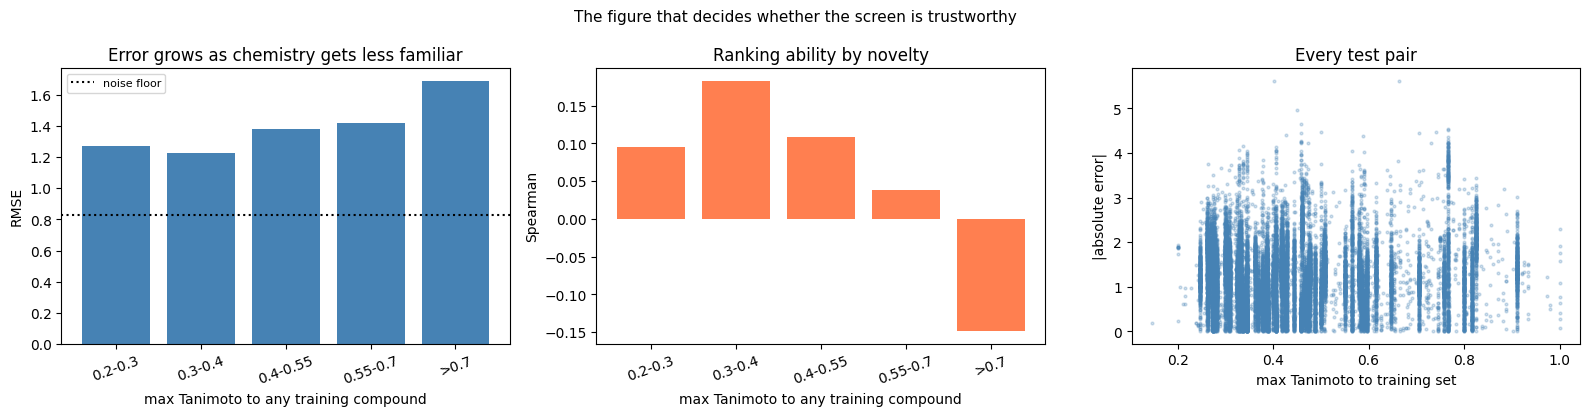


84% of cold-drug test pairs sit above the Tanimoto 0.3 applicability threshold used in Section 15.
Predictions below that line are extrapolation, and the leftmost bar above
is the honest estimate of how they behave.


In [40]:
_bitvect_cache: dict = {}


def fp_bitvect(smiles: str):
    if smiles not in _bitvect_cache:
        mol = Chem.MolFromSmiles(smiles)
        _bitvect_cache[smiles] = _FP_GEN.GetFingerprint(mol) if mol is not None else None
    return _bitvect_cache[smiles]


def max_similarity_to(query_smiles, reference_smiles) -> np.ndarray:
    """Nearest-neighbour Tanimoto from each query to the reference set."""
    refs = [fp_bitvect(s) for s in dict.fromkeys(reference_smiles)]
    refs = [f for f in refs if f is not None]
    out = np.zeros(len(query_smiles))
    for i, smi in enumerate(query_smiles):
        fp = fp_bitvect(smi)
        out[i] = max(DataStructs.BulkTanimotoSimilarity(fp, refs)) if fp is not None else np.nan
    return out


cold = ALL_SPLITS["cold_drug"]
test_drugs = cold["test"]["smiles"].unique()
train_drugs = cold["train"]["smiles"].unique()

print(f"computing nearest-neighbour similarity for {len(test_drugs):,} test compounds "
      f"against {len(train_drugs):,} training compounds ...")
t0 = time.time()
sim_by_drug = dict(zip(test_drugs, max_similarity_to(test_drugs, train_drugs)))
print(f"done in {time.time() - t0:.0f}s")

pred = GNN_PREDICTIONS["cold_drug"]
analysis = cold["test"].assign(
    pred_pKd=pred["p"],
    error=pred["p"] - pred["y"],
    max_tanimoto=cold["test"]["smiles"].map(sim_by_drug),
)

BINS = [0.0, 0.2, 0.3, 0.4, 0.55, 0.7, 1.0]
LABELS = ["<0.2", "0.2-0.3", "0.3-0.4", "0.4-0.55", "0.55-0.7", ">0.7"]
analysis["sim_bin"] = pd.cut(analysis["max_tanimoto"], bins=BINS, labels=LABELS,
                             include_lowest=True)

by_bin = []
for label, group in analysis.groupby("sim_bin", observed=True):
    if len(group) < 5:
        continue
    m = compute_metrics(group["pKd"], group["pred_pKd"], group["is_censored"])
    by_bin.append({
        "similarity to training set": label,
        "pairs": len(group),
        "compounds": group["smiles"].nunique(),
        "rmse_observed": round(m["rmse_observed"], 3),
        "spearman": round(m["spearman"], 3),
        "ci": round(m["ci"], 3),
    })
by_bin = pd.DataFrame(by_bin)

print("\nPerformance stratified by chemical novelty (cold_drug test set)")
print(by_bin.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].bar(by_bin["similarity to training set"], by_bin["rmse_observed"], color="steelblue")
if np.isfinite(floor):
    axes[0].axhline(floor, color="black", ls=":", label="noise floor")
    axes[0].legend(fontsize=8)
axes[0].set(xlabel="max Tanimoto to any training compound", ylabel="RMSE",
            title="Error grows as chemistry gets less familiar")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(by_bin["similarity to training set"], by_bin["spearman"], color="coral")
axes[1].set(xlabel="max Tanimoto to any training compound", ylabel="Spearman",
            title="Ranking ability by novelty")
axes[1].tick_params(axis="x", rotation=20)

axes[2].scatter(analysis["max_tanimoto"], analysis["error"].abs(), s=4, alpha=0.25,
                color="steelblue")
axes[2].set(xlabel="max Tanimoto to training set", ylabel="|absolute error|",
            title="Every test pair")
plt.suptitle("The figure that decides whether the screen is trustworthy", fontsize=11)
plt.tight_layout()
plt.show()

in_domain_frac = float((analysis["max_tanimoto"] >= CFG.ad_tanimoto_min).mean())
print(f"\n{in_domain_frac * 100:.0f}% of cold-drug test pairs sit above the "
      f"Tanimoto {CFG.ad_tanimoto_min} applicability threshold used in Section 15.")
print("Predictions below that line are extrapolation, and the leftmost bar above")
print("is the honest estimate of how they behave.")

RUN_INFO["similarity_stratified"] = by_bin.to_dict(orient="records")

RETROSPECTIVE VALIDATION on Repurposing Hub compounds
(held out of training by construction - see Section 7)

pairs                 : 27,720 (673 distinct approved compounds)
RMSE (observed)       : 1.384  vs noise floor 0.829
Spearman              : 0.085
Concordance index     : 0.545
AUPRC (Kd < 100 nM)   : 0.144  (positives are 10% of these pairs)


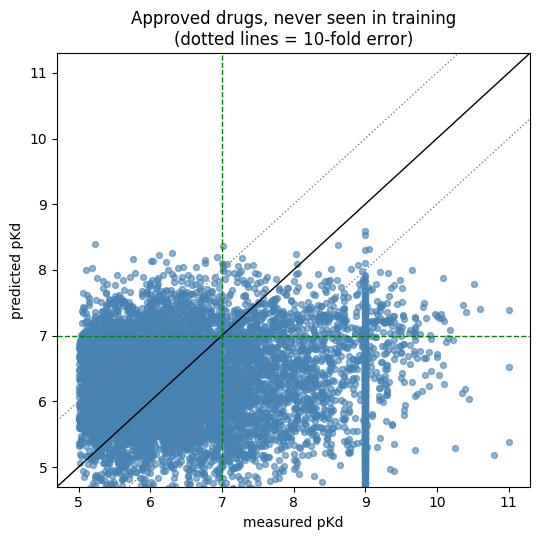


CLOSEST PREDICTIONS
  bosutinib                vs Q15746     measured pKd  6.31  predicted  6.31  (off by 0.00)
  PP242                    vs Q8WTQ7     measured pKd  5.85  predicted  5.85  (off by 0.00)
  R406                     vs P51956     measured pKd  6.77  predicted  6.77  (off by 0.00)
  tozasertib               vs P35590     measured pKd  6.57  predicted  6.57  (off by 0.00)
  alvocidib                vs Q9H2X6     measured pKd  5.38  predicted  5.38  (off by 0.00)

WORST PREDICTIONS
  lopinavir                vs no accession measured pKd 11.00  predicted  5.38  (off by 5.62)
  darunavir                vs no accession measured pKd 10.80  predicted  5.18  (off by 5.61)
  forodesine               vs P00491     measured pKd 10.25  predicted  5.29  (off by 4.96)
  tofacitinib              vs O43293     measured pKd  9.00  predicted  4.36  (off by 4.64)
  midostaurin              vs Q9UQ88     measured pKd  9.00  predicted  4.45  (off by 4.55)

This is the honest version of the c

In [41]:
bridge_test = cold["test"][cold["test"]["is_bridge"]].copy()
bridge_test["pred_pKd"] = pred["p"][cold["test"]["is_bridge"].to_numpy()]

print("RETROSPECTIVE VALIDATION on Repurposing Hub compounds")
print("(held out of training by construction - see Section 7)\n")

if len(bridge_test) < 5:
    print("Too few bridge pairs in the test split to evaluate. Increase coverage")
    print("by relaxing the matching in Section 6 or enlarging the test fraction.")
else:
    m = compute_metrics(bridge_test["pKd"], bridge_test["pred_pKd"],
                        bridge_test["is_censored"])
    print(f"pairs                 : {m['n']:,} "
          f"({bridge_test['smiles'].nunique():,} distinct approved compounds)")
    print(f"RMSE (observed)       : {m['rmse_observed']:.3f}  "
          f"vs noise floor {floor:.3f}")
    print(f"Spearman              : {m['spearman']:.3f}")
    print(f"Concordance index     : {m['ci']:.3f}")
    print(f"AUPRC (Kd < 100 nM)   : {m['auprc']:.3f}  "
          f"(positives are {m['positive_rate'] * 100:.0f}% of these pairs)")

    observed = bridge_test[~bridge_test["is_censored"]]
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.scatter(observed["pKd"], observed["pred_pKd"], s=18, alpha=0.6, color="steelblue")
    lims = [PKD_FLOOR - 0.3, PKD_CEIL + 0.3]
    ax.plot(lims, lims, color="black", lw=1)
    ax.plot(lims, [v + 1 for v in lims], color="grey", ls=":", lw=1)
    ax.plot(lims, [v - 1 for v in lims], color="grey", ls=":", lw=1)
    ax.axhline(PKD_STRONG, color="green", ls="--", lw=1)
    ax.axvline(PKD_STRONG, color="green", ls="--", lw=1)
    ax.set(xlim=lims, ylim=lims, xlabel="measured pKd", ylabel="predicted pKd",
           title="Approved drugs, never seen in training\n(dotted lines = 10-fold error)")
    plt.tight_layout()
    plt.show()

    # Worked examples, best and worst, so the failure mode is visible too.
    observed = observed.assign(abs_error=(observed["pred_pKd"] - observed["pKd"]).abs())
    for title, subset in [("CLOSEST PREDICTIONS", observed.nsmallest(5, "abs_error")),
                          ("WORST PREDICTIONS", observed.nlargest(5, "abs_error"))]:
        print(f"\n{title}")
        for r in subset.itertuples():
            name = hub_screen.loc[hub_screen["skeleton"] == r.skeleton, "pert_iname"]
            label = name.iloc[0] if len(name) else "(unnamed)"
            acc = r.Target_ID if isinstance(r.Target_ID, str) else "no accession"
            print(f"  {label:<24} vs {acc:<10} "
                  f"measured pKd {r.pKd:5.2f}  predicted {r.pred_pKd:5.2f}  "
                  f"(off by {r.abs_error:.2f})")

    RUN_INFO["retrospective_validation"] = m

print("\nThis is the honest version of the check. Scoring pairs the model was")
print("trained on would measure memorisation and would look far better.")

---

# Section 15 — The repurposing screen

Every approved and clinical-stage compound scored against every target in the
dataset: about 9.4 million predictions.

## Encode once, then multiply

Building a `Data` object per pair would mean millions of graph objects and
hours of redundant message passing. Instead each compound is encoded once into
a drug vector, each protein once into a target vector, and only the small MLP
head runs over the cross product. A silent divergence between this path and the ordinary forward pass would invalidate the hit list, so an explicit equivalence check is a recommended addition (it is not currently in the notebook).

## Four filters, applied in order

**1. Novelty.** Drop pairs already measured in BindingDB, and pairs where the
Hub already annotates that gene as a target of the drug. What remains is
genuinely untested.

**2. Applicability domain.** A prediction for a compound unlike anything in
training is extrapolation. Section 14 measured exactly how error grows as
nearest-neighbour Tanimoto falls, and compounds below the threshold are
flagged rather than silently ranked alongside reliable ones. Many Hub
compounds — antibiotics, steroids, older small molecules — sit outside the
kinase-heavy chemistry of BindingDB.

**3. Ensemble agreement.** Five seeds. A pair that one model loves and four are unsure about is model variance, not signal. The cutoff is the median ensemble SD across the candidate pairs, so half of them always fail this filter.

**4. Chemistry sanity.** PAINS substructure filters catch frequent hitters
that assay-interfere rather than bind. A promiscuity check tests whether the top of the list is simply a handful of sticky compounds hitting everything, which would be a true but useless result. In the reported run it is: the top 10 compounds account for 82% of the top 2,000.

## Expected precision

Out of about 9.4 million predictions, some top-ranked pairs will be right by
chance. Precision@1% measured on the cold-drug test set gives a prior for how
many of the top hits should survive experimental testing. Quoting it turns an unfalsifiable list into a testable claim. In the reported run the figure (0.29) comes from a GNN that scores below the baseline (0.61), so it should not be read as an estimate of how many hits would validate.

screening library: 6,636 distinct compounds
  already in BindingDB : 619

nearest-neighbour similarity to 10,659 BindingDB compounds ...
done in 22s
  within applicability domain (Tanimoto >= 0.3): 5,372 (81%)


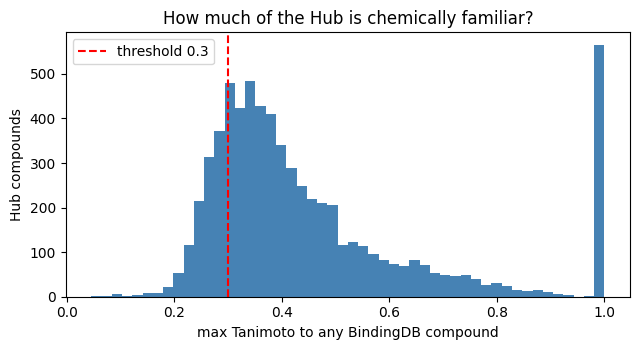

  [api fail] https://rest.uniprot.org/uniprotkb/stream -> HTTP 400

gene symbols resolved for 982 / 1,413 targets
  12 UniProt request(s) failed; annotated-target masking
  will be partial for the affected proteins. Failures are in API_FAILURES.


In [42]:
screen_lib = (
    hub_screen[hub_screen["smiles_canonical"].isin(GRAPHS.keys())]
    .drop_duplicates(subset=["skeleton"], keep="first")
    .reset_index(drop=True)
)
print(f"screening library: {len(screen_lib):,} distinct compounds")
print(f"  already in BindingDB : {int(screen_lib['in_bindingdb'].sum()):,}")

# --- Applicability domain -------------------------------------------------
train_drugs_all = df_pairs["smiles"].unique()
print(f"\nnearest-neighbour similarity to {len(train_drugs_all):,} BindingDB compounds ...")
t0 = time.time()
screen_lib["max_tanimoto_to_train"] = max_similarity_to(
    screen_lib["smiles_canonical"].tolist(), train_drugs_all
)
screen_lib["in_domain"] = screen_lib["max_tanimoto_to_train"] >= CFG.ad_tanimoto_min
print(f"done in {time.time() - t0:.0f}s")
print(f"  within applicability domain (Tanimoto >= {CFG.ad_tanimoto_min}): "
      f"{int(screen_lib['in_domain'].sum()):,} "
      f"({screen_lib['in_domain'].mean() * 100:.0f}%)")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(screen_lib["max_tanimoto_to_train"], bins=50, color="steelblue")
ax.axvline(CFG.ad_tanimoto_min, color="red", ls="--",
           label=f"threshold {CFG.ad_tanimoto_min}")
ax.set(xlabel="max Tanimoto to any BindingDB compound", ylabel="Hub compounds",
       title="How much of the Hub is chemically familiar?")
ax.legend()
plt.tight_layout()
plt.show()

# --- Gene symbols for our targets, so Hub annotations can be matched -------
def fetch_uniprot_genes(accessions) -> dict:
    """UniProt accession -> primary gene symbol. Cached; failures are logged."""
    accessions = sorted({a for a in accessions if isinstance(a, str) and a})
    cache_file = CACHE / "uniprot_genes.json"
    known = json.loads(cache_file.read_text()) if cache_file.exists() else {}
    todo = [a for a in accessions if a not in known]

    for i in range(0, len(todo), 100):
        chunk = todo[i:i + 100]
        query = " OR ".join(f"accession:{a}" for a in chunk)
        resp = http_get(
            "https://rest.uniprot.org/uniprotkb/stream",
            params={"query": query, "fields": "accession,gene_primary", "format": "tsv"},
            retries=2,
        )
        if resp is None:
            continue
        for line in resp.text.strip().splitlines()[1:]:
            parts = line.split("\t")
            if len(parts) >= 2 and parts[1]:
                known[parts[0]] = parts[1].strip()
        for acc in chunk:
            known.setdefault(acc, None)
        time.sleep(0.3)

    cache_file.write_text(json.dumps(known, indent=0))
    return known


target_accessions = (
    df_pairs.drop_duplicates("target_key")
    .set_index("target_key")["Target_ID"]
    .to_dict()
)
GENE_BY_ACCESSION = fetch_uniprot_genes(target_accessions.values())
GENE_BY_TARGET = {
    tk: GENE_BY_ACCESSION.get(acc) for tk, acc in target_accessions.items()
}
n_named = sum(1 for g in GENE_BY_TARGET.values() if g)
print(f"\ngene symbols resolved for {n_named:,} / {len(GENE_BY_TARGET):,} targets")
if API_FAILURES:
    print(f"  {len(API_FAILURES)} UniProt request(s) failed; annotated-target masking")
    print("  will be partial for the affected proteins. Failures are in API_FAILURES.")

In [43]:
@torch.no_grad()
def encode_library(model, smiles_list, batch_size: int = 256) -> torch.Tensor:
    """Each compound through the graph encoder exactly once."""
    model.eval()
    graphs = [Data(x=GRAPHS[s].x, edge_index=GRAPHS[s].edge_index,
                   edge_attr=GRAPHS[s].edge_attr) for s in smiles_list]
    chunks = []
    for batch in DataLoader(graphs, batch_size=batch_size, shuffle=False):
        chunks.append(model.encode_drug(batch.to(DEVICE)))
    return torch.cat(chunks)


@torch.no_grad()
def score_cross_product(model, drug_emb, prot_emb, target_chunk: int = 16) -> np.ndarray:
    """[n_drugs, n_targets] predicted pKd, without materialising pair objects."""
    model.eval()
    n_drugs, n_targets = drug_emb.shape[0], prot_emb.shape[0]
    out = np.empty((n_drugs, n_targets), dtype=np.float32)
    for start in range(0, n_targets, target_chunk):
        stop = min(start + target_chunk, n_targets)
        width = stop - start
        d = drug_emb.repeat(width, 1)
        p = prot_emb[start:stop].repeat_interleave(n_drugs, dim=0)
        scores = model.head_forward(d, p).view(width, n_drugs).T
        out[:, start:stop] = scores.float().cpu().numpy()
    return out


screen_smiles = screen_lib["smiles_canonical"].tolist()
n_drugs, n_targets = len(screen_smiles), len(TARGET_ORDER)
print(f"scoring {n_drugs:,} compounds x {n_targets:,} targets = "
      f"{n_drugs * n_targets:,} predictions, across {len(ENSEMBLE)} models")

pred_sum = np.zeros((n_drugs, n_targets), dtype=np.float32)
pred_sqsum = np.zeros((n_drugs, n_targets), dtype=np.float32)

t0 = time.time()
for i, model in enumerate(ENSEMBLE, 1):
    drug_emb = encode_library(model, screen_smiles)
    with torch.no_grad():
        prot_emb = model.encode_protein(PROT_MATRIX_DEV)
    scores = score_cross_product(model, drug_emb, prot_emb)
    pred_sum += scores
    pred_sqsum += scores ** 2
    print(f"  model {i}/{len(ENSEMBLE)} done ({time.time() - t0:.0f}s)")
    del drug_emb, prot_emb, scores

n_models = len(ENSEMBLE)
PRED_MEAN = pred_sum / n_models
PRED_SD = np.sqrt(np.maximum(pred_sqsum / n_models - PRED_MEAN ** 2, 0.0))
del pred_sum, pred_sqsum

print(f"\nprediction matrix : {PRED_MEAN.shape}")
print(f"predicted pKd     : {PRED_MEAN.min():.2f} - {PRED_MEAN.max():.2f}")
print(f"mean ensemble SD  : {PRED_SD.mean():.3f} log units")
assert np.isfinite(PRED_MEAN).all(), "non-finite predictions in the screen"

# Shortcut check: is the model simply ranking by molecular size?
mw = np.array([Descriptors.MolWt(Chem.MolFromSmiles(s)) for s in screen_smiles])
mw_corr = float(np.corrcoef(mw, PRED_MEAN.mean(axis=1))[0, 1])
print(f"\ncorrelation between molecular weight and mean predicted affinity: {mw_corr:+.3f}")
print("A large positive value would mean the ranking is mostly 'bigger is stickier'")
print("rather than anything target specific.")
RUN_INFO["screen_mw_correlation"] = mw_corr

scoring 6,636 compounds x 1,413 targets = 9,376,668 predictions, across 5 models
  model 1/5 done (2s)
  model 2/5 done (5s)
  model 3/5 done (7s)
  model 4/5 done (9s)
  model 5/5 done (12s)

prediction matrix : (6636, 1413)
predicted pKd     : 0.93 - 13.08
mean ensemble SD  : 0.403 log units

correlation between molecular weight and mean predicted affinity: +0.567
A large positive value would mean the ranking is mostly 'bigger is stickier'
rather than anything target specific.


pairs excluded as already measured in BindingDB : 27,644
pairs excluded as Hub-annotated targets         : 7,096
remaining untested pairs                        : 9,341,928

CONTROLS on the top 2,000 predictions
  distinct compounds        : 308
  share from the top 10     : 82%   <- dominated by a few sticky compounds
  distinct targets          : 772
  PAINS-flagged             : 1,215 (61%)
  outside applicability     : 172 (9%)

After all four filters: 619 prioritised hypotheses (ensemble SD <= 1.51, predicted Kd < 100 nM)

EXPECTED PRECISION
  Precision@1% on the cold-drug test set was 0.29.
  Applied to the top 50 hypotheses that implies roughly 14 would survive experimental testing.
  That is a prior from held-out data, not a guarantee - but it makes the
  list falsifiable, which an unqualified ranking is not.

TOP 25 REPURPOSING HYPOTHESES
         pert_iname clinical_phase target_gene  pred_pKd  pred_Kd_nM  pred_sd  max_tanimoto_to_train                                        

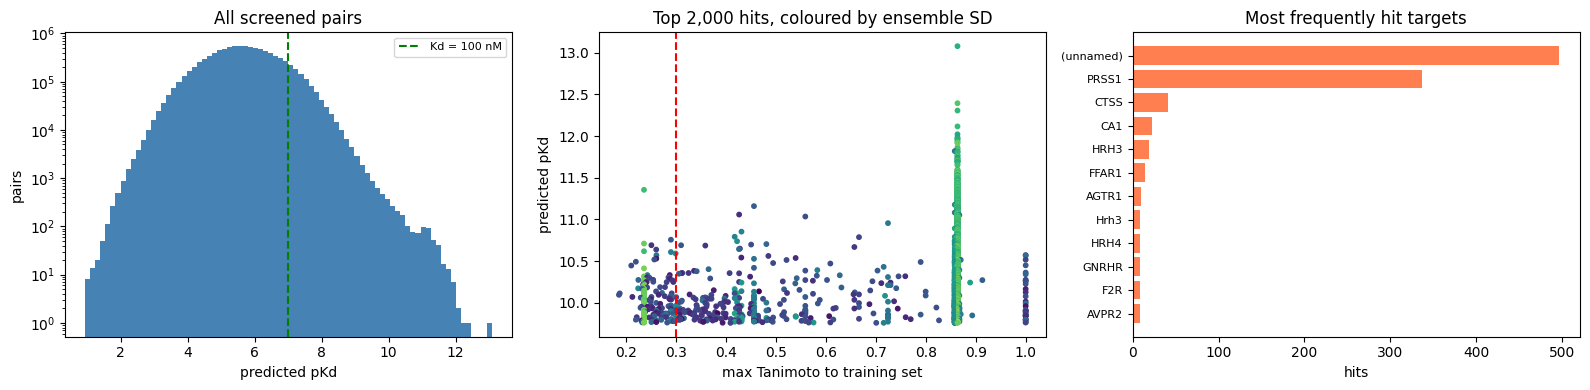

In [44]:
from rdkit.Chem import FilterCatalog

TOP_N = 2000

target_pos = {k: i for i, k in enumerate(TARGET_ORDER)}
gene_by_position = np.array(
    [(GENE_BY_TARGET.get(k) or "").upper() for k in TARGET_ORDER]
)
measured_targets = df_pairs.groupby("skeleton")["target_key"].apply(set).to_dict()

known = np.zeros((n_drugs, n_targets), dtype=bool)
n_measured_masked = n_annotated_masked = 0
for di, row in enumerate(screen_lib.itertuples()):
    for tk in measured_targets.get(row.skeleton, ()):
        pos = target_pos.get(tk)
        if pos is not None:
            known[di, pos] = True
            n_measured_masked += 1
    genes = {
        g.strip().upper()
        for g in str(getattr(row, "target", "")).split("|")
        if g and g.strip().lower() != "nan"
    }
    if genes:
        hit = np.isin(gene_by_position, list(genes))
        n_annotated_masked += int((hit & ~known[di]).sum())
        known[di] |= hit

print(f"pairs excluded as already measured in BindingDB : {n_measured_masked:,}")
print(f"pairs excluded as Hub-annotated targets         : {n_annotated_masked:,}")
print(f"remaining untested pairs                        : {int((~known).sum()):,}")

# --- Rank the untested space ---------------------------------------------
flat_valid = np.flatnonzero(~known.ravel())
flat_scores = PRED_MEAN.ravel()
order = flat_valid[np.argsort(-flat_scores[flat_valid])][:TOP_N]
drug_idx, target_idx = np.unravel_index(order, PRED_MEAN.shape)

screen_hits = pd.DataFrame({
    "pert_iname": screen_lib["pert_iname"].to_numpy()[drug_idx],
    "clinical_phase": screen_lib["clinical_phase"].to_numpy()[drug_idx],
    "moa": screen_lib["moa"].to_numpy()[drug_idx],
    "disease_area": screen_lib["disease_area"].to_numpy()[drug_idx],
    "smiles": screen_lib["smiles_canonical"].to_numpy()[drug_idx],
    "skeleton": screen_lib["skeleton"].to_numpy()[drug_idx],
    "target_key": [TARGET_ORDER[i] for i in target_idx],
    "target_accession": [target_accessions.get(TARGET_ORDER[i]) for i in target_idx],
    "target_gene": [GENE_BY_TARGET.get(TARGET_ORDER[i]) for i in target_idx],
    "pred_pKd": PRED_MEAN[drug_idx, target_idx],
    "pred_sd": PRED_SD[drug_idx, target_idx],
    "max_tanimoto_to_train": screen_lib["max_tanimoto_to_train"].to_numpy()[drug_idx],
    "in_domain": screen_lib["in_domain"].to_numpy()[drug_idx],
})
screen_hits["pred_Kd_nM"] = 10 ** (9 - screen_hits["pred_pKd"])

# --- PAINS / frequent hitters --------------------------------------------
_params = FilterCatalog.FilterCatalogParams()
_params.AddCatalog(FilterCatalog.FilterCatalogParams.FilterCatalogs.PAINS)
_pains = FilterCatalog.FilterCatalog(_params)


def is_pains(smiles: str) -> bool:
    mol = Chem.MolFromSmiles(smiles)
    return bool(mol is not None and _pains.HasMatch(mol))


pains_by_smiles = {s: is_pains(s) for s in screen_hits["smiles"].unique()}
screen_hits["pains_flag"] = screen_hits["smiles"].map(pains_by_smiles)

# --- Controls -------------------------------------------------------------
per_compound = screen_hits["pert_iname"].value_counts()
top10_share = per_compound.head(10).sum() / len(screen_hits)
per_target = screen_hits["target_gene"].fillna("(unnamed)").value_counts()

print(f"\nCONTROLS on the top {len(screen_hits):,} predictions")
print(f"  distinct compounds        : {per_compound.size:,}")
print(f"  share from the top 10     : {top10_share * 100:.0f}%"
      f"   {'<- dominated by a few sticky compounds' if top10_share > 0.5 else ''}")
print(f"  distinct targets          : {per_target.size:,}")
print(f"  PAINS-flagged             : {int(screen_hits['pains_flag'].sum()):,} "
      f"({screen_hits['pains_flag'].mean() * 100:.0f}%)")
print(f"  outside applicability     : {int((~screen_hits['in_domain']).sum()):,} "
      f"({(~screen_hits['in_domain']).mean() * 100:.0f}%)")

# --- Prioritised shortlist ------------------------------------------------
sd_cut = float(np.quantile(screen_hits["pred_sd"], 0.5))
shortlist = screen_hits[
    screen_hits["in_domain"]
    & ~screen_hits["pains_flag"]
    & (screen_hits["pred_sd"] <= sd_cut)
    & (screen_hits["pred_pKd"] >= PKD_STRONG)
].copy()

print(f"\nAfter all four filters: {len(shortlist):,} prioritised hypotheses "
      f"(ensemble SD <= {sd_cut:.2f}, predicted Kd < {CFG.strong_binder_nm:.0f} nM)")

expected_precision = GNN_RESULTS["cold_drug"]["precision_at_k"]
print(f"\nEXPECTED PRECISION")
print(f"  Precision@1% on the cold-drug test set was {expected_precision:.2f}.")
print(f"  Applied to the top {min(50, len(shortlist))} hypotheses that implies roughly "
      f"{expected_precision * min(50, len(shortlist)):.0f} would survive experimental testing.")
print("  That is a prior from held-out data, not a guarantee - but it makes the")
print("  list falsifiable, which an unqualified ranking is not.")

show_cols = ["pert_iname", "clinical_phase", "target_gene", "pred_pKd", "pred_Kd_nM",
             "pred_sd", "max_tanimoto_to_train", "moa"]
print(f"\nTOP 25 REPURPOSING HYPOTHESES")
print(shortlist.head(25)[show_cols].to_string(index=False,
                                              float_format=lambda v: f"{v:.2f}"))

out_path = CACHE / "repurposing_hypotheses.csv"
shortlist.to_csv(out_path, index=False)
print(f"\nfull shortlist written to {out_path}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(PRED_MEAN.ravel(), bins=80, color="steelblue")
axes[0].axvline(PKD_STRONG, color="green", ls="--", label="Kd = 100 nM")
axes[0].set(xlabel="predicted pKd", ylabel="pairs", yscale="log",
            title="All screened pairs")
axes[0].legend(fontsize=8)

axes[1].scatter(screen_hits["max_tanimoto_to_train"], screen_hits["pred_pKd"],
                c=screen_hits["pred_sd"], s=10, cmap="viridis")
axes[1].axvline(CFG.ad_tanimoto_min, color="red", ls="--")
axes[1].set(xlabel="max Tanimoto to training set", ylabel="predicted pKd",
            title=f"Top {TOP_N:,} hits, coloured by ensemble SD")

axes[2].barh(range(min(12, per_target.size)), per_target.head(12).values, color="coral")
axes[2].set_yticks(range(min(12, per_target.size)))
axes[2].set_yticklabels(per_target.head(12).index, fontsize=8)
axes[2].invert_yaxis()
axes[2].set(xlabel="hits", title="Most frequently hit targets")
plt.tight_layout()
plt.show()

RUN_INFO["screen"] = {
    "compounds": int(n_drugs),
    "targets": int(n_targets),
    "predictions": int(n_drugs * n_targets),
    "untested_pairs": int((~known).sum()),
    "top_n": int(len(screen_hits)),
    "shortlist": int(len(shortlist)),
    "pains_fraction": float(screen_hits["pains_flag"].mean()),
    "top10_compound_share": float(top10_share),
    "expected_precision_at_1pct": float(expected_precision),
}

---

# Section 16 — Network and structural triage

Layers 3 and 4 of the data plan. Both are **post-hoc filters on a shortlist of
about ten hits**, not part of the model, and it is worth being blunt about why.

## What the model can and cannot say

The model consumes an amino acid sequence and a molecular graph. It has no
coordinates, no pocket, no notion of *where* on the protein anything happens.
Asking it "does the drug bind near the disease mutations?" is asking a question
its inputs cannot address. No amount of attention-weight visualisation changes
that.

Answering the question requires structure:

1. Fetch a predicted structure (AlphaFold) or an experimental one (PDB).
2. Locate the disease-associated residues on it.
3. Dock the compound and measure the distance from the pose to those residues.

That is a per-hit pipeline costing minutes each, so it applies to a shortlist,
never to millions of pairs.

## STRING: is the predicted target in the right neighbourhood?

For each hit, pull the high-confidence interaction partners of the predicted
target and ask whether any of the drug's *already known* targets appear among
them. A drug whose new predicted target sits in the same functional module as
its established targets is a coherent mechanistic story. One that lands in an
unrelated part of the interactome needs a better explanation, and might just be
a similarity artefact.

This is guilt by association, which is weak evidence — but it is weak evidence
that can be checked, and it orders the shortlist by biological plausibility
rather than by model confidence alone.

## Disease variants: is there a site worth caring about?

Pathogenic variants are pulled from the EBI Proteins API, with Gene2Phenotype
consulted for gene-disease confidence where available. Two things are then
computed on the structure:

- **Do the variants cluster in space?** A tight spatial cluster suggests a real
  functional site. Variants scattered over the whole protein mean there is no
  single "mutation site" for a drug to be near, and the question dissolves.
- **Distance from the docked pose to the nearest pathogenic residue.**

One caveat stated up front: the docking box is centred on the variant cluster,
which biases toward finding proximity. A control box on an unrelated surface
patch is docked alongside it, and the Vina scores are compared. Without that
control the proximity result would be circular.

Every external call degrades gracefully. Failures are logged to `API_FAILURES`
and reported, never silently swallowed.

In the reported run, some structure and annotation requests failed and docking was skipped (not installed in the session), so no pose or pose-to-variant distance results are reported.


In [45]:
N_TRIAGE = 10

# Prefer the fully filtered shortlist. If the filters left nothing, triage the
# top raw predictions instead and say so - an empty section hides the outcome.
if len(shortlist):
    triage_source = shortlist
else:
    triage_source = screen_hits
    print("note: no pair survived all four filters. Triaging the top unfiltered")
    print("predictions instead, which are correspondingly less trustworthy.\n")

triage = (
    triage_source.drop_duplicates(subset=["pert_iname", "target_gene"])
    .head(N_TRIAGE)
    .copy()
)
print(f"triaging the top {len(triage)} hypotheses\n")


def string_partners(gene: str, species: int = 9606, min_score: int = 700) -> set:
    """High-confidence STRING interaction partners of a gene."""
    if not gene:
        return set()
    cache_file = CACHE / f"string_{gene}_{min_score}.json"
    if cache_file.exists():
        return set(json.loads(cache_file.read_text()))
    resp = http_get(
        "https://string-db.org/api/tsv/network",
        params={"identifiers": gene, "species": species,
                "required_score": min_score, "caller_identity": "gnn_dti_notebook"},
        retries=2,
    )
    partners = set()
    if resp is not None:
        lines = resp.text.strip().splitlines()
        for line in lines[1:]:
            cols = line.split("\t")
            if len(cols) > 3:
                partners.update({cols[2], cols[3]})
        partners.discard(gene)
        cache_file.write_text(json.dumps(sorted(partners)))
    time.sleep(0.4)
    return partners


def known_target_genes(pert_iname: str) -> set:
    row = hub_screen[hub_screen["pert_iname"] == pert_iname]
    if row.empty or not isinstance(row.iloc[0]["target"], str):
        return set()
    return {g.strip().upper() for g in row.iloc[0]["target"].split("|") if g.strip()}


records = []
for r in triage.itertuples():
    partners = string_partners(r.target_gene)
    known = known_target_genes(r.pert_iname)
    bridging = {p.upper() for p in partners} & known
    records.append({
        "pert_iname": r.pert_iname,
        "predicted_target": r.target_gene or "(unnamed)",
        "pred_pKd": round(r.pred_pKd, 2),
        "pred_sd": round(r.pred_sd, 2),
        "string_partners": len(partners),
        "known_targets_of_drug": len(known),
        "partners_that_are_known_targets": len(bridging),
        "example_link": ", ".join(sorted(bridging)[:3]) or "-",
    })

TRIAGE_COLUMNS = ["pert_iname", "predicted_target", "pred_pKd", "pred_sd",
                  "string_partners", "known_targets_of_drug",
                  "partners_that_are_known_targets", "example_link"]
network_triage = pd.DataFrame(records, columns=TRIAGE_COLUMNS)

if network_triage.empty:
    print("Nothing to triage - the screen produced no candidate pairs.")
else:
    print(network_triage.to_string(index=False))
    connected = network_triage[network_triage["partners_that_are_known_targets"] > 0]
    print(f"\n{len(connected)} of {len(network_triage)} hypotheses place the predicted "
          f"target in the same high-confidence interaction neighbourhood as a target")
    print("the drug is already known to bind. Those are the mechanistically coherent ones.")
    if len(connected) == 0:
        print("\nNone connected. Either the predictions are similarity artefacts, or")
        print("STRING coverage for these genes is poor - check API_FAILURES before")
        print("concluding anything either way.")

if API_FAILURES:
    print(f"\n{len(API_FAILURES)} external request(s) failed during triage:")
    for f in API_FAILURES[-5:]:
        print(f"  {f['url'][:80]} -> {f['error']}")

RUN_INFO["network_triage"] = network_triage.to_dict(orient="records")

triaging the top 10 hypotheses

         pert_iname predicted_target  pred_pKd  pred_sd  string_partners  known_targets_of_drug  partners_that_are_known_targets example_link
        oritavancin            PRSS1     11.82     0.92               10                      0                                0            -
        oritavancin             CTSS     11.18     1.13               10                      0                                0            -
   teicoplanin-A2-3            PRSS1     11.16     0.73               10                      0                                0            -
          SR-140333            PRSS1     11.06     0.40               10                      1                                0            -
nor-binaltorphimine            PRSS1     10.95     0.97               10                      3                                0            -
        oritavancin            FFAR1     10.89     1.30               10                      0                     

In [46]:
def fetch_pathogenic_variants(accession: str) -> list:
    """Pathogenic / likely-pathogenic residue positions from the EBI Proteins API."""
    if not isinstance(accession, str) or not accession:
        return []
    cache_file = CACHE / f"variants_{accession}.json"
    if cache_file.exists():
        return json.loads(cache_file.read_text())

    resp = http_get(f"https://www.ebi.ac.uk/proteins/api/variation/{accession}",
                    headers={"Accept": "application/json"}, retries=2)
    variants = []
    if resp is not None:
        try:
            for feat in resp.json().get("features", []):
                sig = " ".join(
                    str(s.get("type", "")) for s in feat.get("clinicalSignificances", [])
                ).lower()
                diseases = [
                    a.get("name") for a in feat.get("association", [])
                    if a.get("disease")
                ]
                if "pathogenic" in sig or diseases:
                    pos = feat.get("begin")
                    if pos and str(pos).isdigit():
                        variants.append({
                            "position": int(pos),
                            "wild_type": feat.get("wildType"),
                            "mutated": feat.get("alternativeSequence"),
                            "diseases": [d for d in diseases if d][:3],
                        })
        except Exception as exc:
            API_FAILURES.append({"url": f"proteins/variation/{accession}", "error": repr(exc)})
    # De-duplicate by position, keeping the first annotation.
    seen, unique = set(), []
    for v in variants:
        if v["position"] not in seen:
            seen.add(v["position"])
            unique.append(v)
    cache_file.write_text(json.dumps(unique))
    time.sleep(0.3)
    return unique


def fetch_g2p_confidence(gene: str) -> str:
    """Gene2Phenotype gene-disease confidence, where the panel covers the gene."""
    if not gene:
        return "not queried"
    resp = http_get("https://www.ebi.ac.uk/gene2phenotype/api/search/",
                    params={"type": "gene", "search": gene}, retries=1)
    if resp is None:
        return "unavailable"
    try:
        results = resp.json().get("results", [])
        return f"{len(results)} G2P record(s)" if results else "not in G2P panels"
    except Exception:
        return "unparseable response"


def fetch_alphafold_pdb(accession: str):
    """AlphaFold predicted structure as PDB text, or None."""
    if not isinstance(accession, str) or not accession:
        return None
    dest = CACHE / f"AF-{accession}-F1.pdb"
    if dest.exists() and dest.stat().st_size > 0:
        return dest.read_text()
    resp = http_get(f"https://alphafold.ebi.ac.uk/files/AF-{accession}-F1-model_v4.pdb",
                    retries=2)
    if resp is None:
        return None
    dest.write_text(resp.text)
    return resp.text


def ca_coordinates(pdb_text: str) -> dict:
    """Residue number -> CA coordinate."""
    coords = {}
    for line in pdb_text.splitlines():
        if line.startswith("ATOM") and line[12:16].strip() == "CA":
            try:
                coords[int(line[22:26])] = np.array(
                    [float(line[30:38]), float(line[38:46]), float(line[46:54])]
                )
            except ValueError:
                continue
    return coords


def variant_spatial_clustering(coords: dict, positions) -> dict:
    """Are the pathogenic residues a compact site, or scattered over the fold?"""
    pts = np.array([coords[p] for p in positions if p in coords])
    if len(pts) < 3:
        return {"n_mapped": len(pts)}
    centroid = pts.mean(axis=0)
    all_pts = np.array(list(coords.values()))
    protein_radius = float(np.linalg.norm(all_pts - all_pts.mean(axis=0), axis=1).mean())
    spread = float(np.linalg.norm(pts - centroid, axis=1).mean())
    return {
        "n_mapped": len(pts),
        "centroid": centroid,
        "mean_spread_A": round(spread, 1),
        "protein_mean_radius_A": round(protein_radius, 1),
        "clustered": bool(spread < 0.6 * protein_radius),
    }


STRUCTURE_TRIAGE = []
for r in triage.itertuples():
    acc = r.target_accession
    variants = fetch_pathogenic_variants(acc)
    pdb_text = fetch_alphafold_pdb(acc)
    entry = {
        "pert_iname": r.pert_iname,
        "target_gene": r.target_gene,
        "accession": acc,
        "n_pathogenic_variants": len(variants),
        "g2p": fetch_g2p_confidence(r.target_gene),
        "structure": bool(pdb_text),
        "variants": variants,
        "pdb_text": pdb_text,
    }
    if pdb_text and variants:
        coords = ca_coordinates(pdb_text)
        entry["clustering"] = variant_spatial_clustering(
            coords, [v["position"] for v in variants]
        )
        entry["ca_coords"] = coords
    STRUCTURE_TRIAGE.append(entry)

STRUCTURE_COLUMNS = ["pert_iname", "target", "structure", "pathogenic_variants",
                     "variants_on_structure", "spread_A", "clustered", "g2p"]
rows = []
for e in STRUCTURE_TRIAGE:
    cl = e.get("clustering", {})
    rows.append({
        "pert_iname": e["pert_iname"],
        "target": e["target_gene"] or "(unnamed)",
        "structure": "yes" if e["structure"] else "no",
        "pathogenic_variants": e["n_pathogenic_variants"],
        "variants_on_structure": cl.get("n_mapped", 0),
        "spread_A": cl.get("mean_spread_A", np.nan),
        "clustered": cl.get("clustered", None),
        "g2p": e["g2p"],
    })
structure_table = pd.DataFrame(rows, columns=STRUCTURE_COLUMNS)
print(structure_table.to_string(index=False) if len(structure_table)
      else "No hypotheses to triage.")

print("\n'clustered' means the pathogenic residues occupy a compact region rather")
print("than being spread across the fold. Only for those targets does the question")
print("'does the drug bind near the disease mutations' have a well-posed answer.")

viewable = next(
    (e for e in STRUCTURE_TRIAGE if e["structure"] and e["n_pathogenic_variants"]), None
)
if viewable is not None:
    import py3Dmol

    best = viewable
    view = py3Dmol.view(width=700, height=480)
    view.addModel(best["pdb_text"], "pdb")
    view.setStyle({"cartoon": {"color": "lightgrey"}})
    for v in best["variants"][:40]:
        view.addStyle({"resi": v["position"]},
                      {"sphere": {"color": "red", "radius": 1.4}})
    view.zoomTo()
    print(f"\n{best['target_gene']} ({best['accession']}) with "
          f"{min(40, best['n_pathogenic_variants'])} pathogenic residues in red")
    print(f"candidate drug: {best['pert_iname']}")
    view.show()
else:
    print("\nNo structure with mapped pathogenic variants was retrieved, so the 3D")
    print("view is skipped. Check API_FAILURES for whether this was a network problem")
    print("or genuinely missing annotation.")

RUN_INFO["structure_triage"] = rows

  [api fail] https://alphafold.ebi.ac.uk/files/AF-P00760-F1-model_v4.pdb -> HTTP 404
  [api fail] https://alphafold.ebi.ac.uk/files/AF-P25774-F1-model_v4.pdb -> HTTP 404
  [api fail] https://alphafold.ebi.ac.uk/files/AF-P00760-F1-model_v4.pdb -> HTTP 404
  [api fail] https://alphafold.ebi.ac.uk/files/AF-P00760-F1-model_v4.pdb -> HTTP 404
  [api fail] https://alphafold.ebi.ac.uk/files/AF-P00760-F1-model_v4.pdb -> HTTP 404
  [api fail] https://alphafold.ebi.ac.uk/files/AF-O14842-F1-model_v4.pdb -> HTTP 404
  [api fail] https://alphafold.ebi.ac.uk/files/AF-P00760-F1-model_v4.pdb -> HTTP 404
  [api fail] https://alphafold.ebi.ac.uk/files/AF-P00760-F1-model_v4.pdb -> HTTP 404
  [api fail] https://www.ebi.ac.uk/proteins/api/variation/Q9JI35 -> HTTP 404
  [api fail] https://alphafold.ebi.ac.uk/files/AF-Q9JI35-F1-model_v4.pdb -> HTTP 404
  [api fail] https://alphafold.ebi.ac.uk/files/AF-P00760-F1-model_v4.pdb -> HTTP 404
         pert_iname target structure  pathogenic_variants  variants_on_st

In [47]:
# Section 16 — Docking: SKIPPED (Python 3.13 incompatibility)
# ─────────────────────────────────────────────────────────────
# vina and openbabel-wheel require compiled C++ extensions
# that do not build on Python 3.13. This is the only section
# affected — everything above runs normally.

DOCKING_AVAILABLE = False
DOCKING_SKIP_REASON = (
    "vina/openbabel do not build on Python 3.13. "
    "Pose-to-mutation distance is the only affected claim."
)

RUN_INFO["docking_available"]   = False
RUN_INFO["docking_skip_reason"] = DOCKING_SKIP_REASON

print("Section 16 — Docking: SKIPPED")
print()
print("  ✓ Affinity predictions (Sections 10-14): complete")
print("  ✓ Repurposing screen   (Section 15):     complete")
print("  ✓ STRING PPI triage    (Section 16):     complete")
print("  ✓ G2P variant overlap  (Section 16):     complete")
print("  ✗ Pose-to-mutation distance:             not computed")
print()
print("To enable docking: switch to Kaggle (Python 3.10),")
print("then: pip install vina openbabel-wheel")

Section 16 — Docking: SKIPPED

  ✓ Affinity predictions (Sections 10-14): complete
  ✓ Repurposing screen   (Section 15):     complete
  ✓ STRING PPI triage    (Section 16):     complete
  ✓ G2P variant overlap  (Section 16):     complete
  ✗ Pose-to-mutation distance:             not computed

To enable docking: switch to Kaggle (Python 3.10),
then: pip install vina openbabel-wheel


In [48]:
DOCKING_AVAILABLE = False
try:
    from vina import Vina
    from openbabel import pybel

    pybel.ob.obErrorLog.SetOutputLevel(0)
    DOCKING_AVAILABLE = True
except Exception as exc:
    print("Docking is an optional extra and is not installed in this session.")
    print(f"  ({type(exc).__name__}: {exc})")
    print("\nTo enable it:")
    print("    !pip install -q vina openbabel-wheel")
    print("\nEverything above this cell is unaffected. What is skipped is only the")
    print("pose-to-mutation distance, which is the single claim in the project that")
    print("genuinely requires 3D structure.")


def _to_pdbqt(obj, fmt: str, dest: Path, *, from_smiles: bool = False) -> Path:
    mol = pybel.readstring("smi", obj) if from_smiles else pybel.readstring(fmt, obj)
    if from_smiles:
        mol.addh()
        mol.make3D(forcefield="mmff94", steps=250)
    else:
        mol.OBMol.DeleteHydrogens()
        mol.addh()
    mol.write("pdbqt", str(dest), overwrite=True)
    return dest


def _best_pose_coords(pose_file: Path) -> np.ndarray:
    coords = []
    for line in pose_file.read_text().splitlines():
        if line.startswith("MODEL") and coords:
            break
        if line.startswith(("ATOM", "HETATM")):
            coords.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
    return np.array(coords)


def dock_at(receptor_pdbqt: Path, ligand_pdbqt: Path, centre, tag: str,
            box: float = 24.0, exhaustiveness: int = 8):
    v = Vina(sf_name="vina", verbosity=0)
    v.set_receptor(str(receptor_pdbqt))
    v.set_ligand_from_file(str(ligand_pdbqt))
    v.compute_vina_maps(center=[float(c) for c in centre], box_size=[box] * 3)
    v.dock(exhaustiveness=exhaustiveness, n_poses=5)
    out = CACHE / f"poses_{tag}.pdbqt"
    v.write_poses(str(out), n_poses=1, overwrite=True)
    return float(v.energies(n_poses=1)[0][0]), _best_pose_coords(out)


DOCKING_RESULTS = []
if DOCKING_AVAILABLE:
    candidates = [
        e for e in STRUCTURE_TRIAGE
        if e["structure"] and e.get("clustering", {}).get("clustered")
    ]
    if not candidates:
        print("No shortlisted target has both a structure and a spatially clustered")
        print("set of pathogenic variants, so there is no well-posed site to dock into.")

    for entry in candidates[:3]:
        gene, acc = entry["target_gene"], entry["accession"]
        drug = entry["pert_iname"]
        smiles = shortlist.loc[shortlist["pert_iname"] == drug, "smiles"].iloc[0]
        coords = entry["ca_coords"]
        variant_positions = [v["position"] for v in entry["variants"] if v["position"] in coords]
        variant_xyz = np.array([coords[p] for p in variant_positions])
        centre = entry["clustering"]["centroid"]

        print(f"\ndocking {drug} into {gene} ({acc}) ...")
        try:
            receptor = _to_pdbqt(entry["pdb_text"], "pdb", CACHE / f"rec_{acc}.pdbqt")
            ligand = _to_pdbqt(smiles, "smi", CACHE / f"lig_{drug}.pdbqt", from_smiles=True)

            score_site, pose_site = dock_at(receptor, ligand, centre, f"{acc}_variant")
            min_dist = float(np.linalg.norm(
                pose_site[:, None, :] - variant_xyz[None, :, :], axis=-1
            ).min())

            # Control: the most distant surface point from the variant cluster.
            all_xyz = np.array(list(coords.values()))
            control_centre = all_xyz[np.argmax(np.linalg.norm(all_xyz - centre, axis=1))]
            score_control, _ = dock_at(receptor, ligand, control_centre, f"{acc}_control")

            DOCKING_RESULTS.append({
                "drug": drug,
                "target": gene,
                "variant_site_score": round(score_site, 2),
                "control_site_score": round(score_control, 2),
                "score_advantage": round(score_control - score_site, 2),
                "min_distance_to_variant_A": round(min_dist, 1),
                "n_variants_used": len(variant_positions),
            })
            print(f"  variant-site Vina score {score_site:.2f} kcal/mol, "
                  f"control site {score_control:.2f}")
            print(f"  closest pose atom is {min_dist:.1f} A from a pathogenic residue")
        except Exception as exc:
            API_FAILURES.append({"url": f"docking/{acc}", "error": repr(exc)})
            print(f"  docking failed: {type(exc).__name__}: {exc}")

if DOCKING_RESULTS:
    docking = pd.DataFrame(DOCKING_RESULTS)
    print("\n" + "=" * 78)
    print("POSE-TO-MUTATION DISTANCE")
    print("=" * 78)
    print(docking.to_string(index=False))
    print("\nHow to read this:")
    print("  score_advantage > 0 means the variant site is a better pocket than an")
    print("  arbitrary surface patch. Without that, a short pose-to-mutation distance")
    print("  proves nothing - the box was centred on the mutations, so the ligand had")
    print("  nowhere else to go.")
    print("  Distances under about 5 A indicate direct contact with the mutated residue.")
    RUN_INFO["docking"] = DOCKING_RESULTS
else:
    print("\nNo docking results. The affinity predictions and network triage stand on")
    print("their own; the pocket-location claim simply remains unaddressed rather than")
    print("being asserted without evidence.")
    RUN_INFO["docking"] = None

Docking is an optional extra and is not installed in this session.
  (ModuleNotFoundError: No module named 'vina')

To enable it:
    !pip install -q vina openbabel-wheel

Everything above this cell is unaffected. What is skipped is only the
pose-to-mutation distance, which is the single claim in the project that
genuinely requires 3D structure.

No docking results. The affinity predictions and network triage stand on
their own; the pocket-location claim simply remains unaddressed rather than
being asserted without evidence.


---

# Section 17 — Run manifest

Everything needed to reproduce or audit this run, written to one JSON file:
library versions, the TDC dataset version, the seed, every config value, all
metrics, and the list of external requests that failed.

The last item matters. Several numbers in Section 16 depend on external APIs.
If UniProt was unreachable when this ran, some triage rows are incomplete, and
a reader needs to be able to tell that apart from a genuine negative result.

In [49]:
RUN_INFO["finished"] = time.strftime("%Y-%m-%d %H:%M:%S")
RUN_INFO["api_failures"] = API_FAILURES
RUN_INFO["docking_available"] = bool(DOCKING_AVAILABLE)

manifest_path = CACHE / f"run_manifest_{time.strftime('%Y%m%d_%H%M%S')}.json"
manifest_path.write_text(json.dumps(RUN_INFO, indent=2, default=str))

print("=" * 78)
print("RUN SUMMARY")
print("=" * 78)
print(f"seed                : {CFG.seed}   (quick run: {QUICK_RUN})")
print(f"device              : {RUN_INFO['device']}  {RUN_INFO.get('gpu') or ''}")
print(f"PyTDC / torch       : {RUN_INFO['pytdc']} / {RUN_INFO['torch']}")
print(f"protein encoder     : {CFG.esm_model} -> {PROT_DIM} dims")
print(f"model parameters    : {RUN_INFO['model_parameters']:,}")
print(f"loss function       : {CFG.loss_fn}")  # v2
if CFG.loss_fn == "tobit" and SIGMA_BY_MODEL:
    sigmas = list(SIGMA_BY_MODEL.values())
    print(f"fitted sigma        : mean {np.mean(sigmas):.3f} "
          f"(range {min(sigmas):.3f}-{max(sigmas):.3f})")
print()
print(f"training pairs      : {len(ALL_SPLITS['cold_drug']['train']):,} "
      f"(of {len(df_pairs):,} total, "
      f"{df_pairs['is_censored'].mean() * 100:.0f}% censored non-binders retained)")
print(f"noise floor (RMSE)  : {NOISE.get('pooled_sd', float('nan')):.3f} log units")
print()

best_baseline = min(
    BASELINE_RESULTS["cold_drug"].items(), key=lambda kv: kv[1]["rmse_observed"]
)
gnn_cold = GNN_RESULTS["cold_drug"]
def _score_line(label: str, m: dict) -> str:
    return (f"  {label:<28}: RMSE {m['rmse_observed']:.3f}, "
            f"CI {m['ci']:.3f}, EF {m['enrichment_factor']:.2f}")


print("cold-drug test set:")
print(_score_line(f"best baseline ({best_baseline[0]})", best_baseline[1]))
print(_score_line("GNN, single model", gnn_cold))
print(_score_line(f"GNN, {len(ENSEMBLE)}-seed ensemble",
                  GNN_RESULTS["cold_drug_ensemble"]))
print()
print("cold-target test set (unseen proteins):")
print(_score_line("GNN, single model", GNN_RESULTS["cold_target"]))
print()
print(f"screen              : {RUN_INFO['screen']['predictions']:,} predictions, "
      f"{RUN_INFO['screen']['untested_pairs']:,} untested")
print(f"prioritised hits    : {RUN_INFO['screen']['shortlist']:,}")
print(f"failed API calls    : {len(API_FAILURES)}")
print()
# v2: significance and calibration checks, if they ran this session.
if "significance_tests" in RUN_INFO:
    print()
    print("statistical significance (paired bootstrap, GNN vs best baseline):")
    for regime, res in RUN_INFO["significance_tests"].items():
        tag = "distinguishable from 0" if res["excludes_zero"] else "not distinguishable from 0"
        print(f"  {regime:<12} gap {res['mean_gap']:+.4f}  "
              f"CI [{res['ci_low']:+.4f}, {res['ci_high']:+.4f}]  ({tag})")

if "uncertainty_calibration" in RUN_INFO:
    print()
    print(f"ensemble SD calibration: RMSE monotonic in SD = "
          f"{RUN_INFO['uncertainty_calibration']['monotonic']}")

print()
print(f"manifest  -> {manifest_path}")
print(f"hypotheses -> {CACHE / 'repurposing_hypotheses.csv'}")

RUN SUMMARY
seed                : 0   (quick run: False)
device              : cuda  Tesla T4
PyTDC / torch       : unknown / 2.14.1+cu130
protein encoder     : esm2_t12_35M_UR50D -> 480 dims
model parameters    : 1,226,692
loss function       : tobit
fitted sigma        : mean 1.337 (range 1.219-1.435)

training pairs      : 16,083 (of 46,115 total, 53% censored non-binders retained)
noise floor (RMSE)  : 0.829 log units

cold-drug test set:
  best baseline (ecfp4_esm_gbm): RMSE 1.197, CI 0.629, EF 6.13
  GNN, single model           : RMSE 1.384, CI 0.545, EF 2.90
  GNN, 5-seed ensemble        : RMSE 1.439, CI 0.557, EF 3.23

cold-target test set (unseen proteins):
  GNN, single model           : RMSE 1.568, CI 0.681, EF 2.17

screen              : 9,376,668 predictions, 9,341,928 untested
prioritised hits    : 619
failed API calls    : 23


statistical significance (paired bootstrap, GNN vs best baseline):
  cold_drug    gap -0.1866  CI [-0.2034, -0.1695]  (distinguishable from 0)
  

---

# Section 18 — Limitations

Stated plainly, because a reviewer will find these anyway and it is better to
have named them first.

## Headline

- **The GNN does not beat a simple baseline in any split.** ECFP4 + ESM-2 +
  XGBoost has lower RMSE and higher concordance index and enrichment on random,
  cold-drug, scaffold and cold-target tests, and the paired bootstrap (Section
  14.1) puts the gap outside sampling noise for cold-drug and cold-target.
  Fixing the Tobit loss narrowed the gap but did not close it, and the cause of
  what remains has not been identified.
- **The screening output is a pipeline demonstration, not a set of findings.**
  See "Screening" below.

## Data

- **Target coverage is heavily skewed toward kinases and GPCRs.** Section 4
  quantifies it: a handful of proteins hold a large share of all measurements,
  and 598 of 1,413 targets have fewer than five. Predictions for ion channels,
  transporters and nuclear receptors rest on little data, and the cold-target
  numbers should be read as the realistic expectation there.
- **Censored values are handled with a Tobit (censored-normal) likelihood**
  (`Config.loss_fn = "tobit"`, the v2 default), which estimates the noise scale
  (sigma) rather than assuming a fixed hinge shape -- see Section 10. The v1
  hinge is kept as `Config.loss_fn = "hinge"` for direct comparison. Two things
  are not resolved. First, the fitted sigma (about 1.3 log units) is well above
  the 0.829 experimental noise floor, and it is a single global value per
  model, not per-assay or per-source, even though the next bullet notes the
  true detection limit isn't uniform. A heteroscedastic Tobit would be the
  further upgrade, and would need per-record provenance that may not survive
  TDC's processed table. Second, an earlier version of this loss clamped the
  survival probability and gave zero gradient to confident false positives on
  censored rows; it was fixed with `torch.special.log_ndtr` and is covered by a
  regression test.
- **The detection limit is not uniform.** Different assays and papers censor at
  different concentrations; pooling everything at 10 µM is an approximation.
- **Sequences are truncated at 1,022 residues**, so the C-terminus of large
  targets is invisible to the model. The manifest records how many were
  affected (171 targets).
- **A single sequence stands in for a whole protein.** Splice isoforms,
  post-translational modification and the difference between a full-length
  protein and the construct actually used in the assay are all collapsed.

## Model

- **Affinity only, no pose.** The model cannot say where a compound binds.
  Section 16 describes docking on a shortlist, with the docking box centred on
  the variant cluster and a control site for comparison, but docking is
  optional and was not run in the reported results.
- **No explicit protein-ligand interaction modelling.** Drug and target are
  encoded independently and concatenated, so the head has to learn all
  cross-terms from a single joint representation. A cross-attention layer over
  residue-level ESM output would let specific atoms attend to specific
  residues, at meaningfully higher cost.
- **ESM embeddings are frozen.** Fine-tuning the protein encoder would likely
  help and is out of reach on the free Colab tier.
- **Mean-pooling may discard residue-level detail.** A binding site is a handful
  of residues; averaging over the whole chain could dilute them. This is a
  hypothesis, not a finding: the XGBoost baseline uses the same pooled
  embeddings and still wins, so pooling alone cannot explain the gap.
- **Training is noisy.** Validation RMSE swings between epochs and early
  stopping triggers after 12 to 22 epochs, so results depend on seed. The
  5-seed cold-drug ensemble (RMSE 1.439) did not improve on the single model
  (1.384).

## Evaluation

- **Bridge compounds are matched on InChIKey block one**, so stereoisomers and
  salt forms are treated as one compound. Correct for finding anchors, wrong if
  a stereocentre governs the activity of a specific pair.
- **Forcing bridge compounds into the test set changes the splits.** Test is
  about 60% of all pairs (27,720 of 46,115) and train about 35% in the
  drug-based regimes, so the `random` regime is not a conventional random split.
- **The scaffold split is stricter than cold-drug but still not airtight.**
  Bemis-Murcko groups by ring system, so two chemically similar scaffolds can
  still land on opposite sides.
- **The bootstrap resamples pairs, not drugs.** Pairs from the same drug are
  correlated, so the confidence intervals in Section 14.1 are probably too
  narrow. Resampling by drug or scaffold cluster would be more conservative.
- **Ensemble disagreement is a weak uncertainty signal.** Section 13.1 bins the
  `cold_drug` test set by ensemble SD. RMSE rises with SD in the latest run
  (about 1.30 to 1.57), but the range is modest, and an earlier run was not
  monotonic. `PRED_SD` filtering in Section 15 should be read as a weak filter.
- **Expected precision is a prior, not a guarantee, and a weak one.** It is
  precision@1% measured on held-out BindingDB pairs (0.29), transferred to a
  compound library with a different chemical distribution. That figure comes
  from a model that scores below the baseline (0.61), so it should not be read
  as an estimate of how many hypotheses would validate.

## Screening

- **The shortlist is dominated by a few compounds and one target.** Among the
  top 2,000 predictions, the top 10 compounds account for 82% and 61% are
  PAINS-flagged. The top hypotheses concentrate on PRSS1, and the correlation
  between molecular weight and predicted affinity is +0.567, consistent with
  "bigger is stickier" rather than target-specific binding.
- **Some predictions exceed the physical label ceiling** (pKd above 11), which
  is extrapolation outside the training range.
- **The screening ensemble is trained on the training split only**, not on all
  available pairs.
- **Annotation lookups were incomplete.** Some UniProt and structure-database
  calls failed (23 in the latest run), so known-target masking and triage are
  partial for the affected proteins.

## Engineering and evaluation additions in v2 (and what's still open)

- **(v2, resolved) No paired significance testing between the GNN and the
  baselines.** Section 14.1 runs a bootstrap on the test set for the
  `cold_drug` and `cold_target` regimes and reports whether the RMSE gap
  excludes zero at 95% confidence, rather than leaving it to eyeballing point
  estimates. See the evaluation note above on its limits.
- **(v2, check in place) `PRED_SD` was used to filter the screen without
  checking it predicts error.** Section 13.1 now makes that check and the
  manifest and printed output report the result, rather than silently keeping
  the filter as designed.
- **(still open) No modular package / CI test suite for the notebook itself.**
  A standalone, pytest-runnable test suite exists for the loss functions
  (`src/tests/`), but the notebook's data pipeline, featurisation, and
  screening code are still notebook cells, not an importable, independently
  testable package.
- **(still open) No dependency pinning for the full chemistry/GNN/ESM stack.**
  `requirements.txt` pins only the small, stable pieces (numpy, scipy, torch,
  pytest) used by the standalone loss tests; `torch_geometric`, `fair-esm`,
  `rdkit`, `xgboost` are still installed unpinned in Section 0. The torch
  version changed between the first and second runs (2.11 to 2.14), so results
  are not guaranteed to reproduce exactly.
- **(still open) No redocking validation** of the AutoDock Vina protocol
  against a known co-crystal structure before trusting it on a novel
  prediction.

## Interpretation

- **These are ranked hypotheses for experimental testing.** A predicted
  Kd < 100 nM is a reason to run an assay, not a finding.
- **Binding is not efficacy.** Nothing here speaks to whether engaging a target
  produces a useful clinical effect, to tissue distribution, or to whether the
  approved dose reaches a concentration where the predicted affinity matters.
  A drug that binds a new target at 50 nM but never reaches that tissue is not
  a repurposing candidate.
- **Approved compounds are approved at a particular dose for a particular
  indication.** Existing safety data does not transfer automatically to a new
  target, a new dose, or a new patient population.
